# PipeTwin

Два кейса. Seed 42; CUDA/CPU.

Python 3.11 · `pip install -r requirements.txt` · **Run All**.

Вход: `data/` с 6 исходными CSV. Выход: `final_runs/final_.../`. В ней буду файлы result_case1.csv и result_case2.csv

In [35]:
FINAL_REQUIREMENTS = 'numpy==1.26.4\npandas==2.2.3\nscipy==1.15.3\npyarrow==20.0.0\nscikit-learn==1.6.1\ncatboost==1.2.8\ntorch==2.7.1\nmatplotlib==3.10.3\nipython==9.18.1\nnbformat==5.10.4\nnbclient==0.11.0\ncloudpickle==3.1.2\nthreadpoolctl==3.8.0\n'

from pathlib import Path
from datetime import datetime, timezone
import os, sys, json, hashlib, random, copy, gc, time, warnings, importlib.metadata

FINAL_CFG = {
    "project_dir": None,  # например /content/project; None = текущий каталог
    "seed": 42,
    "threads": min(4, os.cpu_count() or 1),
    "prefer_cuda": True,
    "cuda_device_index": 0,
    "allow_cpu_fallback": True,
    "run_validation": True,
    "run_temporal_control": True,
    "make_rankings": True,
    "make_diagnostic_intervals": False,  # описание и ограничения есть в дополнительном блоке
    "case2_multiplier": 1.15,
    "case2_lower_fraction": 3.5 / 4.5,
}
if FINAL_CFG["seed"] != 42:
    raise ValueError("Для воспроизведения выбранного решения seed фиксирован: 42")
ROOT = Path(FINAL_CFG["project_dir"] or Path.cwd()).resolve()
if not (ROOT / "data").is_dir() and FINAL_CFG["project_dir"] is None and (ROOT.parent / "data").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "data").is_dir():
    raise FileNotFoundError("Не найдена папка data. Укажите корень проекта в FINAL_CFG['project_dir'].")
required = [line.split("==")[0] for line in FINAL_REQUIREMENTS.splitlines() if line]
VERSIONS, missing = {"python": sys.version}, []
for name in required:
    try:
        VERSIONS[name] = importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        missing.append(name)
if missing:
    raise RuntimeError("Не установлены " + ", ".join(missing) + ". В ячейке notebook используйте %pip install " + " ".join(FINAL_REQUIREMENTS.splitlines()))
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from catboost.utils import get_gpu_device_count
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(FINAL_CFG["threads"])
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
idx = int(FINAL_CFG["cuda_device_index"])
neural_cuda = FINAL_CFG["prefer_cuda"] and torch.cuda.is_available() and idx < torch.cuda.device_count()
try:
    catboost_gpus = get_gpu_device_count() if FINAL_CFG["prefer_cuda"] else 0
except Exception:
    catboost_gpus = 0
TRAIN_CFG = {
    "seed": SEED, "threads": FINAL_CFG["threads"], "quick_run": False,
    "sequence_bins": 60, "include_ridge": True,
    "allow_cpu_fallback": FINAL_CFG["allow_cpu_fallback"],
    "prefer_cuda": FINAL_CFG["prefer_cuda"], "cuda_device_index": idx,
    "neural_device": f"cuda:{idx}" if neural_cuda else "cpu",
    "catboost_task_type": "GPU" if catboost_gpus > idx else "CPU",
    "catboost_devices": str(idx), "catboost_gpu_ram_part": .70,
}
FINAL_RUN_DIR = ROOT / "final_runs" / ("final_" + datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f"))
FINAL_RUN_DIR.mkdir(parents=True, exist_ok=False)
RUN_DIR = FINAL_RUN_DIR / "training"
RUN_DIR.mkdir()
(FINAL_RUN_DIR / "requirements.txt").write_text(FINAL_REQUIREMENTS, encoding="utf-8")


def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, set)):
        return [json_safe(v) for v in value]
    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())
    if isinstance(value, (np.integer, np.bool_)):
        return value.item()
    if isinstance(value, (float, np.floating)):
        return float(value) if np.isfinite(value) else None
    if value is pd.NA or value is pd.NaT:
        return None
    if isinstance(value, (Path, pd.Timestamp, datetime)):
        return str(value)
    return value


def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(json_safe(value), ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")


def save_frame(path, frame):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.suffix == ".parquet":
        frame.to_parquet(path, index=False)
    else:
        frame.to_csv(path, index=False, encoding="utf-8-sig")


def stable_hash(value):
    return hashlib.sha256(json.dumps(json_safe(value), sort_keys=True).encode("utf-8")).hexdigest()


OUTPUT_POLICY = {"case1": {"mode": "clip_0_nominal"},
                 "case2": {"mode": "manual_fraction_gain", "multiplier": FINAL_CFG["case2_multiplier"],
                           "lower_fraction": FINAL_CFG["case2_lower_fraction"], "upper_fraction": 1.0}}
if not 0 < OUTPUT_POLICY["case2"]["lower_fraction"] < 1 or not np.isfinite(OUTPUT_POLICY["case2"]["multiplier"]) or OUTPUT_POLICY["case2"]["multiplier"] <= 0:
    raise ValueError("Некорректная ручная корректировка case2")
save_json(FINAL_RUN_DIR / "config.json", FINAL_CFG)
save_json(FINAL_RUN_DIR / "versions.json", VERSIONS)
save_json(FINAL_RUN_DIR / "output_policy.json", OUTPUT_POLICY)
print("Результаты:", FINAL_RUN_DIR)
print("Seed:", SEED, "; нейросети:", TRAIN_CFG["neural_device"], "; CatBoost:", TRAIN_CFG["catboost_task_type"], "; Ridge: CPU")

Результаты: C:\Users\msi_katana\Desktop\ML\nedra-digital\final_runs\final_20261115_213822_756881
Seed: 42 ; нейросети: cuda:0 ; CatBoost: GPU ; Ridge: CPU


## Предобработка

In [36]:
from pathlib import Path
import hashlib
import json
import math
import re
import sys
import platform
import importlib.metadata
import warnings
from collections import defaultdict
import numpy as np
import pandas as pd
from scipy.interpolate import PchipInterpolator
from IPython.display import display, HTML
import matplotlib.pyplot as plt

# Пути задаёт верхняя клетка единого финального notebook.
# Нужны только ROOT/data и новый FINAL_RUN_DIR; старые processed/runs не читаются.
if "ROOT" not in globals() or "FINAL_RUN_DIR" not in globals():
    raise RuntimeError("Сначала задайте ROOT и FINAL_RUN_DIR в верхней клетке финального notebook.")
ROOT = Path(ROOT).resolve()
DATA_DIR = ROOT / "data"
OUT_DIR = Path(FINAL_RUN_DIR).resolve() / "processed"
if not DATA_DIR.is_dir():
    raise FileNotFoundError("Не найдена папка data рядом с ноутбуком.")
SEED = 42
CFG = {
    "seed": SEED, "segment_m": 10.0,
    "cases": {
        "case1": {"id": 1250022871, "target_date": "2023-12-01", "mode": "between"},
        "case2": {"id": 1250009583, "target_date": "2022-07-01", "mode": "cold_start"},
    },
    "technical_epsilon": 1e-8,
    "thickness_tolerance_mm": 0.0,
    "depth_consistency_tolerance_mm": 0.02,
    "depth_scale_min_anchors": 3,
    "exact_endpoint_policy": "last_segment",
    "exclude_explicit_nonmetal_with_thickness": False,
    "profile_endpoint_tolerance_m": 0.1,
    "relief_neighborhood_radius_m": 50.0,
    "regime_day_aggregation": "median",
    "feature_cutoff_policy": "exact_midnight_T_no_calculations_later_on_T",
    "training_label_availability": "strictly_before_case_T",
    "defect_location_policy": "both_internal_external_and_unknown",
    "pit_corrosion_intensity_policy": "excluded_unverified_provenance",
    "raw_integral_max_interval_days": 2.0,
    "primary_output_format": "parquet",
}
FILES = {
    "passport": "pot_south.csv",
    "profile": "altitudes_south.csv",
    "vtd": "vtd_south_train.csv",
    "uzt": "uzt_south.csv",
    "regime": "tech_mode_for_embedings_with_length_with_temperatures_ids16.csv",
    "corrosion": "repcorr_south.csv",
}
# Только явные текстовые заглушки. «Нет», «НЕТ», «не предусмотрено сертификатом» - категории.
NA_TOKENS = {"- нет данных -", "-нет данных-", "нет данных"}
CORE_AUDIT = []
WRITTEN = []
PROTECTED_PATHS = [ROOT / n for n in ["README.md", "requirements.txt", "analysis.ipynb", "PipeTwin_Preprocessing_Prompt.md", ".gitignore", ".python-version"]]
PROTECTED_PATHS += list((ROOT / ".vscode").glob("*"))
PROTECTED_HASHES = {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in PROTECTED_PATHS if p.is_file()}

def audit_rows(source, frame, mask, reason, excluded=False, detail="", stage="normalization"):
    mask = pd.Series(mask, index=frame.index).fillna(False).astype(bool)
    for _, row in frame.loc[mask].iterrows():
        sid = row.get("id", None)
        CORE_AUDIT.append({"source": source, "source_record": row.get("source_record", None),
                           "id": sid, "date": row.get("date", pd.NaT), "stage": stage,
                           "reason": reason, "severity": "error" if excluded else "warning",
                           "excluded": bool(excluded), "detail": str(detail)})

def parse_id(series):
    values = pd.to_numeric(series, errors="coerce")
    ok = values.notna() & np.isfinite(values) & values.eq(np.floor(values))
    ok &= values.abs().le(np.iinfo(np.int64).max)
    return values.where(ok).astype("Int64")

def parse_numbers(frame, columns, source):
    for col in columns:
        original = frame[col].copy()
        parsed = pd.to_numeric(original, errors="coerce")
        bad = original.notna() & (parsed.isna() | ~np.isfinite(parsed))
        audit_rows(source, frame, bad, "numeric_parse_error:" + col,
                   detail="Исходное значение сохранено в CSV; поиск по source_record.")
        frame[col] = parsed.where(np.isfinite(parsed))
    return frame

raw = {}
source_manifest = []
field_records = []
for source, filename in FILES.items():
    path = DATA_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(path)
    source_df = pd.read_csv(path, sep=",", decimal=".", encoding="utf-8-sig", low_memory=False)
    duplicate = source_df.duplicated(keep="first")
    source_df.insert(0, "source_record", np.arange(1, len(source_df) + 1, dtype=np.int64))
    audit_rows(source, source_df, duplicate, "exact_duplicate_source_row", excluded=True,
               detail="Точный повтор удалён из аналитической копии; исходник не изменяется.")
    d = source_df.loc[~duplicate].copy().reset_index(drop=True)
    text_missing = 0
    for c in d.select_dtypes(include=["object", "string"]):
        missing = d[c].astype("string").str.strip().str.lower().isin(NA_TOKENS)
        text_missing += int(missing.sum())
        d.loc[missing, c] = np.nan
    raw[source] = d
    source_manifest.append({"source": source, "filename": filename, "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
                            "bytes": path.stat().st_size, "rows_raw": len(source_df),
                            "rows_after_exact_dedup": len(d), "exact_duplicates": int(duplicate.sum()),
                            "explicit_text_placeholders": text_missing})
    for c in source_df.columns.drop("source_record"):
        field_records.append({"source": source, "source_field": c, "input_dtype": str(source_df[c].dtype),
                              "nonnull_raw": int(source_df[c].notna().sum()), "rows_raw": len(source_df),
                              "missing_pct_raw": float(source_df[c].isna().mean() * 100)})
source_manifest = pd.DataFrame(source_manifest)
print("Прочитаны все шесть источников. Исходники остаются неизменными.")
display(source_manifest.drop(columns=["sha256"]))

Прочитаны все шесть источников. Исходники остаются неизменными.


,source,filename,bytes,rows_raw,rows_after_exact_dedup,exact_duplicates,explicit_text_placeholders
0,passport,pot_south.csv,88948,16,16,0,48
1,profile,altitudes_south.csv,1196159,20218,20180,38,0
2,vtd,vtd_south_train.csv,21268674,48291,48291,0,0
3,uzt,uzt_south.csv,4411,67,67,0,0
4,regime,tech_mode_for_embedings_with_length_with_tempe...,6837673,39052,39052,0,0
5,corrosion,repcorr_south.csv,218509,495,495,0,0


### Паспорт и единицы

In [37]:
p = raw["passport"].copy()
def passport_column(fragment):
    matches = [c for c in p if fragment in c]
    if len(matches) != 1:
        raise ValueError(f"Неоднозначный столбец {fragment}: {matches}")
    return matches[0]
PASSPORT_MAP = {
    passport_column("_ID простого участка"): "id",
    passport_column("_Наименование простого участка"): "name",
    passport_column("_ID основного участка"): "main_id",
    passport_column("_ID направления"): "direction_id",
    passport_column("_L простого участка, км"): "length_km",
    "Общие данные_D, мм": "diameter_mm",
    "Общие данные_Толщина  стенки по исполнительной доку-ии, мм": "nominal_mm",
    "Общие данные_Дата ввода": "commissioned",
    "Материал_Наименование материала": "material",
    "Внутреннее покрытие_Тип внутреннего покрытия": "internal_coating",
    "Наружное покрытие_Тип наружного покрытия": "external_coating",
    "Данные о монтаже_Способ прокладки": "installation_mode",
    "Данные о монтаже_Тип грунта": "soil_type",
}
passport = p[["source_record", *PASSPORT_MAP]].rename(columns=PASSPORT_MAP).copy()
original_id = passport["id"].copy()
passport["id"] = parse_id(original_id)
audit_rows("passport", passport, passport["id"].isna(), "invalid_passport_id", True)
if passport["id"].isna().any() or passport["id"].duplicated().any():
    raise ValueError("Паспорт должен содержать уникальный корректный целочисленный id.")
passport = parse_numbers(passport, ["length_km", "diameter_mm", "nominal_mm"], "passport")
original_date = passport["commissioned"].copy()
passport["commissioned"] = pd.to_datetime(original_date, format="%d.%m.%Y", errors="coerce")
audit_rows("passport", passport, original_date.notna() & passport["commissioned"].isna(), "commission_date_parse_error", True)
passport["length_m"] = passport["length_km"] * 1000
if passport[["length_m", "nominal_mm", "diameter_mm"]].le(0).any().any() or passport["commissioned"].isna().any():
    raise ValueError("Некорректные обязательные паспортные параметры.")
PM = passport.set_index("id")
print("Простых участков:", len(passport), "Основных:", passport["main_id"].nunique())
display(passport[["id", "main_id", "commissioned", "length_m", "diameter_mm", "nominal_mm"]])

unit_registry = pd.DataFrame([
    ["passport", "length_km", "km", "length_m", "m", "multiply_1000", "explicit_header"],
    ["passport", "diameter_mm", "mm", "diameter_mm", "mm", "identity", "explicit_header"],
    ["passport", "nominal_mm", "mm", "nominal_mm", "mm", "identity", "explicit_header"],
    ["vtd", "Distance", "m", "distance_m", "m", "Distance_raw - accumulated_value", "verified_data_identity"],
    ["vtd", "Residual Wall Thickness", "mm", "thickness_mm", "mm", "explicit_priority", "task_and_header"],
    ["vtd", "Defect Depth in %", "mixed_by_inspection", "depth_fraction", "fraction", "validated_per_inspection", "see_depth_scale_audit"],
    ["regime", "d_mm", "m_numeric", "diameter_mm", "mm", "multiply_1000_after_passport_check", "verified_against_passport"],
    ["regime", "q/q_oil/q_gas", "unconfirmed", "same", "source_units", "no_scale_conversion", "unconfirmed"],
    ["regime", "p_start/p_end", "unconfirmed", "same", "source_units", "no_scale_conversion", "unconfirmed"],
    ["regime", "t_start/t_end/t_mix", "unconfirmed_temperature", "same", "source_units", "no_scale_conversion", "unconfirmed"],
    ["regime", "watercut", "percent", "watercut", "percent", "identity", "verified_balance_and_task"],
    ["profile", "total_distance/z", "m", "distance_m/z_m", "m", "identity", "task"],
], columns=["source", "source_field", "input_unit", "output_field", "output_unit", "conversion", "evidence"])

regime = raw["regime"].rename(columns={"simple_section_id": "id", "calc_date": "date"}).copy()
regime_id_raw = regime["id"].copy()
regime["id"] = parse_id(regime["id"])
audit_rows("regime", regime, regime["id"].isna(), "invalid_regime_id", True)
date_raw = regime["date"].copy()
regime["date"] = pd.to_datetime(date_raw, format="%Y-%m-%d %H:%M:%S", errors="coerce")
audit_rows("regime", regime, regime["date"].isna(), "invalid_regime_date", True)
regime_numeric = [c for c in regime if c not in ["id", "date", "flow_regime_real", "source_record"]]
regime = parse_numbers(regime, regime_numeric, "regime")
regime["commissioned"] = regime["id"].map(PM["commissioned"])
regime["known_passport"] = regime["id"].isin(PM.index)
regime["row_eligible"] = regime["known_passport"] & regime["date"].notna() & regime["date"].ge(regime["commissioned"])
audit_rows("regime", regime, ~regime["known_passport"], "regime_id_not_in_passport", True)
audit_rows("regime", regime, regime["date"].lt(regime["commissioned"]), "regime_before_commission", True)
regime["diameter_mm"] = regime["d_mm"] * 1000
mismatch = ~np.isclose(regime["diameter_mm"], regime["id"].map(PM["diameter_mm"]), rtol=0, atol=1e-8)
audit_rows("regime", regime, mismatch, "regime_diameter_disagrees_with_passport", True)
regime["row_eligible"] &= ~mismatch
# Физически положительные свойства: ноль не является измерением плотности или вязкости.
for c in ["density_liquid_work", "density_oil", "viscosity_liquid_work"]:
    bad = regime[c].notna() & regime[c].le(0)
    audit_rows("regime", regime, bad, "nonpositive_physical_property:" + c, False,
               "Значение свойства заменено NaN; нулевой расход при этом сохранён.")
    regime[c + "__invalid_original"] = bad
    regime.loc[bad, c] = np.nan
for c, low, high in [("watercut", 0, 100), ("fill_coefficient", 0, 1)]:
    bad = regime[c].notna() & ~regime[c].between(low, high)
    audit_rows("regime", regime, bad, "outside_explicit_range:" + c, False)
    regime.loc[bad, c] = np.nan
regime["pressure_zero_positive_flow"] = regime["q"].gt(0) & regime["p_start"].eq(0) & regime["p_end"].eq(0)
regime["pressure_extreme_diagnostic"] = regime["p_start"].gt(100) | regime["p_end"].gt(100)
regime["temperature_near_computation_floor"] = regime[["t_start", "t_end"]].apply(lambda s: np.isclose(s, 0.0002, rtol=0, atol=1e-6)).any(axis=1)
audit_rows("regime", regime, regime["pressure_zero_positive_flow"], "zero_pressures_positive_flow", False,
           "Единицы и смысл нулей не подтверждены: значения сохранены, добавлен флаг.")
audit_rows("regime", regime, regime["pressure_extreme_diagnostic"], "pressure_extreme_check_units", False,
           "Порог 100 диагностический, не физический предел; значения не обрезались.")
audit_rows("regime", regime, regime["temperature_near_computation_floor"], "temperature_near_computation_floor", False)
regime_clean = regime.loc[regime["row_eligible"]].copy().sort_values(["id", "date", "source_record"])
assert not regime_clean.duplicated(["id", "date"]).any()
print("Корректных записей режима:", len(regime_clean), "; фактические давления и pit_corrosion_intensity исключены из признаков.")

Простых участков: 16 Основных: 4


,id,main_id,commissioned,length_m,diameter_mm,nominal_mm
0,1250013653,MAIN-1,2016-03-16,638.4,219.0,8.0
1,1250013655,MAIN-1,2016-03-16,545.2,219.0,8.0
2,1250022875,MAIN-1,2016-03-16,958.1,219.0,8.0
3,1250022876,MAIN-1,2016-03-16,524.1,219.0,8.0
4,1250013657,MAIN-1,2016-03-16,1592.1,219.0,8.0
5,1250009490,MAIN-2,2000-04-22,44.7,219.0,8.0
6,1250022871,MAIN-2,2000-04-22,5248.4,219.0,8.0
7,1250011604,MAIN-2,2000-04-22,493.4,219.0,8.0
8,1250028931,MAIN-3,2011-10-20,1034.7,159.0,6.0
9,1250028932,MAIN-3,2011-10-20,4450.8,159.0,6.0


Корректных записей режима: 39052 ; фактические давления и pit_corrosion_intensity исключены из признаков.


### ВТД и УЗТ

In [38]:
# Очистка измерений и мониторинга. Функции не записывают файлы.

def _measurement_source_frame(frame):
    d = frame.copy().reset_index(drop=True)
    if 'source_record' not in d:
        d['source_record'] = np.arange(1, len(d) + 1, dtype=np.int64)
    d['source_record'] = pd.to_numeric(d['source_record'], errors='raise').astype('int64')
    d['exclusion_reasons'] = ''
    d['warning_reasons'] = ''
    return d


def _measurement_mark(audit, d, mask, source, reason, excluded=False, detail='', stage='measurement_validation'):
    mask = pd.Series(mask, index=d.index).fillna(False).astype(bool)
    target = 'exclusion_reasons' if excluded else 'warning_reasons'
    if mask.any():
        old = d.loc[mask, target]
        d.loc[mask, target] = np.where(old.eq(''), reason, old + ';' + reason)
    for idx in d.index[mask]:
        sid = d.at[idx, 'id'] if 'id' in d else pd.NA
        date = d.at[idx, 'date'] if 'date' in d else pd.NaT
        audit.append({'source': source, 'source_record': int(d.at[idx, 'source_record']),
                      'id': None if pd.isna(sid) else int(sid),
                      'date': date, 'stage': stage, 'reason': reason,
                      'severity': 'error' if excluded else 'warning',
                      'excluded': bool(excluded), 'detail': str(detail)})


def _measurement_ids(audit, d, col, source):
    original = d[col].copy()
    d['id_raw_input'] = original.astype('string')
    n = pd.to_numeric(original, errors='coerce')
    finite = pd.Series(np.isfinite(n), index=d.index)
    integral = finite & n.eq(np.floor(n)) & n.abs().le(np.iinfo(np.int64).max)
    d['id'] = n.where(integral).astype('Int64')
    _measurement_mark(audit, d, original.notna() & ~integral, source, 'invalid_id', True,
                      'ID must be finite and exactly integral; values were not rounded.')
    _measurement_mark(audit, d, original.isna(), source, 'missing_id', True)


def _measurement_numbers(audit, d, columns, source):
    for col in columns:
        if col not in d:
            d[col] = np.nan
            continue
        original = d[col].copy()
        parsed = pd.to_numeric(original, errors='coerce')
        bad = original.notna() & (parsed.isna() | ~np.isfinite(parsed))
        d[col] = parsed.where(np.isfinite(parsed))
        _measurement_mark(audit, d, bad, source, 'numeric_parse_error:' + col, False,
                          'Original value is retained in the source CSV by source_record.', 'parsing')


def _measurement_dates(audit, d, col, source, output='date'):
    original = d[col].copy() if col in d else pd.Series(pd.NA, index=d.index)
    d[output + '_raw_input'] = original.astype('string')
    # Actual source fields are ISO dates. Alternative ambiguous formats are not guessed.
    parsed = pd.to_datetime(original, format='%Y-%m-%d', errors='coerce')
    d[output] = parsed
    _measurement_mark(audit, d, original.notna() & parsed.isna(), source,
                      'date_parse_error:' + col, False, 'Expected ISO YYYY-MM-DD.', 'parsing')
    return parsed


def _measurement_audit_frame(audit):
    cols = ['source','source_record','id','date','stage','reason','severity','excluded','detail']
    result = pd.DataFrame(audit, columns=cols)
    if len(result):
        result['id'] = result['id'].astype('Int64')
        result['date'] = pd.to_datetime(result['date'], errors='coerce')
    return result


def _measurement_depth_scale(group, tol, min_anchors):
    w = group['wall_thickness_mm']
    y = group['residual_explicit_mm']
    z = group['depth_raw']
    anchor = w.gt(0) & y.ge(0) & y.le(w + tol) & z.notna()
    data = group.loc[anchor]
    metrics = {'anchors': int(len(data))}
    for unit, divisor in [('fraction',1.0), ('percent',100.0)]:
        fraction = data['depth_raw'] / divisor
        valid = fraction.between(0,1)
        error = (data['wall_thickness_mm'] * (1-fraction) - data['residual_explicit_mm']).abs()
        metrics[unit + '_median_abs_error_mm'] = float(error[valid].median()) if valid.any() else np.nan
        metrics[unit + '_agreement_fraction'] = float((valid & error.le(tol)).sum() / len(data)) if len(data) else np.nan
    scale = 'unknown'
    if len(data) >= min_anchors:
        good_fraction = metrics['fraction_agreement_fraction'] >= 0.95
        good_percent = metrics['percent_agreement_fraction'] >= 0.95
        if good_fraction != good_percent:
            scale = 'fraction' if good_fraction else 'percent'
    metrics['inferred_scale'] = scale
    return metrics


def _measurement_common_checks(audit, d, passport, cfg, source):
    eps = float(cfg.get('technical_epsilon', 1e-8))
    tol = float(cfg.get('thickness_tolerance_mm', 0.0))
    pm = passport.set_index('id')
    d['passport_known'] = d['id'].isin(pm.index)
    d['passport_nominal_mm'] = d['id'].map(pm['nominal_mm'])
    d['length_m'] = d['id'].map(pm['length_m'])
    d['commissioned'] = pd.to_datetime(d['id'].map(pm['commissioned']))
    if 'main_id' in pm:
        d['main_id'] = d['id'].map(pm['main_id'])
    _measurement_mark(audit,d,~d['passport_known'],source,'id_not_in_passport',True)
    _measurement_mark(audit,d,d['date'].isna(),source,'missing_or_invalid_measurement_date',True)
    _measurement_mark(audit,d,d['commissioned'].isna(),source,'missing_commission_date',True)
    _measurement_mark(audit,d,d['date'].lt(d['commissioned']),source,'measurement_before_commission',True)
    _measurement_mark(audit,d,~d['passport_nominal_mm'].gt(0),source,'invalid_passport_nominal',True)
    _measurement_mark(audit,d,~d['length_m'].gt(0),source,'invalid_passport_length',True)
    # The plan treats an exactly final coordinate as belonging to the last segment.
    endpoint_policy = cfg.get('exact_endpoint_policy', 'last_segment')
    d['at_exact_endpoint'] = d['distance_m'].notna() & d['length_m'].notna() & np.isclose(
        d['distance_m'].to_numpy(dtype=float,na_value=np.nan),
        d['length_m'].to_numpy(dtype=float,na_value=np.nan),rtol=0,atol=eps)
    exact_allowed = d['at_exact_endpoint'] & (endpoint_policy == 'last_segment')
    spatial_ok = d['distance_m'].ge(0) & (d['distance_m'].lt(d['length_m']) | exact_allowed)
    d['spatial_eligible'] = spatial_ok.fillna(False)
    _measurement_mark(audit,d,d['distance_m'].isna(),source,'missing_or_invalid_distance',True)
    _measurement_mark(audit,d,d['distance_m'].lt(0),source,'negative_distance',True)
    _measurement_mark(audit,d,d['distance_m'].ge(d['length_m']) & ~exact_allowed,source,'distance_outside_passport',True)
    _measurement_mark(audit,d,exact_allowed,source,'exact_endpoint_assigned_last_segment',False,
                      'Working assumption: an exactly final coordinate belongs to the final partial segment.')
    _measurement_mark(audit,d,d['thickness_mm'].isna(),source,'missing_or_invalid_thickness',True)
    _measurement_mark(audit,d,d['thickness_mm'].lt(0),source,'negative_thickness',True)
    _measurement_mark(audit,d,d['thickness_mm'].eq(0),source,'zero_thickness_unresolved',True,
                      'Zero is quarantined separately, not interpreted as a healthy or missing measurement.')
    _measurement_mark(audit,d,d['thickness_mm'].gt(d['passport_nominal_mm'] + tol + eps),source,
                      'thickness_above_passport_nominal',True)
    segment_m = float(cfg.get('segment_m',10.0))
    seg = np.floor(d['distance_m'] / segment_m)
    last = np.ceil(d['length_m']/segment_m)-1
    seg = seg.where(~exact_allowed,last)
    d['segment_id'] = seg.where(d['spatial_eligible']).astype('Int64')
    return exact_allowed


def preprocess_measurements(raw, passport, cfg):
    """Нормализует ВТД/УЗТ и возвращает измерения, минимумы и построчный аудит."""
    audit=[]
    tol=float(cfg.get('depth_consistency_tolerance_mm',0.02))
    eps=float(cfg.get('technical_epsilon',1e-8))
    v=_measurement_source_frame(raw['vtd'])
    v['source']='vtd'
    original_cols=[c for c in raw['vtd'].columns if c!='source_record']
    duplicate=v.duplicated(original_cols,keep='first')
    _measurement_ids(audit,v,'id','vtd')
    _measurement_dates(audit,v,'date','vtd')
    _measurement_numbers(audit,v,['Distance','Distance_raw','Distance_adjusted','accumulated_value',
                                  'Wall Thickness','Residual Wall Thickness','Defect Depth in %','Defect Depth',
                                  'Angle','Feature Length','Feature Width'],'vtd')
    _measurement_mark(audit,v,duplicate,'vtd','exact_duplicate_source_row',True)
    v['distance_m']=v['Distance']
    v['wall_thickness_mm']=v['Wall Thickness']
    v['residual_explicit_mm']=v['Residual Wall Thickness']
    v['depth_raw']=v['Defect Depth in %']
    v['depth_absolute_mm']=v['Defect Depth']
    v['angle_deg']=v['Angle']
    v['distance_transform_error_m']=(v['Distance_raw']-v['accumulated_value']-v['Distance']).abs()
    _measurement_mark(audit,v,v['distance_transform_error_m'].gt(eps),'vtd','distance_transform_disagreement',True,
                      'Distance must equal Distance_raw - accumulated_value; no second offset subtraction was applied.')
    _measurement_mark(audit,v,(v['Distance_adjusted']-v['Distance']).abs().gt(eps),'vtd','distance_adjusted_differs',False)
    # Determine depth units from matching local nominal and explicit residual, separately by survey.
    date_scales={}
    for date,g in v.loc[v['date'].notna()].groupby('date',sort=True):
        date_scales[date]=_measurement_depth_scale(g,tol,int(cfg.get('depth_scale_min_anchors',3)))
    scale_rows=[]
    for (sid,date),g in v.loc[v['id'].notna() & v['date'].notna()].groupby(['id','date'],sort=True):
        evidence=_measurement_depth_scale(g,tol,int(cfg.get('depth_scale_min_anchors',3)))
        scale=evidence['inferred_scale'];origin='inspection_pairs'
        if (scale=='unknown' and evidence['anchors'] < int(cfg.get('depth_scale_min_anchors',3))
                and date_scales[date]['inferred_scale']!='unknown'):
            scale=date_scales[date]['inferred_scale'];origin='validated_same_date_cohort'
        scale_rows.append({'id':int(sid),'date':date,'depth_scale':scale,'depth_scale_origin':origin,**evidence})
    scale_audit=pd.DataFrame(scale_rows)
    v=v.merge(scale_audit[['id','date','depth_scale','depth_scale_origin']],on=['id','date'],how='left',validate='many_to_one')
    v['depth_scale']=v['depth_scale'].fillna('unknown')
    divisor=v['depth_scale'].map({'fraction':1.0,'percent':100.0})
    v['depth_fraction']=v['depth_raw']/divisor
    bad_fraction=v['depth_fraction'].notna() & ~v['depth_fraction'].between(0,1)
    _measurement_mark(audit,v,bad_fraction,'vtd','depth_fraction_outside_unit_interval',False)
    v.loc[bad_fraction,'depth_fraction']=np.nan
    _measurement_mark(audit,v,v['depth_raw'].notna() & v['depth_scale'].eq('unknown'),'vtd','depth_scale_unresolved',False)
    v['thickness_from_depth_mm']=(v['wall_thickness_mm']*(1-v['depth_fraction'])).where(v['wall_thickness_mm'].gt(0))
    v['depth_consistency_error_mm']=(v['residual_explicit_mm']-v['thickness_from_depth_mm']).abs()
    _measurement_mark(audit,v,v['depth_consistency_error_mm'].gt(tol),'vtd','explicit_residual_depth_disagreement',False,
                      f'Explicit residual retains priority; tolerance {tol} mm.')
    description=v['Feature Description'].fillna('').astype(str).str.lower()
    trait=v['trait'].fillna('').astype(str).str.lower()
    metal=description.str.contains('корроз|потеря металла',regex=True) | trait.str.contains('потеря металла|корроз',regex=True)
    other=description.str.contains('вмят|шов|задвиж|маркер|тройник|отвод|кожух|арматур|бесшовная секция|производственный дефект|аномалия трубного материала',regex=True) | trait.str.contains('вмят|шов|задвиж|маркер|тройник|отвод|кожух|арматур|аномалия',regex=True)
    v['feature_kind']=np.select([metal,other],['metal_loss','explicit_other'],default='unknown')
    # An invalid present value is never rescued with another formula.
    had_explicit=raw['vtd'].reset_index(drop=True)['Residual Wall Thickness'].notna().to_numpy()
    v['thickness_mm']=v['residual_explicit_mm']
    recover=((~had_explicit) & v['thickness_from_depth_mm'].notna() & v['wall_thickness_mm'].gt(0)
             & v['feature_kind'].ne('explicit_other'))
    v.loc[recover,'thickness_mm']=v.loc[recover,'thickness_from_depth_mm']
    v['thickness_origin']=np.where(recover,'derived_local_nominal_and_depth',
                                    np.where(v['residual_explicit_mm'].notna(),'explicit_residual','unavailable'))
    _measurement_mark(audit,v,recover,'vtd','missing_residual_restored_from_depth',False,
                      'Only originally absent residual is restored, using validated survey depth scale and local Wall Thickness.','restoration')
    exclude_nonmetal_with_thickness=bool(cfg.get('exclude_explicit_nonmetal_with_thickness',False))
    explicit_other=v['feature_kind'].eq('explicit_other')
    _measurement_mark(audit,v,explicit_other & v['thickness_mm'].isna(),'vtd','nonmetal_feature_without_thickness',True,
                      'No thickness is reconstructed from dent/weld/fitting depth.')
    _measurement_mark(audit,v,explicit_other & v['thickness_mm'].notna(),'vtd',
                      'nonmetal_feature_with_explicit_thickness',exclude_nonmetal_with_thickness,
                      'Existing measured thickness is retained by default; configurable exclusion is a sensitivity policy.')
    _measurement_mark(audit,v,v['feature_kind'].eq('unknown') & v['thickness_mm'].notna(),'vtd','unknown_feature_with_thickness_retained',False)
    defect_type=v['Defect Type'].astype('string').str.strip().str.lower()
    v['defect_location']=defect_type.map({'внутренний':'internal','внутр.':'internal','внешний':'external','внешн.':'external'}).fillna('unknown')
    v['defect_scope_policy']='both_internal_and_external_working_assumption'
    exact_allowed=_measurement_common_checks(audit,v,passport,cfg,'vtd')
    # Preserve three states; a missing source flag is not converted to False.
    raw_flag=v['is_beyond_pot'].astype('string').str.strip().str.lower()
    v['source_is_beyond_pot']=raw_flag.map({'true':True,'false':False,'1':True,'0':False}).astype('boolean')
    _measurement_mark(audit,v,raw_flag.notna() & v['source_is_beyond_pot'].isna(),'vtd','invalid_source_boundary_flag',True)
    _measurement_mark(audit,v,raw_flag.isna(),'vtd','missing_source_boundary_flag',False)
    flagged=v['source_is_beyond_pot'].eq(True).fillna(False)
    _measurement_mark(audit,v,flagged & ~exact_allowed,'vtd','source_is_beyond_pot',True)
    _measurement_mark(audit,v,v['source_is_beyond_pot'].eq(False).fillna(False) & ~v['spatial_eligible'],'vtd','source_boundary_flag_disagreement',False)
    v['eligible_measurement']=v['exclusion_reasons'].eq('')
    clean=v.loc[v['eligible_measurement']].copy().sort_values(['id','date','distance_m','source_record']).reset_index(drop=True)
    # Each label is an observed minimum. No empty segment is synthesized here.
    rows=[]
    for (sid,date,seg),g in clean.groupby(['id','date','segment_id'],sort=True):
        minimum=g.sort_values(['thickness_mm','source_record']).iloc[0]
        rows.append({'id':int(sid),'date':date,'segment_id':int(seg),
                     'thickness_min_mm':float(minimum['thickness_mm']),
                     'n_measurements':int(len(g)),'n_explicit':int(g['thickness_origin'].eq('explicit_residual').sum()),
                     'n_derived':int(g['thickness_origin'].eq('derived_local_nominal_and_depth').sum()),
                     'min_source':'vtd','min_source_record':int(minimum['source_record']),
                     'min_row_id':minimum.get('row_id',pd.NA),'min_thickness_origin':minimum['thickness_origin'],
                     'local_wall_at_min_mm':minimum['wall_thickness_mm'],
                     'has_thickness_observation':True})
    obscols=['id','date','segment_id','thickness_min_mm','n_measurements','n_explicit','n_derived','min_source',
             'min_source_record','min_row_id','min_thickness_origin','local_wall_at_min_mm','has_thickness_observation']
    segment=pd.DataFrame(rows,columns=obscols)
    catalog=v.loc[v['id'].notna() & v['date'].notna()].groupby(['id','date'],as_index=False).agg(
        raw_records=('source_record','size'),valid_measurements=('eligible_measurement','sum'),
        before_commission_records=('commissioned',lambda x:0))
    commission=passport.set_index('id')['commissioned']
    catalog['commissioned']=catalog['id'].map(commission)
    catalog['after_commission']=catalog['date'].ge(catalog['commissioned'])
    if len(segment):
        counts=segment.groupby(['id','date']).size().rename('observed_segments').reset_index()
        catalog=catalog.merge(counts,on=['id','date'],how='left',validate='one_to_one')
    else:catalog['observed_segments']=0
    catalog['observed_segments']=catalog['observed_segments'].fillna(0).astype(int)
    catalog['has_valid_measurements']=catalog['valid_measurements'].gt(0)
    catalog['before_commission_records']=np.where(catalog['after_commission'],0,catalog['raw_records'])
    u=_measurement_source_frame(raw['uzt']);u['source']='uzt'
    original_cols=[c for c in raw['uzt'] if c!='source_record']
    duplicate=u.duplicated(original_cols,keep='first')
    _measurement_ids(audit,u,'id','uzt');_measurement_dates(audit,u,'date','uzt')
    _measurement_numbers(audit,u,['start_distance','Адрес от начала участка_1','residual_wall_thickness','angle'],'uzt')
    u['distance_m']=u['start_distance'];u['thickness_mm']=u['residual_wall_thickness'];u['angle_deg']=u['angle']
    u['thickness_origin']='explicit_uzt'
    _measurement_mark(audit,u,duplicate,'uzt','exact_duplicate_source_row',True)
    _measurement_mark(audit,u,(u['start_distance']-u['Адрес от начала участка_1']).abs().gt(eps),'uzt','uzt_distance_fields_disagreement',True)
    _measurement_common_checks(audit,u,passport,cfg,'uzt')
    u['eligible_measurement']=u['exclusion_reasons'].eq('')
    uzt_clean=u.loc[u['eligible_measurement']].copy().sort_values(['id','date','distance_m','source_record']).reset_index(drop=True)
    exclusions=_measurement_audit_frame(audit)
    assert not clean['date'].lt(clean['commissioned']).any()
    assert clean['thickness_mm'].gt(0).all()
    assert clean['thickness_mm'].le(clean['passport_nominal_mm']+float(cfg.get('thickness_tolerance_mm',0))+eps).all()
    assert not segment.duplicated(['id','date','segment_id']).any()
    return {'vtd_all_audited':v,'vtd_clean':clean,'uzt_all_audited':u,'uzt_clean':uzt_clean,
            'depth_scale_audit':scale_audit,'exclusions':exclusions,'segment_observations':segment,
            'inspection_catalog':catalog}


def clean_corrosion(rawcorr, passport, cfg):
    """Сохраняет мониторинг, но разрешает признаки лишь при проверенных ID и датах."""
    d=_measurement_source_frame(rawcorr);audit=[];d['source']='corrosion'
    original_cols=[c for c in rawcorr if c!='source_record']
    duplicate=d.duplicated(original_cols,keep='first')
    _measurement_ids(audit,d,'Simple Section ID','corrosion')
    _measurement_dates(audit,d,'Sample Installation Date','corrosion','sample_installed')
    _measurement_dates(audit,d,'Sample Removal Date','corrosion','date')
    _measurement_numbers(audit,d,['Exposure Time, days','Average Corrosion Rate by Gravimetry',
        'Maximum Corrosion Rate by Gravimetry','Det. of Average Corrosion Rate by ER','pH','Fluid Density',
        'Total Mineralization','CO2 in Water Phase','Mechanical Impurities'],'corrosion')
    _measurement_mark(audit,d,duplicate,'corrosion','exact_duplicate_source_row',True)
    pm=passport.set_index('id')
    d['passport_known']=d['id'].isin(pm.index)
    d['commissioned']=pd.to_datetime(d['id'].map(pm['commissioned']))
    _measurement_mark(audit,d,~d['passport_known'],'corrosion','id_not_in_passport',True,
                      'Retained in audited source, unavailable for joining to current passport.')
    _measurement_mark(audit,d,d['date'].isna(),'corrosion','missing_or_invalid_sample_removal_date',True)
    reverse=d['sample_installed'].notna() & d['date'].lt(d['sample_installed'])
    _measurement_mark(audit,d,reverse,'corrosion','sample_removal_before_installation',True)
    d['calendar_exposure_days']=(d['date']-d['sample_installed']).dt.total_seconds()/86400
    exposure=d['Exposure Time, days']
    delta=(exposure-d['calendar_exposure_days']).abs()
    d['exposure_difference_days']=delta
    _measurement_mark(audit,d,delta.gt(0),'corrosion','exposure_differs_from_calendar',False,
                      'Field definition unresolved; original duration is preserved.')
    _measurement_mark(audit,d,delta.gt(1),'corrosion','exposure_disagreement_over_one_day',False)
    _measurement_mark(audit,d,exposure.notna() & exposure.le(0),'corrosion','nonpositive_exposure',True)
    _measurement_mark(audit,d,d['passport_known'] & d['date'].lt(d['commissioned']),'corrosion','result_before_commission',True)
    _measurement_mark(audit,d,d['sample_installed'].isna(),'corrosion','sample_installation_date_unavailable',False)
    # Removal is the first stated availability date. It is never backdated to installation.
    d['available_date']=d['date'].where(~reverse & d['date'].notna())
    d['eligible_feature_join']=d['exclusion_reasons'].eq('') & d['passport_known'] & d['available_date'].notna()
    d['units_status']='unconfirmed_source_units'
    _measurement_mark(audit,d,d['Fluid Density'].gt(2),'corrosion','density_scale_requires_review',False,
                      'Diagnostic flag only; units and correct scaling remain unknown.')
    return d,_measurement_audit_frame(audit)

In [39]:
measurement_result = preprocess_measurements(raw, passport, CFG)
vtd_audited = measurement_result["vtd_all_audited"]
vtd_clean = measurement_result["vtd_clean"]
uzt_audited = measurement_result["uzt_all_audited"]
uzt_clean = measurement_result["uzt_clean"]
segment_observations = measurement_result["segment_observations"]
inspection_catalog = measurement_result["inspection_catalog"]
depth_scale_audit = measurement_result["depth_scale_audit"]
corrosion_clean, corrosion_audit = clean_corrosion(raw["corrosion"], passport, CFG)
print("ВТД до очистки:", len(raw["vtd"]), "; пригодных измерений:", len(vtd_clean))
print("УЗТ до очистки:", len(raw["uzt"]), "; пригодных измерений:", len(uzt_clean))
print("Наблюдаемых сегментных минимумов по всем датам:", len(segment_observations))
display(depth_scale_audit[["id", "date", "anchors", "depth_scale", "depth_scale_origin"]])
display(inspection_catalog)
# Только подтверждённые принадлежности и корректные даты; для целевых ID совпадений нет.
print("Коррозионный мониторинг сохранён отдельно:", len(corrosion_clean), "строк.")

ВТД до очистки: 48291 ; пригодных измерений: 34208
УЗТ до очистки: 67 ; пригодных измерений: 0
Наблюдаемых сегментных минимумов по всем датам: 1080


,id,date,anchors,depth_scale,depth_scale_origin
0,1250009490,2018-09-23,13,fraction,inspection_pairs
1,1250009490,2022-07-06,219,percent,inspection_pairs
2,1250009490,2023-12-01,343,percent,inspection_pairs
3,1250009584,2023-08-12,27,percent,inspection_pairs
4,1250009587,2023-08-12,3,percent,inspection_pairs
5,1250011604,2018-09-23,194,fraction,inspection_pairs
6,1250011604,2022-07-06,2316,percent,inspection_pairs
7,1250011604,2023-12-01,2987,percent,inspection_pairs
8,1250013653,2014-12-28,4485,percent,inspection_pairs
9,1250013655,2014-12-28,3156,percent,inspection_pairs


,id,date,raw_records,valid_measurements,before_commission_records,commissioned,after_commission,observed_segments,has_valid_measurements
0,1250009490,2018-09-23,16,13,0,2000-04-22,True,4,True
1,1250009490,2022-07-06,223,219,0,2000-04-22,True,5,True
2,1250009490,2023-12-01,369,343,0,2000-04-22,True,5,True
3,1250009584,2023-08-12,51,27,0,2011-10-20,True,19,True
4,1250009587,2023-08-12,3,3,0,2011-10-20,True,3,True
5,1250011604,2018-09-23,200,194,0,2000-04-22,True,34,True
6,1250011604,2022-07-06,2332,2315,0,2000-04-22,True,48,True
7,1250011604,2023-12-01,3049,2766,0,2000-04-22,True,48,True
8,1250013653,2014-12-28,4490,0,4490,2016-03-16,False,0,False
9,1250013655,2014-12-28,3159,0,3159,2016-03-16,False,0,False


Коррозионный мониторинг сохранён отдельно: 495 строк.


### Сегменты и рельеф

In [40]:
profile_clean = raw["profile"].rename(columns={"total_distance": "distance_m", "z": "z_m"}).copy()
profile_clean["id"] = parse_id(profile_clean["id"])
profile_clean = parse_numbers(profile_clean, ["distance_m", "z_m", "lon", "lat"], "profile")
profile_clean["length_m"] = profile_clean["id"].map(PM["length_m"])
profile_clean["boundary_adjusted"] = False
profile_valid = profile_clean["id"].isin(PM.index) & profile_clean["distance_m"].notna() & profile_clean["z_m"].notna()
tolerance = CFG["profile_endpoint_tolerance_m"]
outside = profile_clean["distance_m"].lt(-tolerance) | profile_clean["distance_m"].gt(profile_clean["length_m"] + tolerance)
audit_rows("profile", profile_clean, ~profile_valid | outside, "invalid_profile_point", True)
profile_clean = profile_clean.loc[profile_valid & ~outside].copy()
for sid, group in profile_clean.groupby("id", sort=True):
    minidx = group["distance_m"].idxmin()
    maxidx = group["distance_m"].idxmax()
    length = float(PM.loc[sid, "length_m"])
    for idx, endpoint in [(minidx, 0.0), (maxidx, length)]:
        if abs(float(profile_clean.at[idx, "distance_m"]) - endpoint) <= tolerance:
            if not np.isclose(profile_clean.at[idx, "distance_m"], endpoint, rtol=0, atol=1e-8):
                profile_clean.at[idx, "boundary_adjusted"] = True
                profile_clean.at[idx, "distance_m"] = endpoint
profile_conflicts = profile_clean.groupby(["id", "distance_m"])["z_m"].nunique().gt(1)
if profile_conflicts.any():
    raise ValueError("Разные высоты на одной дистанции: требуется разбор источника.")
profile_clean = profile_clean.drop_duplicates(["id", "distance_m"], keep="first").sort_values(["id", "distance_m"])
audit_rows("profile", profile_clean, profile_clean["boundary_adjusted"], "profile_endpoint_rounding_alignment", False,
           "Согласование края не более 0,1 м, без экстраполяции остального профиля.")

registry_rows = []
for row in passport.itertuples(index=False):
    count = int(np.ceil(float(row.length_m) / CFG["segment_m"]))
    for seg in range(count):
        left = seg * CFG["segment_m"]
        right = min((seg + 1) * CFG["segment_m"], row.length_m)
        registry_rows.append({"id": int(row.id), "segment_id": seg, "start_m": left, "end_m": right,
                              "mid_m": (left + right) / 2, "segment_length_m": right - left,
                              "position_fraction": (left + right) / 2 / row.length_m})
all_segments = pd.DataFrame(registry_rows)
assert not all_segments.duplicated(["id", "segment_id"]).any()
assert all_segments["segment_length_m"].gt(0).all()
relief_rows = []
for sid, grid in all_segments.groupby("id", sort=True):
    points = profile_clean.loc[profile_clean["id"].eq(sid)].sort_values("distance_m")
    d = grid.copy()
    if len(points) >= 2:
        x, z = points["distance_m"].to_numpy(float), points["z_m"].to_numpy(float)
        assert np.all(np.diff(x) > 0)
        d["z_start_m"] = np.interp(d["start_m"], x, z, left=np.nan, right=np.nan)
        d["z_end_m"] = np.interp(d["end_m"], x, z, left=np.nan, right=np.nan)
        d["z_mid_m"] = np.interp(d["mid_m"], x, z, left=np.nan, right=np.nan)
    else:
        d[["z_start_m", "z_end_m", "z_mid_m"]] = np.nan
    d["slope_m_per_m"] = (d["z_end_m"] - d["z_start_m"]) / d["segment_length_m"]
    radius = int(np.ceil(CFG["relief_neighborhood_radius_m"] / CFG["segment_m"]))
    rolling = d["z_mid_m"].rolling(2 * radius + 1, min_periods=1, center=True)
    d["local_min_z_50m"] = rolling.min()
    d["relative_to_local_min_50m"] = d["z_mid_m"] - d["local_min_z_50m"]
    d["local_low_index_50m"] = rolling.mean() - d["z_mid_m"]
    d["has_relief"] = d["z_mid_m"].notna()
    relief_rows.append(d)
spatial_features = pd.concat(relief_rows, ignore_index=True)
static_cols = ["id", "main_id", "direction_id", "length_m", "diameter_mm", "nominal_mm", "commissioned", "material", "internal_coating", "external_coating", "installation_mode", "soil_type"]
static_features = spatial_features.merge(passport[static_cols], on="id", how="left", validate="many_to_one")
target_registry = pd.concat([all_segments.loc[all_segments["id"].eq(case["id"])].assign(case=key, target_date=pd.Timestamp(case["target_date"]))
                             for key, case in CFG["cases"].items()], ignore_index=True)
print("Целевые сегменты:")
display(target_registry.groupby(["case", "id"]).size().rename("segments").reset_index())
assert len(target_registry) == 2000
assert target_registry.groupby("case").size().to_dict() == {"case1": 525, "case2": 1475}

Целевые сегменты:


,case,id,segments
0,case1,1250022871,525
1,case2,1250009583,1475


### Режим и интерполяция

In [41]:
# Temporal regime preprocessing: all transformations are repeated per exact cutoff.
DEFAULT_REGIME_METRICS = [
    "q", "q_oil", "q_gas", "watercut", "p_start", "p_end",
    "v_liquid_true", "v_mix", "t_start", "t_end", "t_mix",
    "density_liquid_work", "viscosity_liquid_work", "density_oil",
    "gas_content_rate", "fill_coefficient",
]
TEMPORAL_DEFAULTS = {
    "regime_metrics": DEFAULT_REGIME_METRICS,
    "daily_aggregation": "median",
    "interpolation_gap_candidates": [1, 3, 7, 14],
    "interpolation_blocks_per_pool": 5,
    "interpolation_min_calibration_blocks": 3,
    "interpolation_calibration_fraction": 0.70,
    "interpolation_max_normalized_mae": 0.15,
    "pchip_min_relative_improvement": 0.05,
    "seed": 42,
}

def temporal_setting(cfg, key):
    return cfg.get(key, TEMPORAL_DEFAULTS[key])


def build_daily_regime(regime, passport, cutoff, cfg):
    """Return complete daily calendars from first available row to exact cutoff.

    A calendar label is midnight; values are medians of source rows of that day.
    For a midnight target cutoff, later calculations on that same day are excluded.
    No calendar is manufactured for the unknown period before the first source row.
    """
    cutoff = pd.Timestamp(cutoff)
    metrics = [m for m in temporal_setting(cfg, "regime_metrics") if m in regime]
    meta = passport.set_index("id")
    d = regime.loc[regime["id"].isin(meta.index) & regime["date"].notna()
                   & regime["date"].le(cutoff)].copy()
    commissioned = d["id"].map(meta["commissioned"])
    d = d.loc[commissioned.notna() & d["date"].ge(commissioned)].copy()
    empty_cols = ["id", "date", *metrics, "n_source_records", "source_min_date", "source_max_date"]
    if d.empty:
        return pd.DataFrame(columns=empty_cols)
    for metric in metrics:
        d[metric] = pd.to_numeric(d[metric], errors="coerce").replace([np.inf, -np.inf], np.nan)
    d["day"] = d["date"].dt.normalize()
    group = d.groupby(["id", "day"], sort=True)
    if temporal_setting(cfg, "daily_aggregation") == "median":
        wide = group[metrics].median()
    elif temporal_setting(cfg, "daily_aggregation") == "last":
        # Last complete source version, not last non-null value of each column.
        last = d.sort_values(["date", "source_record"]).groupby(["id", "day"], sort=True).tail(1)
        wide = last.set_index(["id", "day"])[metrics]
    else:
        raise ValueError("daily_aggregation must be median or last")
    for metric in metrics:
        wide[metric + "__min"] = group[metric].min()
        wide[metric + "__max"] = group[metric].max()
        wide[metric + "__count"] = group[metric].count()
    wide["n_source_records"] = group.size()
    wide["source_min_date"] = group["date"].min()
    wide["source_max_date"] = group["date"].max()
    if "flow_regime_real" in d:
        category_counts = (d.dropna(subset=["flow_regime_real"])
                           .groupby(["id", "day", "flow_regime_real"], observed=True).size()
                           .rename("n").reset_index())
        modes = (category_counts.sort_values(["n", "flow_regime_real"], ascending=[False, True])
                 .drop_duplicates(["id", "day"]).set_index(["id", "day"])["flow_regime_real"])
        wide["flow_regime_real"] = modes
    pieces = []
    for sid, frame in wide.groupby(level=0, sort=True):
        part = frame.droplevel(0).sort_index()
        calendar = pd.date_range(part.index.min(), cutoff.normalize(), freq="D", name="date")
        part = part.reindex(calendar)
        part["id"] = int(sid)
        part["n_source_records"] = part["n_source_records"].fillna(0).astype("int64")
        for metric in metrics:
            part[metric + "__count"] = part[metric + "__count"].fillna(0).astype("int64")
        part["has_source_record"] = part["n_source_records"].gt(0)
        pieces.append(part.reset_index())
    result = pd.concat(pieces, ignore_index=True)
    result["id"] = result["id"].astype("Int64")
    result["as_of_date"] = cutoff
    assert not result.duplicated(["id", "date"]).any()
    assert result["source_max_date"].dropna().le(cutoff).all()
    return result.sort_values(["id", "date"]).reset_index(drop=True)


def _missing_runs(mask):
    """Yield inclusive positional starts and ends of all True runs."""
    padded = np.r_[False, np.asarray(mask, dtype=bool), False].astype(np.int8)
    boundaries = np.flatnonzero(np.diff(padded))
    return list(zip(boundaries[::2], boundaries[1::2] - 1))


def _predict_one_gap(index, values, observed_positions, a, b, method, max_gap_days):
    """Use local anchors; do not take a PCHIP neighbour across another long gap."""
    left, right = a - 1, b + 1
    x = index.asi8.astype(float) / (86400 * 1e9)
    if method == "linear":
        return np.interp(x[a:b + 1], x[[left, right]], values[[left, right]]), "linear"
    oi = np.flatnonzero(observed_positions == left)
    if not len(oi):
        raise AssertionError("Missing left interpolation anchor")
    k = int(oi[0])
    candidates = [left, right]
    # PCHIP slopes are local. Use one additional measured anchor on either side.
    if k > 0:
        p = int(observed_positions[k - 1])
        if (index[left] - index[p]).total_seconds() / 86400 - 1 <= max_gap_days:
            candidates.insert(0, p)
    if k + 2 < len(observed_positions):
        n = int(observed_positions[k + 2])
        if (index[n] - index[right]).total_seconds() / 86400 - 1 <= max_gap_days:
            candidates.append(n)
    if len(candidates) < 4:
        return np.interp(x[a:b + 1], x[[left, right]], values[[left, right]]), "linear_fallback"
    fitted = PchipInterpolator(x[candidates], values[candidates], extrapolate=False)
    return np.asarray(fitted(x[a:b + 1]), dtype=float), "pchip"


def bounded_interpolate_series(series, method="linear", max_gap_days=3):
    """Fill only whole, bounded short daily gaps; preserve all observed values."""
    if method not in {"none", "linear", "pchip"}:
        raise ValueError("Unknown interpolation method: " + str(method))
    s = pd.to_numeric(series.copy(), errors="coerce").astype(float)
    index = pd.DatetimeIndex(s.index)
    if index.has_duplicates or not index.is_monotonic_increasing:
        raise ValueError("Interpolation requires ordered unique daily dates")
    if len(index) and not index.equals(pd.date_range(index[0], index[-1], freq="D")):
        raise ValueError("Interpolation requires a complete daily calendar")
    values = s.to_numpy(copy=True)
    observed = np.isfinite(values)
    values[~observed] = np.nan
    status = np.where(observed, "observed", "missing").astype(object)
    methods = np.where(observed, "observed", "none").astype(object)
    gap_length = np.zeros(len(s), dtype=int)
    obs_pos = np.flatnonzero(observed)
    for a, b in _missing_runs(~observed):
        n = int(b - a + 1)
        gap_length[a:b + 1] = n
        bounded = a > 0 and b < len(s) - 1 and observed[a - 1] and observed[b + 1]
        if not bounded or method == "none" or n > int(max_gap_days):
            continue
        predicted, actual_method = _predict_one_gap(index, values, obs_pos, a, b, method, int(max_gap_days))
        if not np.isfinite(predicted).all():
            continue
        values[a:b + 1] = predicted
        status[a:b + 1] = "imputed"
        methods[a:b + 1] = actual_method
    result = pd.DataFrame({"value": values, "status": status, "method": methods,
                           "gap_length_days": gap_length}, index=index)
    result.index.name = "date"
    assert np.array_equal(result.loc[observed, "value"].to_numpy(), s.to_numpy()[observed])
    return result


def _physical_violations(metric, values):
    arr = np.asarray(values, dtype=float)
    finite = np.isfinite(arr)
    if metric == "watercut":
        return int(((arr < 0) | (arr > 100))[finite].sum())
    nonnegative = {"q", "q_oil", "q_gas", "v_liquid_true", "v_mix", "density_liquid_work",
                   "density_oil", "viscosity_liquid_work", "gas_content_rate", "fill_coefficient"}
    return int((arr[finite] < 0).sum()) if metric in nonnegative else 0


def evaluate_interpolation(daily, cfg):
    """Block masking with chronological calibration and independent audit pools.

    Candidates contain two measured neighbours on both sides. Selection uses only
    calibration scores. Later validation scores are reported, never used to select.
    """
    metrics = [m for m in temporal_setting(cfg, "regime_metrics") if m in daily]
    lengths = sorted(set(int(x) for x in temporal_setting(cfg, "interpolation_gap_candidates")))
    n_blocks = int(temporal_setting(cfg, "interpolation_blocks_per_pool"))
    fraction = float(temporal_setting(cfg, "interpolation_calibration_fraction"))
    seed = int(temporal_setting(cfg, "seed"))
    detail_rows = []
    calibration_scales = {}
    if daily.empty:
        return pd.DataFrame(), pd.DataFrame(), pd.DataFrame(columns=["metric", "method", "max_gap_days"])
    by_id = {int(sid): g.sort_values("date").set_index("date") for sid, g in daily.groupby("id")}
    for metric in metrics:
        earlier_values = []
        calendars = {}
        section_scales = {}
        for sid, frame in by_id.items():
            if metric not in frame:
                continue
            y = pd.to_numeric(frame[metric], errors="coerce").to_numpy(dtype=float)
            split = max(1, min(len(y) - 1, int(np.floor(len(y) * fraction))))
            calendars[sid] = (frame.index, y, split)
            local_cal = y[:split][np.isfinite(y[:split])]
            earlier_values.extend(local_cal.tolist())
            section_scales[sid] = (max(float(np.quantile(local_cal, .75)-np.quantile(local_cal, .25)),
                                       float(np.std(local_cal)), abs(float(np.median(local_cal))) * .1, 1e-12)
                                   if len(local_cal) else np.nan)
        cal = np.asarray(earlier_values, dtype=float)
        if len(cal):
            iqr = float(np.quantile(cal, 0.75) - np.quantile(cal, 0.25))
            calibration_scales[metric] = max(iqr, float(np.std(cal)), abs(float(np.median(cal))) * 0.1, 1e-12)
        else:
            calibration_scales[metric] = np.nan
        for length in lengths:
            for pool in ["calibration", "validation"]:
                candidates = []
                for sid, (dates, y, split) in calendars.items():
                    width = length + 4  # two external observed anchors on each side
                    if len(y) < width:
                        continue
                    complete = np.convolve(np.isfinite(y).astype(int), np.ones(width, dtype=int), mode="valid") == width
                    for window_start in np.flatnonzero(complete):
                        a = int(window_start + 2)
                        b = a + length - 1
                        if pool == "calibration" and b + 2 < split:
                            candidates.append((sid, a, b))
                        elif pool == "validation" and a - 2 >= split:
                            candidates.append((sid, a, b))
                rng = np.random.default_rng(seed + sum(ord(ch) for ch in metric) + length * 97 + (0 if pool == "calibration" else 100003))
                if candidates:
                    candidates = [candidates[i] for i in rng.permutation(len(candidates))]
                selected, intervals, seen_ids = [], {}, set()
                # First distribute blocks across IDs; fill remaining slots afterwards.
                for prefer_new in [True, False]:
                    for sid, a, b in candidates:
                        if len(selected) >= n_blocks:
                            break
                        if prefer_new and sid in seen_ids:
                            continue
                        if any(not (b + 2 < lo or a - 2 > hi) for lo, hi in intervals.get(sid, [])):
                            continue
                        selected.append((sid, a, b));seen_ids.add(sid)
                        intervals.setdefault(sid, []).append((a - 2, b + 2))
                    if len(selected) >= n_blocks:
                        break
                for number, (sid, a, b) in enumerate(selected, 1):
                    dates, y, _ = calendars[sid]
                    local = pd.Series(y[a - 2:b + 3].copy(), index=dates[a - 2:b + 3])
                    truth = y[a:b + 1].copy()
                    for method in ["none", "linear", "pchip"]:
                        masked = local.copy();masked.iloc[2:2 + length] = np.nan
                        pred = bounded_interpolate_series(masked, method, length)["value"].iloc[2:2 + length].to_numpy()
                        finite = np.isfinite(pred)
                        err = pred[finite] - truth[finite]
                        # Include observed boundary values so the interval has length L+1 days.
                        true_curve = np.r_[y[a - 1], truth, y[b + 1]]
                        pred_curve = np.r_[y[a - 1], pred, y[b + 1]]
                        true_integral = float(np.trapz(true_curve, dx=1.0))
                        pred_integral = float(np.trapz(pred_curve, dx=1.0)) if finite.all() else np.nan
                        detail_rows.append({
                            "metric": metric, "gap_length_days": length, "pool": pool,
                            "method": method, "id": sid, "block_number": number,
                            "hidden_start": dates[a], "hidden_end": dates[b],
                            "left_anchor": dates[a - 1], "right_anchor": dates[b + 1],
                            "mae": float(np.mean(np.abs(err))) if len(err) else np.nan,
                            "rmse": float(np.sqrt(np.mean(err ** 2))) if len(err) else np.nan,
                            "integral_abs_error": abs(pred_integral - true_integral) if np.isfinite(pred_integral) else np.nan,
                            "true_integral": true_integral, "predicted_integral": pred_integral,
                            "filled_fraction": float(finite.mean()),
                            "range_violations": _physical_violations(metric, pred),
                            "calibration_scale": section_scales[sid],
                            "normalized_mae": float(np.mean(np.abs(err))) / section_scales[sid] if len(err) else np.nan,
                        })
    details = pd.DataFrame(detail_rows)
    summary_cols = ["metric", "gap_length_days", "pool", "method", "n_blocks", "mae", "rmse", "integral_abs_error", "filled_fraction", "range_violations", "normalized_mae"]
    if details.empty:
        summary = pd.DataFrame(columns=summary_cols)
    else:
        summary = details.groupby(["metric", "gap_length_days", "pool", "method"], as_index=False).agg(
            n_blocks=("mae", "size"), mae=("mae", "mean"), rmse=("rmse", "mean"),
            integral_abs_error=("integral_abs_error", "mean"), filled_fraction=("filled_fraction", "mean"),
            range_violations=("range_violations", "sum"), calibration_scale=("calibration_scale", "mean"),
            normalized_mae=("normalized_mae", "mean"))
    selected_rows = []
    min_blocks = int(temporal_setting(cfg, "interpolation_min_calibration_blocks"))
    max_nmae = float(temporal_setting(cfg, "interpolation_max_normalized_mae"))
    relative_gain = float(temporal_setting(cfg, "pchip_min_relative_improvement"))
    for metric in metrics:
        cal = summary.loc[summary["metric"].eq(metric) & summary["pool"].eq("calibration")] if len(summary) else summary
        chosen = {"metric": metric, "method": "none", "max_gap_days": 0,
                  "selection_reason": "insufficient_or_inaccurate_calibration",
                  "calibration_mae": np.nan, "validation_mae": np.nan,
                  "n_calibration_blocks": 0, "n_validation_blocks": 0,
                  "max_normalized_mae_threshold": max_nmae,
                  "pchip_relative_gain_threshold": relative_gain}
        eligible_lengths = []
        for length in lengths:
            candidates = cal.loc[cal["gap_length_days"].eq(length) & cal["method"].isin(["linear", "pchip"])]
            ok = candidates.loc[candidates["n_blocks"].ge(min_blocks) & candidates["normalized_mae"].le(max_nmae)
                                & candidates["range_violations"].eq(0) & candidates["filled_fraction"].eq(1)]
            if ok.empty:
                break  # do not accept longer gaps when a shorter candidate failed
            eligible_lengths.append(length)
        if eligible_lengths:
            gap = max(eligible_lengths)
            compare = cal.loc[cal["gap_length_days"].eq(gap)].set_index("method")
            linear = compare.loc["linear"] if "linear" in compare.index else None
            pchip = compare.loc["pchip"] if "pchip" in compare.index else None
            method = "linear"
            linear_ok = linear is not None and linear["normalized_mae"] <= max_nmae and linear["range_violations"] == 0
            pchip_ok = pchip is not None and pchip["normalized_mae"] <= max_nmae and pchip["range_violations"] == 0
            if pchip_ok and (not linear_ok or pchip["mae"] < linear["mae"] * (1 - relative_gain)):
                method = "pchip"
            if not linear_ok and not pchip_ok:
                selected_rows.append(chosen);continue
            row = compare.loc[method]
            chosen.update(method=method, max_gap_days=gap, selection_reason="earlier_calibration_only",
                          calibration_mae=float(row["mae"]), n_calibration_blocks=int(row["n_blocks"]))
            late = summary.loc[summary["metric"].eq(metric) & summary["pool"].eq("validation")
                               & summary["method"].eq(method) & summary["gap_length_days"].eq(gap)]
            if len(late):
                chosen["validation_mae"] = float(late.iloc[0]["mae"])
                chosen["n_validation_blocks"] = int(late.iloc[0]["n_blocks"])
        selected_rows.append(chosen)
    selection = pd.DataFrame(selected_rows)
    return details, summary, selection


def prepare_regime(daily, selection, cfg):
    """Long daily values plus an explicit complete-gap register."""
    metrics = [m for m in temporal_setting(cfg, "regime_metrics") if m in daily]
    if daily.empty:
        return (pd.DataFrame(columns=["id", "date", "metric", "observed_value", "value", "status", "imputation_method", "gap_length_days"]),
                pd.DataFrame(columns=["id", "metric", "gap_start", "gap_end", "length_days", "is_internal", "is_filled"]))
    selected = selection.set_index("metric") if len(selection) else pd.DataFrame()
    pieces, gap_rows = [], []
    for sid, frame in daily.groupby("id", sort=True):
        frame = frame.sort_values("date").set_index("date")
        for metric in metrics:
            if metric in selected.index:
                method, max_gap = str(selected.loc[metric, "method"]), int(selected.loc[metric, "max_gap_days"])
            else:
                method, max_gap = "none", 0
            original = pd.to_numeric(frame[metric], errors="coerce").astype(float)
            clean = bounded_interpolate_series(original, method, max_gap)
            # Shape-preserving methods should satisfy ranges if anchors did; reject any generated violation.
            bad = clean["status"].eq("imputed") & ~np.isfinite(clean["value"])
            if metric == "watercut":
                bad |= clean["status"].eq("imputed") & ~clean["value"].between(0, 100)
            if metric in {"q", "q_oil", "q_gas", "v_liquid_true", "v_mix", "density_liquid_work", "density_oil", "viscosity_liquid_work", "gas_content_rate", "fill_coefficient"}:
                bad |= clean["status"].eq("imputed") & clean["value"].lt(0)
            clean.loc[bad, "value"] = np.nan
            clean.loc[bad, "status"] = "missing"
            clean.loc[bad, "method"] = "rejected_range"
            observed = np.isfinite(original.to_numpy())
            assert np.array_equal(clean.loc[observed, "value"].to_numpy(), original.to_numpy()[observed])
            for a, b in _missing_runs(~observed):
                bounded = a > 0 and b < len(frame) - 1 and observed[a - 1] and observed[b + 1]
                filled = bool(clean["status"].iloc[a:b + 1].eq("imputed").all())
                assert not filled or (bounded and b - a + 1 <= max_gap)
                gap_rows.append({"id": int(sid), "metric": metric, "gap_start": frame.index[a],
                                 "gap_end": frame.index[b], "length_days": b - a + 1,
                                 "is_internal": bool(bounded), "is_filled": filled,
                                 "selected_method": method, "selected_max_gap_days": max_gap,
                                 "actual_method": ",".join(sorted(clean["method"].iloc[a:b + 1].unique())),
                                 "left_anchor": frame.index[a - 1] if a > 0 else pd.NaT,
                                 "right_anchor": frame.index[b + 1] if b + 1 < len(frame) else pd.NaT})
            part = clean.rename(columns={"method": "imputation_method"}).copy()
            part["id"] = int(sid);part["metric"] = metric
            part["observed_value"] = original.to_numpy()
            part["n_source_records"] = frame["n_source_records"].to_numpy()
            part["source_min_date"] = frame["source_min_date"].to_numpy()
            part["source_max_date"] = frame["source_max_date"].to_numpy()
            if "as_of_date" in frame:
                part["as_of_date"] = frame["as_of_date"].to_numpy()
            pieces.append(part.reset_index())
    long = pd.concat(pieces, ignore_index=True)
    long["id"] = long["id"].astype("Int64")
    for col in ["metric", "status", "imputation_method"]:
        long[col] = long[col].astype("category")
    assert not long.duplicated(["id", "date", "metric"]).any()
    return long, pd.DataFrame(gap_rows)


def integrate_valid_intervals(dates, values, statuses, start, end, max_step_days=1.0000001):
    """Exact trapezoids on permitted adjacent intervals, clipped to [start,end].

    Durations form a disjoint partition of the complete requested window. An
    imputed interval has at least one imputed endpoint; no unknown interval is
    bridged. Statistics use days, so integral units are source-value times day.
    """
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    duration = max(0.0, (end - start).total_seconds() / 86400)
    result = {"window_duration_days": duration, "covered_duration_days": 0.0,
              "observed_duration_days": 0.0, "imputed_duration_days": 0.0,
              "missing_duration_days": duration, "integral": np.nan, "observed_integral": np.nan,
              "imputed_integral": np.nan, "mean": np.nan, "std_timeweighted": np.nan,
              "zero_value_duration_days": 0.0}
    if len(dates) < 2 or duration <= 0:
        return result
    d = pd.DatetimeIndex(dates)
    v = np.asarray(values, dtype=float)
    st = np.asarray(statuses, dtype=object)
    if d.has_duplicates or not d.is_monotonic_increasing:
        raise ValueError("Integration dates must be sorted and unique")
    unit = 86400 * 1e9
    x = d.asi8.astype(float) / unit
    lo, hi = start.value / unit, end.value / unit
    left = np.maximum(x[:-1], lo);right = np.minimum(x[1:], hi)
    dt = x[1:] - x[:-1]
    permitted = (np.isfinite(v[:-1]) & np.isfinite(v[1:])
                 & np.isin(st[:-1], ["observed", "imputed"]) & np.isin(st[1:], ["observed", "imputed"])
                 & (dt > 0) & (dt <= max_step_days) & (right > left))
    if not permitted.any():
        return result
    a, b = left[permitted], right[permitted]
    widths = b - a
    slope = (v[1:][permitted] - v[:-1][permitted]) / dt[permitted]
    va = v[:-1][permitted] + slope * (a - x[:-1][permitted])
    vb = v[:-1][permitted] + slope * (b - x[:-1][permitted])
    areas = 0.5 * (va + vb) * widths
    second_moment = (va ** 2 + va * vb + vb ** 2) / 3 * widths
    obs = (st[:-1][permitted] == "observed") & (st[1:][permitted] == "observed")
    covered = float(widths.sum())
    mean = float(areas.sum() / covered)
    result.update(covered_duration_days=covered, observed_duration_days=float(widths[obs].sum()),
                  imputed_duration_days=float(widths[~obs].sum()),
                  missing_duration_days=max(0.0, duration - covered),
                  integral=float(areas.sum()), observed_integral=float(areas[obs].sum()) if obs.any() else np.nan,
                  imputed_integral=float(areas[~obs].sum()) if (~obs).any() else np.nan,
                  mean=mean, std_timeweighted=float(np.sqrt(max(0.0, second_moment.sum() / covered - mean ** 2))),
                  zero_value_duration_days=float(widths[(va == 0) & (vb == 0)].sum()))
    assert np.isclose(result["observed_duration_days"] + result["imputed_duration_days"]
                      + result["missing_duration_days"], duration, atol=1e-8)
    return result


def summarize_regime_window(long, sid, start, end):
    """Flat features for one section/window; no target measurements are used.

    Rebuild long at each target date. A later as_of_date is rejected to avoid
    interpolation using information unavailable at the historical target.
    """
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    if end < start:
        raise ValueError("Window ends before it starts")
    complete_duration = (end - start).total_seconds() / 86400
    out = {"regime_window_duration_days": complete_duration}
    d = long.loc[long["id"].eq(sid)].copy()
    if "as_of_date" in d and d["as_of_date"].dropna().gt(end).any():
        raise ValueError("Rebuild regime for this historical target_date before calculating features")
    if d.empty:
        out.update(regime_observed_history_start=pd.NaT,
                   regime_prehistory_missing_days=complete_duration)
        return out
    observed_dates = d.loc[d["status"].eq("observed"), "date"]
    first = observed_dates.min() if len(observed_dates) else pd.NaT
    out["regime_observed_history_start"] = first
    out["regime_prehistory_missing_days"] = complete_duration if pd.isna(first) else min(complete_duration, max(0.0, (first - start).total_seconds() / 86400))
    for metric, frame in d.groupby("metric", observed=True, sort=True):
        frame = frame.sort_values("date")
        # Include a boundary anchor on either side for correctly clipped trapezoids.
        before = frame.loc[frame["date"].lt(start)].tail(1)
        inside = frame.loc[frame["date"].ge(start) & frame["date"].le(end)]
        after = frame.loc[frame["date"].gt(end)].head(1)
        part = pd.concat([before, inside, after], ignore_index=True).drop_duplicates("date")
        stats = integrate_valid_intervals(part["date"], part["value"], part["status"], start, end)
        prefix = "regime__" + str(metric) + "__"
        for key, value in stats.items():
            if key != "window_duration_days":
                out[prefix + key] = value
        out[prefix + "coverage_ratio"] = stats["covered_duration_days"] / complete_duration if complete_duration > 0 else np.nan
        finite = inside.loc[np.isfinite(pd.to_numeric(inside["value"], errors="coerce"))]
        out[prefix + "min"] = float(finite["value"].min()) if len(finite) else np.nan
        out[prefix + "max"] = float(finite["value"].max()) if len(finite) else np.nan
        out[prefix + "last_value"] = float(finite.iloc[-1]["value"]) if len(finite) else np.nan
        out[prefix + "n_observed_days"] = int(inside["status"].eq("observed").sum())
        out[prefix + "n_imputed_days"] = int(inside["status"].eq("imputed").sum())
        m_obs = frame.loc[frame["status"].eq("observed"), "date"]
        m_first = m_obs.min() if len(m_obs) else pd.NaT
        prehistory = complete_duration if pd.isna(m_first) else min(complete_duration, max(0.0, (m_first - start).total_seconds() / 86400))
        out[prefix + "prehistory_missing_days"] = prehistory
        # Coverage relative to the observed era is distinct from full-lifetime coverage.
        possible = max(0.0, complete_duration - prehistory)
        out[prefix + "available_era_coverage_ratio"] = stats["covered_duration_days"] / possible if possible > 0 else np.nan
        for days in [30, 90, 365]:
            a = max(start, end - pd.Timedelta(days=days))
            recent = integrate_valid_intervals(part["date"], part["value"], part["status"], a, end)
            window = (end - a).total_seconds() / 86400
            out[prefix + f"last_{days}d_mean"] = recent["mean"]
            out[prefix + f"last_{days}d_coverage_ratio"] = recent["covered_duration_days"] / window if window > 0 else np.nan
        if len(finite) > 1:
            change = inside["value"].diff().where(inside["date"].diff().dt.total_seconds().le(86400.0001)).dropna()
            out[prefix + "mean_abs_change"] = float(change.abs().mean()) if len(change) else np.nan
        else:
            out[prefix + "mean_abs_change"] = np.nan
    return out


def temporal_self_checks():
    """Meaningful invariants for gap gating, chronology and numerical integration."""
    dates = pd.date_range("2020-01-01", periods=12, freq="D")
    y = pd.Series([np.nan, 2, 4, np.nan, np.nan, 10, np.nan, np.nan, np.nan, np.nan, 20, np.nan], index=dates)
    a = bounded_interpolate_series(y, "linear", 2)
    assert np.allclose(a["value"].iloc[3:5], [6, 8])
    assert a["value"].iloc[6:10].isna().all(), "long gap was partially filled"
    assert pd.isna(a["value"].iloc[0]) and pd.isna(a["value"].iloc[-1]), "extrapolated"
    for method in ["linear", "pchip"]:
        z = bounded_interpolate_series(y, method, 2)
        assert z.loc[y.notna(), "value"].equals(y.loc[y.notna()].rename("value"))
    t = pd.to_datetime(["2020-01-01", "2020-01-01 12:00", "2020-01-03"], format="mixed")
    constant = integrate_valid_intervals(t, [3, 3, 3], ["observed"] * 3, t[0], t[-1], max_step_days=2)
    assert np.isclose(constant["integral"], 6)
    assert np.isclose(constant["mean"], 3)
    clipped = integrate_valid_intervals(t, [3, 3, 3], ["observed"] * 3, t[0] + pd.Timedelta(hours=6), t[-1] - pd.Timedelta(hours=12), max_step_days=2)
    assert np.isclose(clipped["integral"], 3.75)
    gap = integrate_valid_intervals(dates[:4], [1, np.nan, np.nan, 1], ["observed", "missing", "missing", "observed"], dates[0], dates[3])
    assert np.isnan(gap["integral"]) and gap["missing_duration_days"] == 3
    zero = integrate_valid_intervals(dates[:2], [0, 0], ["observed", "observed"], dates[0], dates[1])
    assert zero["integral"] == 0 and zero["covered_duration_days"] == 1
    return {"bounded_short_gap": True, "long_gap_not_partially_filled": True, "no_extrapolation": True,
            "observed_values_unchanged": True, "irregular_time_integral": True,
            "clipped_interval_integral": True, "missing_not_zero": True}

In [42]:
for key, value in TEMPORAL_DEFAULTS.items():
    CFG.setdefault(key, value)
assert CFG["daily_aggregation"] == CFG["regime_day_aggregation"]
print("Проверки временных функций:", temporal_self_checks())
BASELINE_REGIME_METRICS = ["q", "watercut", "p_start", "p_end", "v_liquid_true", "t_start", "t_end"]
BASELINE_SUMMARY_KEYS = {"integral", "mean", "std_timeweighted", "min", "max", "coverage_ratio",
                         "covered_duration_days", "observed_duration_days", "imputed_duration_days", "missing_duration_days",
                         "prehistory_missing_days", "available_era_coverage_ratio", "mean_abs_change",
                         "last_30d_mean", "last_90d_mean", "last_365d_mean",
                         "last_30d_coverage_ratio", "last_90d_coverage_ratio", "last_365d_coverage_ratio"}
CFG["baseline_regime_metrics"] = BASELINE_REGIME_METRICS
CFG["baseline_summary_keys"] = sorted(BASELINE_SUMMARY_KEYS)
REGIME_EPISODE_SUMMARIES = []

Проверки временных функций: {'bounded_short_gap': True, 'long_gap_not_partially_filled': True, 'no_extrapolation': True, 'observed_values_unchanged': True, 'irregular_time_integral': True, 'clipped_interval_integral': True, 'missing_not_zero': True}


### Исторические признаки

In [43]:
def raw_regime_features(regime_frame, sid, start, end, metrics, cfg):
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    full = (end - start).total_seconds() / 86400
    d = regime_frame.loc[regime_frame["id"].eq(sid) & regime_frame["date"].le(end)].sort_values("date")
    result = {}
    if len(d):
        result["raw_regime_source_max_date"] = d["date"].max()
    else:
        result["raw_regime_source_max_date"] = pd.NaT
    x = d["date"].astype("int64").to_numpy(float) / (86400 * 1e9)
    start_x, end_x = start.value / (86400 * 1e9), end.value / (86400 * 1e9)
    for metric in metrics:
        y = pd.to_numeric(d[metric], errors="coerce").to_numpy(float)
        prefix = "raw_regime__" + metric + "__"
        area, duration = 0.0, 0.0
        if len(x) >= 2:
            dx = np.diff(x)
            left, right = np.maximum(x[:-1], start_x), np.minimum(x[1:], end_x)
            valid = (dx > 0) & (dx <= cfg["raw_integral_max_interval_days"]) & (right > left)
            valid &= np.isfinite(y[:-1]) & np.isfinite(y[1:])
            if valid.any():
                a = y[:-1][valid] + (y[1:][valid] - y[:-1][valid]) * (left[valid] - x[:-1][valid]) / dx[valid]
                b = y[:-1][valid] + (y[1:][valid] - y[:-1][valid]) * (right[valid] - x[:-1][valid]) / dx[valid]
                duration = float(np.sum(right[valid] - left[valid]))
                area = float(np.sum((a + b) * 0.5 * (right[valid] - left[valid])))
        result[prefix + "integral_source_unit_days"] = area if duration > 0 else np.nan
        result[prefix + "time_mean"] = area / duration if duration > 0 else np.nan
        result[prefix + "coverage_ratio"] = duration / full if full > 0 else np.nan
    win = d.loc[d["date"].ge(start)]
    result["regime_zero_pressure_positive_flow_ratio"] = float(win["pressure_zero_positive_flow"].mean()) if len(win) else np.nan
    result["regime_extreme_pressure_ratio"] = float(win["pressure_extreme_diagnostic"].mean()) if len(win) else np.nan
    result["regime_temperature_floor_ratio"] = float(win["temperature_near_computation_floor"].mean()) if len(win) else np.nan
    result["regime_shutdown_record_fraction"] = float(win["q"].eq(0).mean()) if len(win) else np.nan
    return result

CORROSION_FEATURES = {
    "Average Corrosion Rate by Gravimetry": "average_rate",
    "Maximum Corrosion Rate by Gravimetry": "maximum_rate",
    "pH": "ph", "Total Mineralization": "mineralization",
    "CO2 in Water Phase": "co2_water",
}
def available_corrosion_features(sid, start, cutoff):
    d = corrosion_clean.loc[corrosion_clean["eligible_feature_join"] & corrosion_clean["id"].eq(sid)
                            & corrosion_clean["available_date"].lt(cutoff)
                            & corrosion_clean["available_date"].ge(start)].sort_values(["available_date", "source_record"])
    result = {"corrosion_source_max_date": d["available_date"].max() if len(d) else pd.NaT}
    for source, alias in CORROSION_FEATURES.items():
        known = d.loc[d[source].notna()]
        result["corrosion__" + alias] = float(known.iloc[-1][source]) if len(known) else np.nan
        result["corrosion__" + alias + "__has_value"] = bool(len(known))
    return result

valid_inspections = inspection_catalog.loc[inspection_catalog["after_commission"] & inspection_catalog["has_valid_measurements"]].copy()
valid_inspections = valid_inspections.sort_values(["id", "date"])
requests = []
for sid, inspections in valid_inspections.groupby("id", sort=True):
    dates = sorted(inspections["date"].unique())
    for k, target in enumerate(dates):
        mode = "cold_start" if k == 0 else "between"
        previous = pd.Timestamp(dates[k - 1]) if k else pd.NaT
        requests.append({"episode_id": f"history__{mode}__{int(sid)}__{pd.Timestamp(target):%Y%m%d}",
                         "purpose": "historical", "case": "history", "id": int(sid), "mode": mode,
                         "target_date": pd.Timestamp(target), "previous_date": previous})
for case_name, case in CFG["cases"].items():
    sid, target = case["id"], pd.Timestamp(case["target_date"])
    dates = valid_inspections.loc[valid_inspections["id"].eq(sid) & valid_inspections["date"].lt(target), "date"]
    previous = dates.max() if case["mode"] == "between" and len(dates) else pd.NaT
    if case["mode"] == "between" and pd.isna(previous):
        raise ValueError("Нет предыдущего допустимого ВТД для первого кейса.")
    requests.append({"episode_id": case_name, "purpose": "prediction", "case": case_name,
                     "id": sid, "mode": case["mode"], "target_date": target, "previous_date": previous})
request_table = pd.DataFrame(requests).sort_values(["target_date", "id", "purpose"]).reset_index(drop=True)

PREVIOUS_FEATURE_COLS = ["previous_thickness_mm", "previous_measurements_count", "previous_loss_fraction",
                         "has_previous_thickness", "older_thickness_mm", "previous_change_mm",
                         "previous_change_rate_mm_per_year", "previous_minimum_increased", "has_older_thickness"]
def episode_features(request, daily, long_regime):
    sid, cutoff = int(request["id"]), pd.Timestamp(request["target_date"])
    d = static_features.loc[static_features["id"].eq(sid)].copy()
    if request["mode"] == "between":
        previous = pd.Timestamp(request["previous_date"])
        assert previous < cutoff
        start = previous
        prev = segment_observations.loc[segment_observations["id"].eq(sid) & segment_observations["date"].eq(previous),
                                        ["segment_id", "thickness_min_mm", "n_measurements"]].rename(columns={
                                            "thickness_min_mm": "previous_thickness_mm", "n_measurements": "previous_measurements_count"})
        d = d.merge(prev, on="segment_id", how="left", validate="one_to_one")
        d["has_previous_thickness"] = d["previous_thickness_mm"].notna()
        d["previous_loss_fraction"] = 1 - d["previous_thickness_mm"] / d["nominal_mm"]
        d["previous_inspection_date"] = previous
        older_dates = valid_inspections.loc[valid_inspections["id"].eq(sid) & valid_inspections["date"].lt(previous), "date"]
        older = older_dates.max() if len(older_dates) else pd.NaT
        if pd.notna(older):
            old = segment_observations.loc[segment_observations["id"].eq(sid) & segment_observations["date"].eq(older),
                                           ["segment_id", "thickness_min_mm"]].rename(columns={"thickness_min_mm": "older_thickness_mm"})
            d = d.merge(old, on="segment_id", how="left", validate="one_to_one")
            d["older_inspection_date"] = older
            d["previous_change_mm"] = d["previous_thickness_mm"] - d["older_thickness_mm"]
            d["previous_change_rate_mm_per_year"] = d["previous_change_mm"] / ((previous - older).days / 365.25)
            d["previous_minimum_increased"] = d["previous_change_mm"].gt(0)
        else:
            d["older_thickness_mm"] = np.nan
            d["older_inspection_date"] = pd.NaT
            d["previous_change_mm"] = np.nan
            d["previous_change_rate_mm_per_year"] = np.nan
            d["previous_minimum_increased"] = False
        d["has_older_thickness"] = d["older_thickness_mm"].notna()
    else:
        start = pd.Timestamp(PM.loc[sid, "commissioned"])
        # В cold_start вообще нет признаков собственных прошлых обследований.
    d["episode_id"] = request["episode_id"]
    d["mode"] = request["mode"]
    d["target_date"] = cutoff
    d["feature_cutoff"] = cutoff
    d["feature_window_start"] = start
    d["window_duration_days"] = (cutoff - start).total_seconds() / 86400
    d["age_days"] = (cutoff - pd.Timestamp(PM.loc[sid, "commissioned"])).total_seconds() / 86400
    d["age_years"] = d["age_days"] / 365.25
    full_summary = summarize_regime_window(long_regime, sid, start, cutoff)
    REGIME_EPISODE_SUMMARIES.append({"episode_id": request["episode_id"], "id": sid, "target_date": cutoff, **full_summary})
    feature_summary = {}
    for key, value in full_summary.items():
        parts = key.split("__")
        if len(parts) != 3 or (parts[1] in BASELINE_REGIME_METRICS and parts[2] in BASELINE_SUMMARY_KEYS):
            feature_summary[key] = value
    raw_metrics = [m for m in ["q", "watercut", "p_start", "p_end", "v_liquid_true", "t_start", "t_end"] if m in regime_clean]
    feature_summary.update(raw_regime_features(regime_clean, sid, start, cutoff, raw_metrics, CFG))
    feature_summary.update(available_corrosion_features(sid, start, cutoff))
    available_daily = daily.loc[daily["id"].eq(sid)]
    feature_summary["regime_source_max_date"] = available_daily["source_max_date"].max() if len(available_daily) else pd.NaT
    d = pd.concat([d.reset_index(drop=True), pd.DataFrame([feature_summary] * len(d))], axis=1)
    return d

def episode_labels(request):
    sid, target = int(request["id"]), pd.Timestamp(request["target_date"])
    d = all_segments.loc[all_segments["id"].eq(sid), ["id", "segment_id"]].copy()
    obs = segment_observations.loc[segment_observations["id"].eq(sid) & segment_observations["date"].eq(target)].drop(columns=["id", "date"])
    d = d.merge(obs, on="segment_id", how="left", validate="one_to_one")
    d = d.rename(columns={"thickness_min_mm": "target_thickness_mm"})
    d["has_label"] = d["target_thickness_mm"].notna()
    d["has_thickness_observation"] = d["has_label"]
    for col in ["n_measurements", "n_explicit", "n_derived"]:
        d[col] = d[col].fillna(0).astype(int)
    d["episode_id"] = request["episode_id"]
    d["target_date"] = target
    d["label_available_date"] = target
    d["mode"] = request["mode"]
    d["target_remaining_fraction"] = d["target_thickness_mm"] / d["id"].map(PM["nominal_mm"])
    return d

def save_table(relative_path, frame, description, role="data"):
    path = OUT_DIR / relative_path
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.suffix == ".parquet":
        frame.to_parquet(path, index=False)
    elif path.suffix == ".csv":
        frame.to_csv(path, index=False, encoding="utf-8-sig")
    else:
        raise ValueError(path)
    WRITTEN.append({"file": str(path.relative_to(OUT_DIR)), "rows": len(frame), "columns": len(frame.columns),
                    "role": role, "description": description, "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
    return path

### Сохранение

In [44]:
import time
OUT_DIR.mkdir(parents=True, exist_ok=True)
master_tables = {
    "clean/passport.parquet": (passport, "Стабильные паспортные атрибуты; диагностические снимки и готовый возраст исключены"),
    "clean/profile.parquet": (profile_clean, "Профиль без точных дублей; согласование крайних координат до 0,1 м"),
    "clean/vtd.parquet": (vtd_clean, "Только допустимые ВТД-замеры с происхождением толщины и сегментом"),
    "clean/uzt.parquet": (uzt_clean, "Допустимые УЗТ по тем же правилам; пустая таблица допустима"),
    "clean/regime_observed.parquet": (regime_clean, "Исходные временные метки и допустимые режимные значения; без интерполяции"),
    "clean/corrosion_audited.parquet": (corrosion_clean, "Все записи мониторинга, флаг возможности присоединения и причины"),
    "audit/vtd_all_rows.parquet": (vtd_audited, "Все ВТД после точного дедуплицирования с причинами исключения"),
    "audit/uzt_all_rows.parquet": (uzt_audited, "Все УЗТ с причинами исключения"),
    "audit/regime_all_rows.parquet": (regime, "Режимные строки, включая недопустимые, и флаги качества"),
    "audit/depth_scale.parquet": (depth_scale_audit, "Подтверждение долей/процентов отдельно для обследований"),
    "audit/inspection_catalog.parquet": (inspection_catalog, "Наличие и допустимость обследований; это не признаки модели"),
    "labels/segment_observations.parquet": (segment_observations, "Наблюдаемые минимумы толщины без заполнения пустых сегментов"),
    "registry/all_segments.parquet": (all_segments, "Полная 10-метровая сетка 16 участков с короткими крайними сегментами"),
    "registry/target_segments.parquet": (target_registry, "Полный реестр 2000 прогнозных сегментов"),
    "features/static_spatial.parquet": (static_features, "Паспорт и рельеф; без диагностических минимумов"),
    "audit/requests.parquet": (request_table, "Исторические эпизоды и два прогнозных среза"),
}
for path, (frame, description) in master_tables.items():
    save_table(path, frame, description, "audit" if path.startswith("audit/") else "data")
save_table("audit/source_manifest.csv", source_manifest, "Хэши и размеры исходных файлов", "audit")
save_table("audit/units.csv", unit_registry, "Единицы измерения и подтвержденные преобразования", "audit")

historical_x_parts, historical_y_parts, prediction_features = [], [], {}
all_benchmarks, all_selections, slice_stats, case_plot_rows = [], [], [], []
for cutoff, subset in request_table.groupby("target_date", sort=True):
    began = time.perf_counter()
    cutoff = pd.Timestamp(cutoff)
    tag = cutoff.strftime("%Y%m%d")
    daily = build_daily_regime(regime_clean, passport, cutoff, CFG)
    block_details, block_summary, selection = evaluate_interpolation(daily, CFG)
    long_regime, gaps = prepare_regime(daily, selection, CFG)
    if len(daily):
        assert daily["source_max_date"].dropna().le(cutoff).all()
    if len(long_regime):
        assert long_regime["as_of_date"].le(cutoff).all()
        observed = long_regime["status"].eq("observed")
        assert np.array_equal(long_regime.loc[observed, "value"].to_numpy(), long_regime.loc[observed, "observed_value"].to_numpy())
        imputed = long_regime["status"].eq("imputed")
        assert long_regime.loc[imputed, "observed_value"].isna().all()
        assert long_regime.loc[long_regime["status"].eq("missing"), "value"].isna().all()
    prefix = "regime/" + tag + "/"
    save_table(prefix + "daily_observed.parquet", daily, "Дневные медианы, числа расчетов и диапазоны; cutoff " + str(cutoff))
    save_table(prefix + "daily_prepared.parquet", long_regime, "Длинная таблица со статусами observed/imputed/missing; cutoff " + str(cutoff))
    save_table(prefix + "gaps.parquet", gaps, "Полные серии пропусков и решение о заполнении", "audit")
    save_table(prefix + "interpolation_blocks.parquet", block_details, "Ошибки на скрытых блоках; calibration и validation раздельно", "audit")
    save_table(prefix + "interpolation_summary.csv", block_summary, "Сравнение none/linear/PCHIP на одинаковых скрытых блоках", "audit")
    save_table(prefix + "interpolation_selection.csv", selection, "Метод и допустимая длина разрыва по калибровке", "audit")
    all_benchmarks.append(block_summary.assign(cutoff=cutoff))
    all_selections.append(selection.assign(cutoff=cutoff))
    for request in subset.to_dict("records"):
        x = episode_features(request, daily, long_regime)
        if request["purpose"] == "historical":
            historical_x_parts.append(x)
            historical_y_parts.append(episode_labels(request))
        else:
            prediction_features[request["case"]] = x
            take = long_regime["id"].eq(request["id"]) & long_regime["metric"].eq("q")
            case_plot_rows.append(long_regime.loc[take, ["id", "date", "value", "observed_value", "status"]].assign(case=request["case"]))
    slice_stats.append({"cutoff": cutoff, "daily_rows": len(daily), "long_rows": len(long_regime),
                        "observed_cells": int(long_regime["status"].eq("observed").sum()),
                        "imputed_cells": int(long_regime["status"].eq("imputed").sum()),
                        "missing_cells": int(long_regime["status"].eq("missing").sum()),
                        "episode_count": len(subset), "elapsed_seconds": round(time.perf_counter() - began, 2)})
    print(f"Срез {cutoff:%Y-%m-%d}: {len(subset)} эпизодов; заполнено {slice_stats[-1]['imputed_cells']:,} ячеек; {slice_stats[-1]['elapsed_seconds']} с")
    del daily, long_regime, gaps, block_details

historical_x = pd.concat(historical_x_parts, ignore_index=True, sort=False)
historical_y = pd.concat(historical_y_parts, ignore_index=True, sort=False)
regime_episode_summaries = pd.DataFrame(REGIME_EPISODE_SUMMARIES)
benchmark_summary = pd.concat(all_benchmarks, ignore_index=True)
interpolation_choices = pd.concat(all_selections, ignore_index=True)
slice_stats = pd.DataFrame(slice_stats)
save_table("features/regime_episode_summaries.parquet", regime_episode_summaries, "Расширенные сводки всех 16 режимных величин; основные X используют компактные 7", "diagnostic")
save_table("audit/regime_slices.csv", slice_stats, "Размеры, доли заполнения и время обработки срезов", "audit")
display(slice_stats)

Срез 2018-09-23: 3 эпизодов; заполнено 6,331 ячеек; 3.99 с
Срез 2022-07-01: 1 эпизодов; заполнено 14,555 ячеек; 5.55 с
Срез 2022-07-06: 3 эпизодов; заполнено 13,030 ячеек; 5.52 с
Срез 2023-08-12: 7 эпизодов; заполнено 15,278 ячеек; 6.41 с
Срез 2023-12-01: 3 эпизодов; заполнено 14,457 ячеек; 6.0 с


,cutoff,daily_rows,long_rows,observed_cells,imputed_cells,missing_cells,episode_count,elapsed_seconds
0,2018-09-23,19531,312496,89758,6331,216407,3,3.99
1,2022-07-01,41563,665008,375908,14555,274545,1,5.55
2,2022-07-06,41643,666288,376816,13030,276442,3,5.52
3,2023-08-12,48075,769200,470568,15278,283354,7,6.41
4,2023-12-01,49851,797616,496780,14457,286379,3,6.00


### Данные двух кейсов

In [45]:
JOIN_KEYS = ["episode_id", "id", "segment_id"]
assert not historical_x.duplicated(JOIN_KEYS).any()
assert not historical_y.duplicated(JOIN_KEYS).any()
assert len(historical_x) == len(historical_y)
assert historical_x[JOIN_KEYS].equals(historical_y[JOIN_KEYS])
save_table("features/historical_X.parquet", historical_x, "Полная сетка исторических признаков; не подавать y-аудит в модель")
save_table("labels/historical_y.parquet", historical_y, "Все исторические сегменты, реальные метки и отдельный аудит наблюдаемости")

previous_columns = [c for c in historical_x if c.startswith("previous_") or c.startswith("older_") or c in {"has_previous_thickness", "has_older_thickness"}]
training_summary_rows, feature_role_rows = [], []
for case_name, case in CFG["cases"].items():
    cutoff = pd.Timestamp(case["target_date"])
    eligible_y = historical_y.loc[historical_y["mode"].eq(case["mode"]) & historical_y["label_available_date"].lt(cutoff)].copy()
    eligible_x = historical_x.merge(eligible_y[JOIN_KEYS], on=JOIN_KEYS, how="inner", validate="one_to_one")
    fit_y = eligible_y.loc[eligible_y["has_label"]].copy()
    fit_x = eligible_x.merge(fit_y[JOIN_KEYS], on=JOIN_KEYS, how="inner", validate="one_to_one")
    x = prediction_features[case_name].copy()
    if case["mode"] == "cold_start":
        eligible_x = eligible_x.drop(columns=previous_columns, errors="ignore")
        fit_x = fit_x.drop(columns=previous_columns, errors="ignore")
        x = x.drop(columns=previous_columns, errors="ignore")
    # Одинаковый порядок признаков для fit и прогноза; даты и ID остаются метаданными.
    assert set(fit_x.columns) == set(x.columns), (case_name, set(fit_x) ^ set(x))
    fit_x = fit_x[x.columns]
    eligible_x = eligible_x[x.columns]
    prediction_features[case_name] = x
    base = "cases/" + case_name + "/"
    save_table(base + "X_predict.parquet", x, "Полная прогнозная сетка без предсказаний толщины")
    save_table(base + "X_predict.csv", x, "Копия прогнозных признаков для просмотра; даты ISO")
    save_table(base + "historical_X_all_segments.parquet", eligible_x, "Доступная историческая сетка, включая неизвестные метки")
    save_table(base + "historical_y_all_segments.parquet", eligible_y, "Доступная разметка с пропусками и причинами наблюдаемости")
    save_table(base + "X_train.parquet", fit_x, "Обучающие признаки только для наблюдаемых доступных меток")
    save_table(base + "y_train.parquet", fit_y, "Обучающие метки и аудит; target_thickness_mm — основной y")
    assert fit_y["target_thickness_mm"].notna().all()
    assert fit_y["target_date"].lt(cutoff).all()
    assert set(map(tuple, fit_x[JOIN_KEYS].to_numpy())) == set(map(tuple, fit_y[JOIN_KEYS].to_numpy()))
    metadata = {"id", "main_id", "direction_id", "segment_id", "episode_id", "mode", "target_date", "feature_cutoff", "feature_window_start", "commissioned", "previous_inspection_date", "older_inspection_date", "regime_source_max_date", "raw_regime_source_max_date", "corrosion_source_max_date", "regime_observed_history_start"}
    for col in x.columns:
        role = "metadata" if col in metadata or pd.api.types.is_datetime64_any_dtype(x[col]) else "candidate_predictor"
        feature_role_rows.append({"case": case_name, "column": col, "dtype": str(x[col].dtype), "role": role,
                                  "note": "ID/временной контроль/группировка: исключить из входа модели" if role == "metadata" else "Импутация/отбор, если нужны, обучаются только внутри train-fold"})
    training_summary_rows.append({"case": case_name, "mode": case["mode"], "target_date": cutoff,
                                  "prediction_segments": len(x), "historical_segments": len(eligible_x),
                                  "observed_train_labels": len(fit_y), "unknown_historical_labels": int((~eligible_y["has_label"]).sum()),
                                  "training_sections": fit_x["id"].nunique(), "training_mains": fit_x["main_id"].nunique(),
                                  "training_dates": fit_y["target_date"].nunique(), "candidate_features": sum(r["case"] == case_name and r["role"] == "candidate_predictor" for r in feature_role_rows)})
training_summary = pd.DataFrame(training_summary_rows)
feature_roles = pd.DataFrame(feature_role_rows)
save_table("audit/training_summary.csv", training_summary, "Доступный объём обучения и ограничения независимой проверки", "audit")
save_table("audit/feature_roles.csv", feature_roles, "Явный список признаков-кандидатов и исключаемых метаданных", "schema")
display(training_summary)

,case,mode,target_date,prediction_segments,historical_segments,observed_train_labels,unknown_historical_labels,training_sections,training_mains,training_dates,candidate_features
0,case1,between,2023-12-01,525,580,561,19,3,1,1,203
1,case2,cold_start,2022-07-01,1475,580,372,208,3,1,1,194


### Проверки

In [46]:
audit_parts = [pd.DataFrame(CORE_AUDIT), measurement_result["exclusions"], corrosion_audit]
audit = pd.concat(audit_parts, ignore_index=True, sort=False)
audit["id"] = parse_id(audit["id"])
audit["date"] = pd.to_datetime(audit["date"], errors="coerce")
audit["source_record"] = parse_id(audit["source_record"])
audit = audit.sort_values(["source", "source_record", "stage", "reason"], na_position="last").reset_index(drop=True)
audit_summary = audit.groupby(["source", "stage", "reason", "severity", "excluded"], dropna=False).size().rename("reason_count").reset_index()
audit_by_inspection = audit.groupby(["source", "id", "date", "reason", "excluded"], dropna=False).size().rename("reason_count").reset_index()
save_table("audit/exclusions_and_warnings.parquet", audit, "Полный журнал: одна запись на причину; исходная строка может повторяться", "audit")
save_table("audit/reason_counts.csv", audit_summary, "Сводка причин; это не число уникальных удалённых строк", "audit")
save_table("audit/reasons_by_inspection.parquet", audit_by_inspection, "Причины отдельно по участкам и датам", "audit")

field_schema = pd.DataFrame(field_records)
VTD_FIELD_MAP = {"id": "id", "date": "date", "Distance": "distance_m", "Distance_raw": "distance_raw_m",
                 "accumulated_value": "accumulated_m", "Residual Wall Thickness": "thickness_mm",
                 "Wall Thickness": "wall_thickness_mm", "Defect Depth in %": "depth_fraction",
                 "Defect Type": "defect_location"}
UZT_FIELD_MAP = {"id": "id", "date": "date", "start_distance": "distance_m", "residual_wall_thickness": "thickness_mm", "angle": "angle_deg"}
PROFILE_FIELD_MAP = {"total_distance": "distance_m", "z": "z_m", "id": "id", "lon": "lon", "lat": "lat"}
REGIME_FIELD_MAP = {"simple_section_id": "id", "calc_date": "date", "d_mm": "diameter_mm"}
CORR_FIELD_MAP = {"Simple Section ID": "id", "Sample Installation Date": "sample_installed", "Sample Removal Date": "date"}
mapping_by_source = {"passport": PASSPORT_MAP, "profile": PROFILE_FIELD_MAP, "vtd": VTD_FIELD_MAP,
                     "uzt": UZT_FIELD_MAP, "regime": REGIME_FIELD_MAP, "corrosion": CORR_FIELD_MAP}
normalized_fields, policies = [], []
for row in field_schema.itertuples(index=False):
    mapping = mapping_by_source[row.source]
    normalized = mapping.get(row.source_field, row.source_field)
    if row.source == "passport":
        policy = "stable_static_selected" if row.source_field in mapping else "excluded_snapshot_or_unused_passport_attribute"
        if row.source_field not in mapping:
            normalized = None
    elif row.source == "regime":
        if row.source_field == "pit_corrosion_intensity":
            policy = "excluded_unverified_provenance"
        elif row.source_field in {"p_start_fact", "p_end_fact"}:
            policy = "retained_source_audit_not_used_for_features"
        elif normalized in CFG["regime_metrics"]:
            policy = "daily_and_window_summaries"
        else:
            policy = "identifier_or_source_audit"
    elif row.source == "corrosion":
        policy = "historical_feature_if_eligible" if row.source_field in CORROSION_FEATURES else "identifier_or_source_audit"
    elif row.source in {"vtd", "uzt"}:
        policy = "measurement_validation_label_or_previous_inspection_only"
    else:
        policy = "profile_interpolation" if normalized in {"distance_m", "z_m"} else "identifier_or_source_audit"
    normalized_fields.append(normalized); policies.append(policy)
field_schema["normalized_field"] = normalized_fields
field_schema["use_policy"] = policies
save_table("audit/source_field_schema.csv", field_schema, "Все 426 исходных столбцов: типы, пропуски, нормализованные имена и использование", "schema")

checks = {}
checks["source_hashes_unchanged"] = all(hashlib.sha256((DATA_DIR / row.filename).read_bytes()).hexdigest() == row.sha256 for row in source_manifest.itertuples())
checks["other_existing_files_unchanged"] = all(hashlib.sha256(Path(path).read_bytes()).hexdigest() == digest for path, digest in PROTECTED_HASHES.items())
checks["target_grid_complete_unique_2000"] = len(target_registry) == 2000 and not target_registry.duplicated(["case", "id", "segment_id"]).any()
checks["target_grid_reaches_exact_endpoints"] = all(np.isclose(g["end_m"].max(), PM.loc[sid, "length_m"]) for sid, g in target_registry.groupby("id"))
checks["valid_thickness_and_commission"] = bool(vtd_clean["thickness_mm"].gt(0).all() and vtd_clean["thickness_mm"].le(vtd_clean["passport_nominal_mm"] + CFG["technical_epsilon"]).all() and vtd_clean["date"].ge(vtd_clean["commissioned"]).all())
checks["no_forbidden_target_fields_in_X"] = not any(col in historical_x for col in ["target_thickness_mm", "has_label", "n_measurements", "n_explicit", "n_derived", "min_source_record", "pit_corrosion_intensity"])
checks["cold_start_no_own_inspection_features"] = not any(col.startswith(("previous_", "older_")) or col in {"has_previous_thickness", "has_older_thickness"} for col in prediction_features["case2"])
checks["unknown_labels_remain_missing"] = bool(historical_y.loc[~historical_y["has_label"], "target_thickness_mm"].isna().all())
checks["historical_and_prediction_time_consistent"] = True
checks["duration_partition"] = True
for frame in [historical_x, *prediction_features.values()]:
    checks["historical_and_prediction_time_consistent"] &= bool(frame["target_date"].eq(frame["feature_cutoff"]).all())
    for col in ["previous_inspection_date", "older_inspection_date"]:
        if col in frame:
            checks["historical_and_prediction_time_consistent"] &= bool(frame.loc[frame[col].notna(), col].lt(frame.loc[frame[col].notna(), "feature_cutoff"]).all())
    for col in ["regime_source_max_date", "raw_regime_source_max_date", "corrosion_source_max_date"]:
        mask = frame[col].notna()
        checks["historical_and_prediction_time_consistent"] &= bool(frame.loc[mask, col].le(frame.loc[mask, "feature_cutoff"]).all())
for metric in CFG["regime_metrics"]:
    prefix = "regime__" + metric + "__"
    a = regime_episode_summaries[prefix + "observed_duration_days"]
    b = regime_episode_summaries[prefix + "imputed_duration_days"]
    c = regime_episode_summaries[prefix + "missing_duration_days"]
    checks["duration_partition"] &= bool(np.allclose(a + b + c, regime_episode_summaries["regime_window_duration_days"], atol=1e-8))
    coverage = regime_episode_summaries[prefix + "coverage_ratio"]
    checks["duration_partition"] &= bool(coverage.dropna().between(0, 1 + 1e-10).all())
    no_coverage = regime_episode_summaries[prefix + "covered_duration_days"].eq(0)
    checks["duration_partition"] &= bool(regime_episode_summaries.loc[no_coverage, prefix + "integral"].isna().all())
checks = {key: bool(value) for key, value in checks.items()}
assert all(checks.values()), checks
print("Все итоговые проверки пройдены:", len(checks))
display(pd.Series(checks, name="passed").to_frame())

Все итоговые проверки пройдены: 10


,passed
source_hashes_unchanged,True
other_existing_files_unchanged,True
target_grid_complete_unique_2000,True
target_grid_reaches_exact_endpoints,True
valid_thickness_and_commission,True
no_forbidden_target_fields_in_X,True
cold_start_no_own_inspection_features,True
unknown_labels_remain_missing,True
historical_and_prediction_time_consistent,True
duration_partition,True


In [47]:
def write_json(relative_path, value):
    path = OUT_DIR / relative_path
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str, allow_nan=False), encoding="utf-8")
    WRITTEN.append({"file": str(path.relative_to(OUT_DIR)), "rows": None, "columns": None,
                    "role": "metadata", "description": relative_path, "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})

versions = {name: importlib.metadata.version(name) for name in ["pandas", "numpy", "scipy", "pyarrow", "nbformat", "nbclient"]}
versions["python"] = platform.python_version()
write_json("config.json", CFG)
write_json("runtime_versions.json", versions)
write_json("quality_checks.json", checks)
validation_plan = {
    "case1": {"protocol": "walk_forward_by_target_date_then_group_by_main_id", "availability": "label_date strictly before evaluation T", "spatial_guard": "Never randomly split neighbouring 10m segments; group whole sections/mains, or use spatial blocks with buffer if independent groups unavailable."},
    "case2": {"protocol": "leave_section_or_main_out_with_historical_cutoff", "restriction": "No own VTD/UZT features, no interpolation of unknown pre-2014 regime history.", "independence_warning": "Available pre-T cold-start labels cover only three sections of one main at the same 2018 date; an independent main/time transfer score cannot be estimated from these labels."},
    "model_pipeline": "Feature imputation, correlation selection, scaling, PCA and hyperparameter search must fit inside training folds only. IDs/dates are metadata per feature_roles.csv.",
    "interpolation_audit": "Hidden-block validation is an interpolation diagnostic, not an independent corrosion-model score. Selection uses calibration only. These preprocessing files select methods from earlier data of all 16 sections; for independent leave-main/section-out model validation refit interpolation selection on the training groups within each fold and rebuild features. These precomputed X tables are not a substitute for that fold-specific pipeline.",
    "label_meaning": "Minimum of available valid local measurements, not known true minimum over all wall area. Unknown segments are not healthy labels. No nominal/neighbor filling.",
    "static_attributes": "Selected passport/material/coating/relief fields are treated as static working assumptions; their historical change dates are unavailable.",
    "no_model_fitted": True,
}
write_json("validation_plan.json", validation_plan)

readme_lines = [
    "# Предобработанные данные PipeTwin", "",
    "Каталог создан этапом предобработки в PipeTwin_final.ipynb и находится в FINAL_RUN_DIR/processed/. Оригиналы в data не изменялись. Основной формат Parquet сохраняет даты, целочисленные ID и NaN.", "",
    "## Что открывать", "",
    "- cases/case1/X_predict.parquet и .csv — все 525 сегментов на 2023-12-01.",
    "- cases/case2/X_predict.parquet и .csv — все 1475 сегментов на 2022-07-01; собственных ВТД/УЗТ во входе нет.",
    "- cases/<case>/X_train.parquet и y_train.parquet — раздельные признаки и наблюдаемые метки, доступные до T. Соединять по episode_id, id, segment_id; не по порядку строк.",
    "- historical_X_all_segments / historical_y_all_segments — полный исторический реестр, включая неизвестные метки.",
    "- clean/ — шесть очищенных источников; corrosion_audited сохраняет все строки и eligible_feature_join.",
    "- registry/target_segments.parquet — полный реестр 2000 прогнозных сегментов. segment_id начинается с нуля; точка x=L относится к последнему сегменту.",
    "- labels/ — наблюдаемые сегментные минимумы и исторические y; пропуски не заполнены.",
    "- regime/YYYYMMDD/ — отдельный срез на каждую историческую и прогнозную дату. daily_observed хранит дневные медианы/число/диапазон исходных расчетов; daily_prepared — value, observed_value и status observed/imputed/missing.",
    "- features/regime_episode_summaries.parquet — расширенные режимные сводки всех 16 величин. X использует компактные сводки 7 основных величин, чтобы не размножать коррелированные признаки на малой выборке.",
    "- audit/feature_roles.csv — какие колонки X являются метаданными, а какие кандидатами в признаки. ID, даты, main_id и direction_id не подавать в модель как обычные предикторы.",
    "- audit/exclusions_and_warnings.parquet — все причины, в том числе несколько на одну строку; source_record — номер записи данных исходного CSV после заголовка, начиная с 1.",
    "- audit/source_field_schema.csv — все исходные столбцы и политика использования; output_schema.csv — типы выходных Parquet-таблиц; units.csv — подтвержденные и неподтвержденные единицы.",
    "- config.json / quality_checks.json / validation_plan.json / output_manifest.csv — настройки, проверки, ограничения валидации и перечень файлов.", "",
    "## Правила и ограничения", "",
    "ВТД до ввода и толщины выше паспортного номинала исключены без обрезания. Допуск на превышение — 0 мм, технический epsilon — 1e-8. Доли/проценты глубины подтверждаются отдельно по обследованиям. Восстановление допустимо лишь для изначально отсутствующей толщины металлопотери и при подтвержденных исходных величинах; недопустимый явный замер не заменяется формулой.",
    "Дефект назначается только сегменту собственной координаты. Внутренние/внешние дефекты и явные допустимые толщины других типов пока сохранены с флагами; это рабочая политика до уточнения постановки.",
    "Режим обрезается по точному времени T в 00:00 до интерполяции. Дневное агрегирование — медиана, не сумма расходов. Сравниваются none/linear/PCHIP на скрытых непрерывных блоках 1/3/7/14 дней; выбор по ранней calibration, отдельная поздняя validation. Заполняются только внутренние целые разрывы допустимой длины, без изменения наблюдений и без экстраполяции.",
    "Интегралы имеют единицы исходной величины × сутки. Суточные интегралы — трапеции только между соседними известными значениями; интервал с хотя бы одной восстановленной границей относится к imputed. Непокрытая предыстория входит в missing_duration_days. В нулевом покрытии интеграл NaN, а не 0. raw_regime__* дополнительно считает трапеции по реальным временным меткам с предельным шагом 2 суток.",
    "Нули расхода оставлены как возможная остановка. Неоднозначные нули/выбросы давления и температуры не исправлялись произвольно; есть флаги. Неположительные плотность/вязкость заменены NaN с аудитом. d_mm пересчитан из фактических метров в мм после сверки с паспортом. pit_corrosion_intensity и p_*_fact исключены из модельных признаков.",
    "Отсутствующая толщина не означает номинальную стенку или отсутствие коррозии. Калибровочные метрики интерполяции не являются оценкой модели коррозии. В текущих файлах метод интерполяции выбран по ранним данным всех 16 участков. При независимой групповой валидации его выбор необходимо повторить только на обучающих группах внутри каждого fold и заново построить признаки; готовые X не заменяют такую проверку. Для case2 независимых исторических участков/дат мало: соседние 10м сегменты нельзя считать независимыми объектами для случайного train/test.",
    "Это каталог предобработки; обучение выполняется в следующих блоках единого notebook PipeTwin_final.ipynb. Два итоговых CSV формируются ниже за пределами этого каталога. Оставшиеся NaN в X обрабатываются моделью или импутером, обученным только на train-fold. Историчность выбранных статических паспортных атрибутов — рабочее допущение; даты их изменений отсутствуют.", "",
    "## Повторный запуск", "",
    "Откройте PipeTwin_final.ipynb из корня проекта, где находится папка data с шестью исходными CSV.", "",
    "Выберите ядро Python с библиотеками проекта и выполните Run All. Предобработка и обучение идут последовательно в этом же notebook.", "",
    "Для каждого полного запуска создаётся новый FINAL_RUN_DIR. Таблицы предобработки сохраняются в FINAL_RUN_DIR/processed/, а итоговые CSV — в папке финального запуска. Исходники data и корневой README не меняются.", "",
    "## Фактические размеры", "",
    f"Допустимых строк ВТД: {len(vtd_clean)}; УЗТ: {len(uzt_clean)}; наблюдаемых сегментных минимумов по всем датам: {len(segment_observations)}.",
]
for row in training_summary.itertuples():
    readme_lines.append(f"{row.case}: прогноз {row.prediction_segments}; доступных наблюдаемых меток обучения {row.observed_train_labels}; участков {row.training_sections}; основных участков {row.training_mains}; дат {row.training_dates}.")
readme_path = OUT_DIR / "README.md"
readme_path.write_text("\n".join(readme_lines) + "\n", encoding="utf-8")
WRITTEN.append({"file": "README.md", "rows": None, "columns": None, "role": "documentation", "description": "Как использовать таблицы и повторить обработку", "sha256": hashlib.sha256(readme_path.read_bytes()).hexdigest()})

import pyarrow.parquet as pq
output_schema_rows = []
for info in list(WRITTEN):
    if info["file"].endswith(".parquet"):
        for field in pq.read_schema(OUT_DIR / info["file"]):
            output_schema_rows.append({"file": info["file"], "column": field.name, "arrow_type": str(field.type), "nullable": field.nullable})
save_table("audit/output_schema.csv", pd.DataFrame(output_schema_rows), "Типы каждого столбца каждой выходной Parquet-таблицы", "schema")
# Манифест не включает собственный хэш; elapsed_seconds — диагностическое время, не часть признаков.
pd.DataFrame(WRITTEN).to_csv(OUT_DIR / "output_manifest.csv", index=False, encoding="utf-8-sig")
print("Результаты сохранены в:", OUT_DIR)
print("Файлов в манифесте:", len(WRITTEN))

Результаты сохранены в: C:\Users\msi_katana\Desktop\ML\nedra-digital\final_runs\final_20261115_213822_756881\processed
Файлов в манифесте: 76


### Качество данных

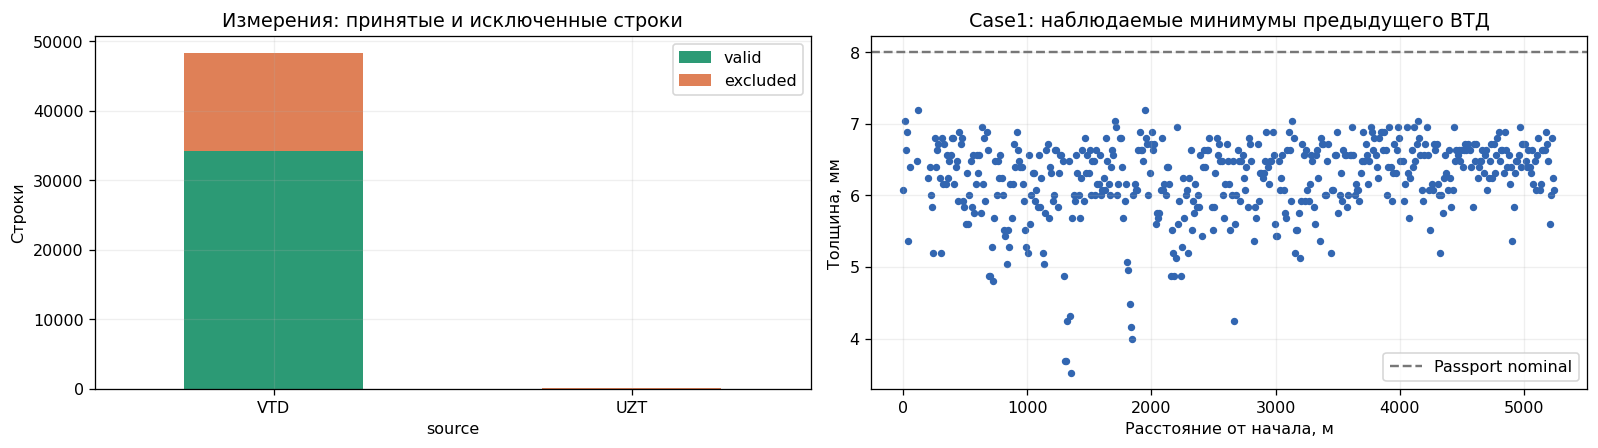

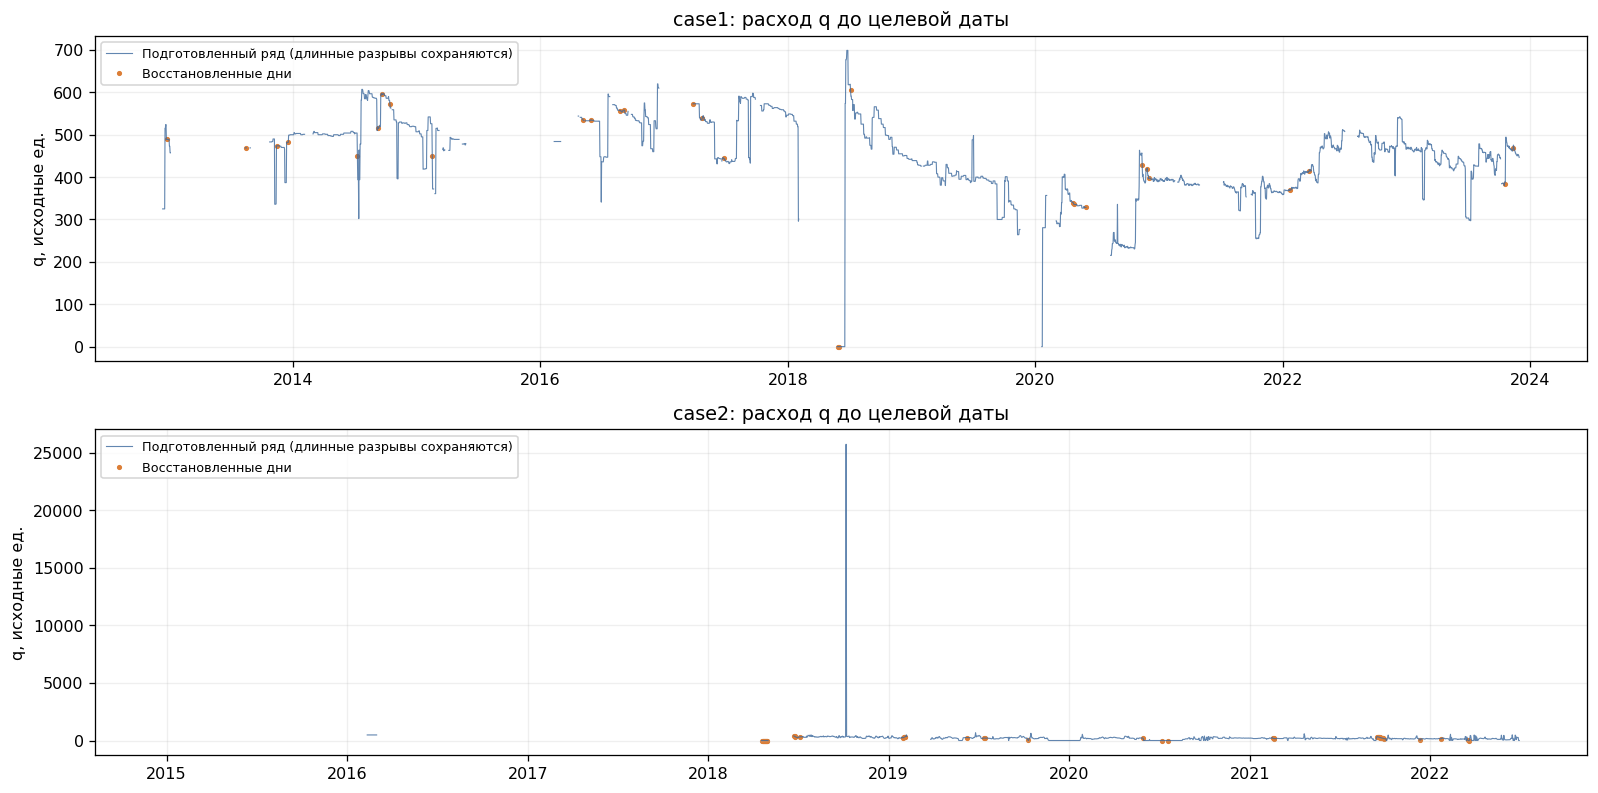

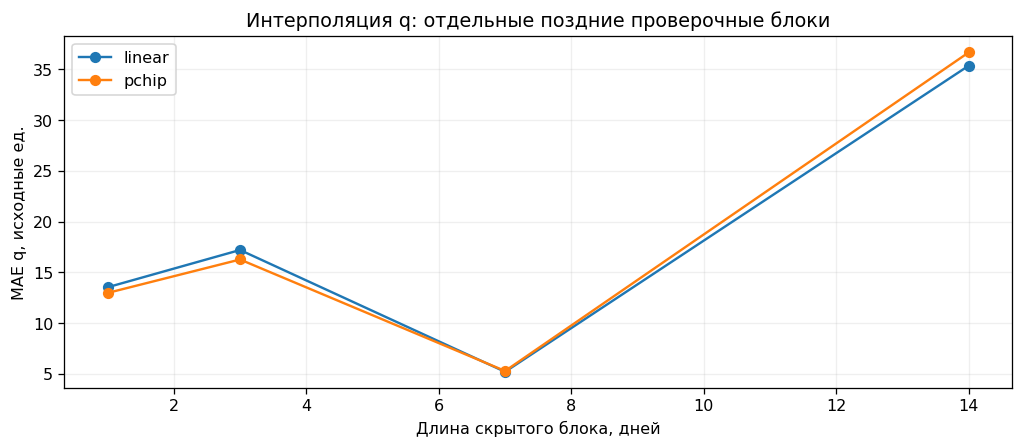

,cutoff,metric,method,max_gap_days,calibration_mae,validation_mae
16,2022-07-01,q,linear,14,27.617429,19.416238
17,2022-07-01,q_oil,linear,3,9.233333,14.203133
18,2022-07-01,q_gas,linear,14,0.312511,0.083233
19,2022-07-01,watercut,linear,14,0.350829,0.118838
20,2022-07-01,p_start,linear,14,0.403476,0.240613
21,2022-07-01,p_end,pchip,14,0.190219,0.653783
22,2022-07-01,v_liquid_true,pchip,7,0.015125,0.016301
23,2022-07-01,v_mix,pchip,3,0.008268,0.017370
24,2022-07-01,t_start,linear,14,0.340868,0.360666
25,2022-07-01,t_end,linear,14,0.169384,0.149949


Готово: обработанные источники, временные срезы, X/y, аудит и конфигурация находятся в processed/.


In [48]:
plt.rcParams.update({"figure.dpi": 115, "axes.grid": True, "grid.alpha": 0.2})
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
counts = pd.DataFrame({"source": ["VTD", "UZT"], "valid": [len(vtd_clean), len(uzt_clean)],
                       "excluded": [len(vtd_audited) - len(vtd_clean), len(uzt_audited) - len(uzt_clean)]}).set_index("source")
counts.plot.bar(stacked=True, ax=axes[0], color=["#2c9a75", "#df8057"], rot=0)
axes[0].set_title("Измерения: принятые и исключенные строки")
axes[0].set_ylabel("Строки")
case1x = prediction_features["case1"].sort_values("segment_id")
axes[1].scatter(case1x["mid_m"], case1x["previous_thickness_mm"], s=13, color="#3266b1")
axes[1].axhline(PM.loc[CFG["cases"]["case1"]["id"], "nominal_mm"], ls="--", color="#777777", label="Passport nominal")
axes[1].set(xlabel="Расстояние от начала, м", ylabel="Толщина, мм", title="Case1: наблюдаемые минимумы предыдущего ВТД")
axes[1].legend()
fig.tight_layout(); plt.show()

plot_data = pd.concat(case_plot_rows, ignore_index=True)
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=False)
for ax, case_name in zip(axes, ["case1", "case2"]):
    d = plot_data.loc[plot_data["case"].eq(case_name)].sort_values("date")
    ax.plot(d["date"], d["value"], lw=0.7, color="#3b689c", alpha=0.8, label="Подготовленный ряд (длинные разрывы сохраняются)")
    imputed = d["status"].eq("imputed")
    ax.scatter(d.loc[imputed, "date"], d.loc[imputed, "value"], s=5, color="#dc7e36", label="Восстановленные дни")
    ax.set(title=case_name + ": расход q до целевой даты", ylabel="q, исходные ед.")
    ax.legend(loc="upper left", fontsize=8)
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
last_cutoff = pd.Timestamp(CFG["cases"]["case1"]["target_date"])
b = benchmark_summary.loc[benchmark_summary["cutoff"].eq(last_cutoff) & benchmark_summary["metric"].eq("q") & benchmark_summary["pool"].eq("validation") & benchmark_summary["method"].isin(["linear", "pchip"])]
for method, g in b.groupby("method"):
    ax.plot(g["gap_length_days"], g["mae"], marker="o", label=method)
ax.set(xlabel="Длина скрытого блока, дней", ylabel="MAE q, исходные ед.", title="Интерполяция q: отдельные поздние проверочные блоки")
ax.legend(); fig.tight_layout(); plt.show()
display(interpolation_choices.loc[interpolation_choices["cutoff"].isin([pd.Timestamp(c["target_date"]) for c in CFG["cases"].values()]), ["cutoff", "metric", "method", "max_gap_days", "calibration_mae", "validation_mae"]])
print("Готово: обработанные источники, временные срезы, X/y, аудит и конфигурация находятся в processed/.")

## Модели

Case1: CatBoost + Transformer. Case2: LSTM + PCA + Ridge, ×1,15. Параметры фиксированы.

In [49]:
SELECTED_SPECS = {'case1': {'name': 'CatBoost_Transformer', 'kind': 'catboost', 'encoder': 'transformer', 'enhanced': False},
 'case2': {'name': 'Classic_LSTM_PCA_FE',
           'kind': 'automl',
           'encoder': 'lstm',
           'enhanced': True,
           'automl_include_catboost': False}}

FINAL_PARAMETERS = {'case1': {'tabular': {'kind': 'catboost',
                       'enhanced': False,
                       'feature_encoding': 'native',
                       'processor_cfg': {'constant_atol': 1e-12, 'constant_rtol': 1e-12},
                       'components': [{'slot': 0,
                                       'family': 'catboost',
                                       'parameters': {'depth': 8,
                                                      'iterations': 300,
                                                      'learning_rate': 0.14733909915740498,
                                                      'l2_leaf_reg': 13.010202862420458,
                                                      'bagging_temperature': 2.477980364120646},
                                       'weight': 1.0,
                                       'numeric_clip': 'none',
                                       'feature_encoding': 'native'}],
                       'compatibility_note': 'random_strength tuned on CPU only; GPU uses Bayesian bootstrap '
                                             'without rsm/subsample',
                       'selection': "configuration and ensemble weights chosen by the root's grouped inner "
                                    'Optuna objective'},
           'sequence': {'kind': 'transformer',
                        'latent_dim': 4,
                        'hidden_dim': 96,
                        'n_layers': 3,
                        'dropout': 0.2916665899741035,
                        'learning_rate': 0.00010349321278949146,
                        'weight_decay': 5.170064412133157e-06,
                        'mask_probability': 0.2745997325775053,
                        'epochs': 70,
                        'n_windows_per_episode': 2,
                        'min_window_steps': 30,
                        'n_heads': 8,
                        'max_seq_len': 60,
                        'force_math_attention': True,
                        'gap_age_cap_days': 3650,
                        'recency_scale_days': 1826.25,
                        'duration_scale_days': 31}},
 'case2': {'tabular': {'kind': 'automl',
                       'enhanced': True,
                       'feature_encoding': 'dense',
                       'processor_cfg': {'constant_atol': 1e-12,
                                         'constant_rtol': 1e-12,
                                         'pca_variance': 0.8700584668170085,
                                         'correlation_threshold': 0.9945588537606684},
                       'components': [{'slot': 0,
                                       'family': 'ridge',
                                       'parameters': {'alpha': 76852.36973874843},
                                       'weight': 1.0,
                                       'numeric_clip': 'train_q01',
                                       'feature_encoding': 'dense'}],
                       'compatibility_note': 'random_strength tuned on CPU only; GPU uses Bayesian bootstrap '
                                             'without rsm/subsample',
                       'selection': "configuration and ensemble weights chosen by the root's grouped inner "
                                    'Optuna objective'},
           'sequence': {'kind': 'lstm',
                        'latent_dim': 20,
                        'hidden_dim': 96,
                        'n_layers': 3,
                        'dropout': 0.2977087996381012,
                        'learning_rate': 0.0002564276929534843,
                        'weight_decay': 1.4300140469723322e-07,
                        'mask_probability': 0.3394815118118932,
                        'epochs': 80,
                        'n_windows_per_episode': 1,
                        'min_window_steps': 12,
                        'n_heads': 4,
                        'max_seq_len': 60,
                        'force_math_attention': True,
                        'gap_age_cap_days': 3650,
                        'recency_scale_days': 1826.25,
                        'duration_scale_days': 31}}}

EXPECTED_PREDICTORS = {'case1': ['start_m',
           'end_m',
           'mid_m',
           'segment_length_m',
           'position_fraction',
           'z_start_m',
           'z_end_m',
           'z_mid_m',
           'slope_m_per_m',
           'local_min_z_50m',
           'relative_to_local_min_50m',
           'local_low_index_50m',
           'has_relief',
           'length_m',
           'diameter_mm',
           'nominal_mm',
           'material',
           'internal_coating',
           'external_coating',
           'installation_mode',
           'soil_type',
           'previous_thickness_mm',
           'previous_measurements_count',
           'has_previous_thickness',
           'previous_loss_fraction',
           'older_thickness_mm',
           'previous_change_mm',
           'previous_change_rate_mm_per_year',
           'previous_minimum_increased',
           'has_older_thickness',
           'window_duration_days',
           'age_days',
           'age_years',
           'regime_window_duration_days',
           'regime_prehistory_missing_days',
           'regime__p_end__covered_duration_days',
           'regime__p_end__observed_duration_days',
           'regime__p_end__imputed_duration_days',
           'regime__p_end__missing_duration_days',
           'regime__p_end__integral',
           'regime__p_end__mean',
           'regime__p_end__std_timeweighted',
           'regime__p_end__coverage_ratio',
           'regime__p_end__min',
           'regime__p_end__max',
           'regime__p_end__prehistory_missing_days',
           'regime__p_end__available_era_coverage_ratio',
           'regime__p_end__last_30d_mean',
           'regime__p_end__last_30d_coverage_ratio',
           'regime__p_end__last_90d_mean',
           'regime__p_end__last_90d_coverage_ratio',
           'regime__p_end__last_365d_mean',
           'regime__p_end__last_365d_coverage_ratio',
           'regime__p_end__mean_abs_change',
           'regime__p_start__covered_duration_days',
           'regime__p_start__observed_duration_days',
           'regime__p_start__imputed_duration_days',
           'regime__p_start__missing_duration_days',
           'regime__p_start__integral',
           'regime__p_start__mean',
           'regime__p_start__std_timeweighted',
           'regime__p_start__coverage_ratio',
           'regime__p_start__min',
           'regime__p_start__max',
           'regime__p_start__prehistory_missing_days',
           'regime__p_start__available_era_coverage_ratio',
           'regime__p_start__last_30d_mean',
           'regime__p_start__last_30d_coverage_ratio',
           'regime__p_start__last_90d_mean',
           'regime__p_start__last_90d_coverage_ratio',
           'regime__p_start__last_365d_mean',
           'regime__p_start__last_365d_coverage_ratio',
           'regime__p_start__mean_abs_change',
           'regime__q__covered_duration_days',
           'regime__q__observed_duration_days',
           'regime__q__imputed_duration_days',
           'regime__q__missing_duration_days',
           'regime__q__integral',
           'regime__q__mean',
           'regime__q__std_timeweighted',
           'regime__q__coverage_ratio',
           'regime__q__min',
           'regime__q__max',
           'regime__q__prehistory_missing_days',
           'regime__q__available_era_coverage_ratio',
           'regime__q__last_30d_mean',
           'regime__q__last_30d_coverage_ratio',
           'regime__q__last_90d_mean',
           'regime__q__last_90d_coverage_ratio',
           'regime__q__last_365d_mean',
           'regime__q__last_365d_coverage_ratio',
           'regime__q__mean_abs_change',
           'regime__t_end__covered_duration_days',
           'regime__t_end__observed_duration_days',
           'regime__t_end__imputed_duration_days',
           'regime__t_end__missing_duration_days',
           'regime__t_end__integral',
           'regime__t_end__mean',
           'regime__t_end__std_timeweighted',
           'regime__t_end__coverage_ratio',
           'regime__t_end__min',
           'regime__t_end__max',
           'regime__t_end__prehistory_missing_days',
           'regime__t_end__available_era_coverage_ratio',
           'regime__t_end__last_30d_mean',
           'regime__t_end__last_30d_coverage_ratio',
           'regime__t_end__last_90d_mean',
           'regime__t_end__last_90d_coverage_ratio',
           'regime__t_end__last_365d_mean',
           'regime__t_end__last_365d_coverage_ratio',
           'regime__t_end__mean_abs_change',
           'regime__t_start__covered_duration_days',
           'regime__t_start__observed_duration_days',
           'regime__t_start__imputed_duration_days',
           'regime__t_start__missing_duration_days',
           'regime__t_start__integral',
           'regime__t_start__mean',
           'regime__t_start__std_timeweighted',
           'regime__t_start__coverage_ratio',
           'regime__t_start__min',
           'regime__t_start__max',
           'regime__t_start__prehistory_missing_days',
           'regime__t_start__available_era_coverage_ratio',
           'regime__t_start__last_30d_mean',
           'regime__t_start__last_30d_coverage_ratio',
           'regime__t_start__last_90d_mean',
           'regime__t_start__last_90d_coverage_ratio',
           'regime__t_start__last_365d_mean',
           'regime__t_start__last_365d_coverage_ratio',
           'regime__t_start__mean_abs_change',
           'regime__v_liquid_true__covered_duration_days',
           'regime__v_liquid_true__observed_duration_days',
           'regime__v_liquid_true__imputed_duration_days',
           'regime__v_liquid_true__missing_duration_days',
           'regime__v_liquid_true__integral',
           'regime__v_liquid_true__mean',
           'regime__v_liquid_true__std_timeweighted',
           'regime__v_liquid_true__coverage_ratio',
           'regime__v_liquid_true__min',
           'regime__v_liquid_true__max',
           'regime__v_liquid_true__prehistory_missing_days',
           'regime__v_liquid_true__available_era_coverage_ratio',
           'regime__v_liquid_true__last_30d_mean',
           'regime__v_liquid_true__last_30d_coverage_ratio',
           'regime__v_liquid_true__last_90d_mean',
           'regime__v_liquid_true__last_90d_coverage_ratio',
           'regime__v_liquid_true__last_365d_mean',
           'regime__v_liquid_true__last_365d_coverage_ratio',
           'regime__v_liquid_true__mean_abs_change',
           'regime__watercut__covered_duration_days',
           'regime__watercut__observed_duration_days',
           'regime__watercut__imputed_duration_days',
           'regime__watercut__missing_duration_days',
           'regime__watercut__integral',
           'regime__watercut__mean',
           'regime__watercut__std_timeweighted',
           'regime__watercut__coverage_ratio',
           'regime__watercut__min',
           'regime__watercut__max',
           'regime__watercut__prehistory_missing_days',
           'regime__watercut__available_era_coverage_ratio',
           'regime__watercut__last_30d_mean',
           'regime__watercut__last_30d_coverage_ratio',
           'regime__watercut__last_90d_mean',
           'regime__watercut__last_90d_coverage_ratio',
           'regime__watercut__last_365d_mean',
           'regime__watercut__last_365d_coverage_ratio',
           'regime__watercut__mean_abs_change',
           'raw_regime__q__integral_source_unit_days',
           'raw_regime__q__time_mean',
           'raw_regime__q__coverage_ratio',
           'raw_regime__watercut__integral_source_unit_days',
           'raw_regime__watercut__time_mean',
           'raw_regime__watercut__coverage_ratio',
           'raw_regime__p_start__integral_source_unit_days',
           'raw_regime__p_start__time_mean',
           'raw_regime__p_start__coverage_ratio',
           'raw_regime__p_end__integral_source_unit_days',
           'raw_regime__p_end__time_mean',
           'raw_regime__p_end__coverage_ratio',
           'raw_regime__v_liquid_true__integral_source_unit_days',
           'raw_regime__v_liquid_true__time_mean',
           'raw_regime__v_liquid_true__coverage_ratio',
           'raw_regime__t_start__integral_source_unit_days',
           'raw_regime__t_start__time_mean',
           'raw_regime__t_start__coverage_ratio',
           'raw_regime__t_end__integral_source_unit_days',
           'raw_regime__t_end__time_mean',
           'raw_regime__t_end__coverage_ratio',
           'regime_zero_pressure_positive_flow_ratio',
           'regime_extreme_pressure_ratio',
           'regime_temperature_floor_ratio',
           'regime_shutdown_record_fraction',
           'corrosion__average_rate',
           'corrosion__average_rate__has_value',
           'corrosion__maximum_rate',
           'corrosion__maximum_rate__has_value',
           'corrosion__ph',
           'corrosion__ph__has_value',
           'corrosion__mineralization',
           'corrosion__mineralization__has_value',
           'corrosion__co2_water',
           'corrosion__co2_water__has_value'],
 'case2': ['start_m',
           'end_m',
           'mid_m',
           'segment_length_m',
           'position_fraction',
           'z_start_m',
           'z_end_m',
           'z_mid_m',
           'slope_m_per_m',
           'local_min_z_50m',
           'relative_to_local_min_50m',
           'local_low_index_50m',
           'has_relief',
           'length_m',
           'diameter_mm',
           'nominal_mm',
           'material',
           'internal_coating',
           'external_coating',
           'installation_mode',
           'soil_type',
           'window_duration_days',
           'age_days',
           'age_years',
           'regime_window_duration_days',
           'regime_prehistory_missing_days',
           'regime__p_end__covered_duration_days',
           'regime__p_end__observed_duration_days',
           'regime__p_end__imputed_duration_days',
           'regime__p_end__missing_duration_days',
           'regime__p_end__integral',
           'regime__p_end__mean',
           'regime__p_end__std_timeweighted',
           'regime__p_end__coverage_ratio',
           'regime__p_end__min',
           'regime__p_end__max',
           'regime__p_end__prehistory_missing_days',
           'regime__p_end__available_era_coverage_ratio',
           'regime__p_end__last_30d_mean',
           'regime__p_end__last_30d_coverage_ratio',
           'regime__p_end__last_90d_mean',
           'regime__p_end__last_90d_coverage_ratio',
           'regime__p_end__last_365d_mean',
           'regime__p_end__last_365d_coverage_ratio',
           'regime__p_end__mean_abs_change',
           'regime__p_start__covered_duration_days',
           'regime__p_start__observed_duration_days',
           'regime__p_start__imputed_duration_days',
           'regime__p_start__missing_duration_days',
           'regime__p_start__integral',
           'regime__p_start__mean',
           'regime__p_start__std_timeweighted',
           'regime__p_start__coverage_ratio',
           'regime__p_start__min',
           'regime__p_start__max',
           'regime__p_start__prehistory_missing_days',
           'regime__p_start__available_era_coverage_ratio',
           'regime__p_start__last_30d_mean',
           'regime__p_start__last_30d_coverage_ratio',
           'regime__p_start__last_90d_mean',
           'regime__p_start__last_90d_coverage_ratio',
           'regime__p_start__last_365d_mean',
           'regime__p_start__last_365d_coverage_ratio',
           'regime__p_start__mean_abs_change',
           'regime__q__covered_duration_days',
           'regime__q__observed_duration_days',
           'regime__q__imputed_duration_days',
           'regime__q__missing_duration_days',
           'regime__q__integral',
           'regime__q__mean',
           'regime__q__std_timeweighted',
           'regime__q__coverage_ratio',
           'regime__q__min',
           'regime__q__max',
           'regime__q__prehistory_missing_days',
           'regime__q__available_era_coverage_ratio',
           'regime__q__last_30d_mean',
           'regime__q__last_30d_coverage_ratio',
           'regime__q__last_90d_mean',
           'regime__q__last_90d_coverage_ratio',
           'regime__q__last_365d_mean',
           'regime__q__last_365d_coverage_ratio',
           'regime__q__mean_abs_change',
           'regime__t_end__covered_duration_days',
           'regime__t_end__observed_duration_days',
           'regime__t_end__imputed_duration_days',
           'regime__t_end__missing_duration_days',
           'regime__t_end__integral',
           'regime__t_end__mean',
           'regime__t_end__std_timeweighted',
           'regime__t_end__coverage_ratio',
           'regime__t_end__min',
           'regime__t_end__max',
           'regime__t_end__prehistory_missing_days',
           'regime__t_end__available_era_coverage_ratio',
           'regime__t_end__last_30d_mean',
           'regime__t_end__last_30d_coverage_ratio',
           'regime__t_end__last_90d_mean',
           'regime__t_end__last_90d_coverage_ratio',
           'regime__t_end__last_365d_mean',
           'regime__t_end__last_365d_coverage_ratio',
           'regime__t_end__mean_abs_change',
           'regime__t_start__covered_duration_days',
           'regime__t_start__observed_duration_days',
           'regime__t_start__imputed_duration_days',
           'regime__t_start__missing_duration_days',
           'regime__t_start__integral',
           'regime__t_start__mean',
           'regime__t_start__std_timeweighted',
           'regime__t_start__coverage_ratio',
           'regime__t_start__min',
           'regime__t_start__max',
           'regime__t_start__prehistory_missing_days',
           'regime__t_start__available_era_coverage_ratio',
           'regime__t_start__last_30d_mean',
           'regime__t_start__last_30d_coverage_ratio',
           'regime__t_start__last_90d_mean',
           'regime__t_start__last_90d_coverage_ratio',
           'regime__t_start__last_365d_mean',
           'regime__t_start__last_365d_coverage_ratio',
           'regime__t_start__mean_abs_change',
           'regime__v_liquid_true__covered_duration_days',
           'regime__v_liquid_true__observed_duration_days',
           'regime__v_liquid_true__imputed_duration_days',
           'regime__v_liquid_true__missing_duration_days',
           'regime__v_liquid_true__integral',
           'regime__v_liquid_true__mean',
           'regime__v_liquid_true__std_timeweighted',
           'regime__v_liquid_true__coverage_ratio',
           'regime__v_liquid_true__min',
           'regime__v_liquid_true__max',
           'regime__v_liquid_true__prehistory_missing_days',
           'regime__v_liquid_true__available_era_coverage_ratio',
           'regime__v_liquid_true__last_30d_mean',
           'regime__v_liquid_true__last_30d_coverage_ratio',
           'regime__v_liquid_true__last_90d_mean',
           'regime__v_liquid_true__last_90d_coverage_ratio',
           'regime__v_liquid_true__last_365d_mean',
           'regime__v_liquid_true__last_365d_coverage_ratio',
           'regime__v_liquid_true__mean_abs_change',
           'regime__watercut__covered_duration_days',
           'regime__watercut__observed_duration_days',
           'regime__watercut__imputed_duration_days',
           'regime__watercut__missing_duration_days',
           'regime__watercut__integral',
           'regime__watercut__mean',
           'regime__watercut__std_timeweighted',
           'regime__watercut__coverage_ratio',
           'regime__watercut__min',
           'regime__watercut__max',
           'regime__watercut__prehistory_missing_days',
           'regime__watercut__available_era_coverage_ratio',
           'regime__watercut__last_30d_mean',
           'regime__watercut__last_30d_coverage_ratio',
           'regime__watercut__last_90d_mean',
           'regime__watercut__last_90d_coverage_ratio',
           'regime__watercut__last_365d_mean',
           'regime__watercut__last_365d_coverage_ratio',
           'regime__watercut__mean_abs_change',
           'raw_regime__q__integral_source_unit_days',
           'raw_regime__q__time_mean',
           'raw_regime__q__coverage_ratio',
           'raw_regime__watercut__integral_source_unit_days',
           'raw_regime__watercut__time_mean',
           'raw_regime__watercut__coverage_ratio',
           'raw_regime__p_start__integral_source_unit_days',
           'raw_regime__p_start__time_mean',
           'raw_regime__p_start__coverage_ratio',
           'raw_regime__p_end__integral_source_unit_days',
           'raw_regime__p_end__time_mean',
           'raw_regime__p_end__coverage_ratio',
           'raw_regime__v_liquid_true__integral_source_unit_days',
           'raw_regime__v_liquid_true__time_mean',
           'raw_regime__v_liquid_true__coverage_ratio',
           'raw_regime__t_start__integral_source_unit_days',
           'raw_regime__t_start__time_mean',
           'raw_regime__t_start__coverage_ratio',
           'raw_regime__t_end__integral_source_unit_days',
           'raw_regime__t_end__time_mean',
           'raw_regime__t_end__coverage_ratio',
           'regime_zero_pressure_positive_flow_ratio',
           'regime_extreme_pressure_ratio',
           'regime_temperature_floor_ratio',
           'regime_shutdown_record_fraction',
           'corrosion__average_rate',
           'corrosion__average_rate__has_value',
           'corrosion__maximum_rate',
           'corrosion__maximum_rate__has_value',
           'corrosion__ph',
           'corrosion__ph__has_value',
           'corrosion__mineralization',
           'corrosion__mineralization__has_value',
           'corrosion__co2_water',
           'corrosion__co2_water__has_value']}

DEVELOPMENT_TRAIN_FINGERPRINTS = {'case1': 'bf3561eb1ae33bb5f4b0f09f6ac7b69e50430fda54731f40ef95b408385b135f',
 'case2': 'dcc524ceb440a71f8c1b067898f25be6303d5e8e51c778420f71f797fbe622b0'}

FROZEN_OUTER = {'case1': [{'fold': 1,
            'validation_id': 1250009490,
            'params': {'tabular': {'kind': 'catboost',
                                   'enhanced': False,
                                   'feature_encoding': 'dense',
                                   'processor_cfg': {'constant_atol': 1e-12, 'constant_rtol': 1e-12},
                                   'components': [{'slot': 0,
                                                   'family': 'catboost',
                                                   'parameters': {'depth': 5,
                                                                  'iterations': 550,
                                                                  'learning_rate': 0.01043618036784586,
                                                                  'l2_leaf_reg': 3.637292772198825,
                                                                  'bagging_temperature': 4.067131454071586},
                                                   'weight': 1.0,
                                                   'numeric_clip': 'none',
                                                   'feature_encoding': 'dense'}],
                                   'compatibility_note': 'random_strength tuned on CPU only; GPU uses '
                                                         'Bayesian bootstrap without rsm/subsample',
                                   'selection': "configuration and ensemble weights chosen by the root's "
                                                'grouped inner Optuna objective'},
                       'sequence': {'kind': 'transformer',
                                    'latent_dim': 8,
                                    'hidden_dim': 64,
                                    'n_layers': 1,
                                    'dropout': 0.12620612959415226,
                                    'learning_rate': 0.00023127830608358742,
                                    'weight_decay': 1.965115912792293e-05,
                                    'mask_probability': 0.1171008005772737,
                                    'epochs': 80,
                                    'n_windows_per_episode': 1,
                                    'min_window_steps': 30,
                                    'n_heads': 8,
                                    'max_seq_len': 60,
                                    'force_math_attention': True,
                                    'gap_age_cap_days': 3650,
                                    'recency_scale_days': 1826.25,
                                    'duration_scale_days': 31}}},
           {'fold': 2,
            'validation_id': 1250011604,
            'params': {'tabular': {'kind': 'catboost',
                                   'enhanced': False,
                                   'feature_encoding': 'native',
                                   'processor_cfg': {'constant_atol': 1e-12, 'constant_rtol': 1e-12},
                                   'components': [{'slot': 0,
                                                   'family': 'catboost',
                                                   'parameters': {'depth': 6,
                                                                  'iterations': 350,
                                                                  'learning_rate': 0.18258230439200238,
                                                                  'l2_leaf_reg': 35.50304858128308,
                                                                  'bagging_temperature': 4.697494707820946},
                                                   'weight': 1.0,
                                                   'numeric_clip': 'none',
                                                   'feature_encoding': 'native'}],
                                   'compatibility_note': 'random_strength tuned on CPU only; GPU uses '
                                                         'Bayesian bootstrap without rsm/subsample',
                                   'selection': "configuration and ensemble weights chosen by the root's "
                                                'grouped inner Optuna objective'},
                       'sequence': {'kind': 'transformer',
                                    'latent_dim': 24,
                                    'hidden_dim': 64,
                                    'n_layers': 1,
                                    'dropout': 0.0975990992289793,
                                    'learning_rate': 0.00037507963596256056,
                                    'weight_decay': 2.273762810253687e-06,
                                    'mask_probability': 0.34862125274557887,
                                    'epochs': 50,
                                    'n_windows_per_episode': 2,
                                    'min_window_steps': 24,
                                    'n_heads': 4,
                                    'max_seq_len': 60,
                                    'force_math_attention': True,
                                    'gap_age_cap_days': 3650,
                                    'recency_scale_days': 1826.25,
                                    'duration_scale_days': 31}}},
           {'fold': 3,
            'validation_id': 1250022871,
            'params': {'tabular': {'kind': 'catboost',
                                   'enhanced': False,
                                   'feature_encoding': 'dense',
                                   'processor_cfg': {'constant_atol': 1e-12, 'constant_rtol': 1e-12},
                                   'components': [{'slot': 0,
                                                   'family': 'catboost',
                                                   'parameters': {'depth': 5,
                                                                  'iterations': 1000,
                                                                  'learning_rate': 0.11213457399910592,
                                                                  'l2_leaf_reg': 58.47091113947772,
                                                                  'bagging_temperature': 3.9578163796321317},
                                                   'weight': 1.0,
                                                   'numeric_clip': 'none',
                                                   'feature_encoding': 'dense'}],
                                   'compatibility_note': 'random_strength tuned on CPU only; GPU uses '
                                                         'Bayesian bootstrap without rsm/subsample',
                                   'selection': "configuration and ensemble weights chosen by the root's "
                                                'grouped inner Optuna objective'},
                       'sequence': {'kind': 'transformer',
                                    'latent_dim': 4,
                                    'hidden_dim': 32,
                                    'n_layers': 2,
                                    'dropout': 0.2674277122196528,
                                    'learning_rate': 0.001138690184767768,
                                    'weight_decay': 0.00015284221900000274,
                                    'mask_probability': 0.2725042713828139,
                                    'epochs': 30,
                                    'n_windows_per_episode': 5,
                                    'min_window_steps': 36,
                                    'n_heads': 8,
                                    'max_seq_len': 60,
                                    'force_math_attention': True,
                                    'gap_age_cap_days': 3650,
                                    'recency_scale_days': 1826.25,
                                    'duration_scale_days': 31}}}],
 'case2': [{'fold': 1,
            'validation_id': 1250009490,
            'params': {'tabular': {'kind': 'automl',
                                   'enhanced': True,
                                   'feature_encoding': 'dense',
                                   'processor_cfg': {'constant_atol': 1e-12,
                                                     'constant_rtol': 1e-12,
                                                     'pca_variance': 0.8652021709934131,
                                                     'correlation_threshold': 0.982866754258086},
                                   'components': [{'slot': 0,
                                                   'family': 'ridge',
                                                   'parameters': {'alpha': 2713.2592279456107},
                                                   'weight': 1.0,
                                                   'numeric_clip': 'train_q01',
                                                   'feature_encoding': 'dense'}],
                                   'compatibility_note': 'random_strength tuned on CPU only; GPU uses '
                                                         'Bayesian bootstrap without rsm/subsample',
                                   'selection': "configuration and ensemble weights chosen by the root's "
                                                'grouped inner Optuna objective'},
                       'sequence': {'kind': 'lstm',
                                    'latent_dim': 20,
                                    'hidden_dim': 96,
                                    'n_layers': 3,
                                    'dropout': 0.29311615041024375,
                                    'learning_rate': 0.0002614009340458019,
                                    'weight_decay': 1.0254567216938842e-07,
                                    'mask_probability': 0.34090925090326235,
                                    'epochs': 90,
                                    'n_windows_per_episode': 1,
                                    'min_window_steps': 12,
                                    'n_heads': 4,
                                    'max_seq_len': 60,
                                    'force_math_attention': True,
                                    'gap_age_cap_days': 3650,
                                    'recency_scale_days': 1826.25,
                                    'duration_scale_days': 31}}},
           {'fold': 2,
            'validation_id': 1250011604,
            'params': {'tabular': {'kind': 'automl',
                                   'enhanced': True,
                                   'feature_encoding': 'dense',
                                   'processor_cfg': {'constant_atol': 1e-12,
                                                     'constant_rtol': 1e-12,
                                                     'pca_variance': 0.8634666061795835,
                                                     'correlation_threshold': 0.9985046816115676},
                                   'components': [{'slot': 0,
                                                   'family': 'ridge',
                                                   'parameters': {'alpha': 98867.67916627745},
                                                   'weight': 1.0,
                                                   'numeric_clip': 'train_q01',
                                                   'feature_encoding': 'dense'}],
                                   'compatibility_note': 'random_strength tuned on CPU only; GPU uses '
                                                         'Bayesian bootstrap without rsm/subsample',
                                   'selection': "configuration and ensemble weights chosen by the root's "
                                                'grouped inner Optuna objective'},
                       'sequence': {'kind': 'lstm',
                                    'latent_dim': 24,
                                    'hidden_dim': 96,
                                    'n_layers': 2,
                                    'dropout': 0.27745454550557463,
                                    'learning_rate': 0.00024696458224444376,
                                    'weight_decay': 1.0273057186319039e-07,
                                    'mask_probability': 0.32892793786074404,
                                    'epochs': 70,
                                    'n_windows_per_episode': 1,
                                    'min_window_steps': 12,
                                    'n_heads': 4,
                                    'max_seq_len': 60,
                                    'force_math_attention': True,
                                    'gap_age_cap_days': 3650,
                                    'recency_scale_days': 1826.25,
                                    'duration_scale_days': 31}}},
           {'fold': 3,
            'validation_id': 1250022871,
            'params': {'tabular': {'kind': 'automl',
                                   'enhanced': True,
                                   'feature_encoding': 'dense',
                                   'processor_cfg': {'constant_atol': 1e-12,
                                                     'constant_rtol': 1e-12,
                                                     'pca_variance': 0.8806605292173263,
                                                     'correlation_threshold': 0.9017782256858672},
                                   'components': [{'slot': 0,
                                                   'family': 'extra_trees',
                                                   'parameters': {'n_estimators': 600,
                                                                  'max_depth': None,
                                                                  'min_samples_leaf': 1,
                                                                  'max_features': 0.7180626453792741},
                                                   'weight': 1.0,
                                                   'numeric_clip': 'none',
                                                   'feature_encoding': 'dense'}],
                                   'compatibility_note': 'random_strength tuned on CPU only; GPU uses '
                                                         'Bayesian bootstrap without rsm/subsample',
                                   'selection': "configuration and ensemble weights chosen by the root's "
                                                'grouped inner Optuna objective'},
                       'sequence': {'kind': 'lstm',
                                    'latent_dim': 24,
                                    'hidden_dim': 64,
                                    'n_layers': 3,
                                    'dropout': 0.283742915992114,
                                    'learning_rate': 0.00010849054564006614,
                                    'weight_decay': 4.7075645617360297e-07,
                                    'mask_probability': 0.3405879418181764,
                                    'epochs': 70,
                                    'n_windows_per_episode': 1,
                                    'min_window_steps': 12,
                                    'n_heads': 4,
                                    'max_seq_len': 60,
                                    'force_math_attention': True,
                                    'gap_age_cap_days': 3650,
                                    'recency_scale_days': 1826.25,
                                    'duration_scale_days': 31}}}]}

In [50]:
PROCESSED = OUT_DIR
PREP_CFG = copy.deepcopy(CFG)
PREPROCESSING_CHECKS = copy.deepcopy(checks)
FEATURE_ROLES = pd.read_csv(PROCESSED / "audit/feature_roles.csv")
PASSPORT = pd.read_parquet(PROCESSED / "clean/passport.parquet")
REGIME_RAW = pd.read_parquet(PROCESSED / "clean/regime_observed.parquet")
JOIN_KEYS = ["episode_id", "id", "segment_id"]
TARGET = "target_thickness_mm"
CASES, INPUT_HASHES = {}, {}
for case_name, settings in PREP_CFG["cases"].items():
    folder = PROCESSED / "cases" / case_name
    x = pd.read_parquet(folder / "X_train.parquet")
    y = pd.read_parquet(folder / "y_train.parquet")
    predict = pd.read_parquet(folder / "X_predict.parquet")
    for frame in [x, y, predict]:
        if frame.duplicated(JOIN_KEYS).any():
            raise ValueError("Повторяющиеся ключи " + case_name)
    data = x.merge(y[JOIN_KEYS + [TARGET]], on=JOIN_KEYS, how="left", validate="one_to_one", indicator=True)
    if not data["_merge"].eq("both").all() or len(data) != len(y):
        raise ValueError("X/y не совпадают " + case_name)
    data = data.drop(columns="_merge").reset_index(drop=True)  # порядок строк исходного X сохраняется
    if not np.isfinite(data[TARGET]).all() or not data[TARGET].gt(0).all() or not data[TARGET].le(data["nominal_mm"] + 1e-8).all():
        raise ValueError("Некорректные наблюдаемые метки")
    T = pd.Timestamp(settings["target_date"])
    if not pd.to_datetime(data["target_date"]).lt(T).all() or not pd.to_datetime(y["label_available_date"]).lt(T).all():
        raise ValueError("Метки train недоступны до прогнозной даты")
    if not pd.to_datetime(data["feature_cutoff"]).eq(pd.to_datetime(data["target_date"])).all():
        raise ValueError("Несогласованное временное отсечение train")
    if not predict["id"].eq(int(settings["id"])).all() or not pd.to_datetime(predict["target_date"]).eq(T).all():
        raise ValueError("Другой прогнозный участок/дата")
    predictors = FEATURE_ROLES.loc[FEATURE_ROLES["case"].eq(case_name) & FEATURE_ROLES["role"].eq("candidate_predictor"), "column"].tolist()
    if predictors != EXPECTED_PREDICTORS[case_name] or not all(c in x and c in predict for c in predictors):
        raise ValueError("Схема признаков отличается от выбранной модели: " + case_name)
    forbidden = {TARGET, "id", "segment_id", "main_id", "direction_id", "episode_id", "has_label", "n_measurements",
                 "target_remaining_fraction", "min_source_record", "pit_corrosion_intensity", "p_start_fact", "p_end_fact"}
    if forbidden.intersection(predictors):
        raise ValueError("В предикторы попала метка/идентификатор/запрещённая величина")
    if case_name == "case2" and any(c.startswith(("previous_", "older_")) or c in {"has_previous_thickness", "has_older_thickness"} for c in predictors):
        raise ValueError("В cold-start попали собственные замеры толщины")
    CASES[case_name] = {"data": data, "predict": predict, "predictors": predictors, "settings": settings}
    print(case_name, ": train", len(data), "; участков", data["id"].nunique(), "; прогноз", len(predict), "; признаков", len(predictors))
for path in [PROCESSED / "config.json", PROCESSED / "audit/feature_roles.csv", PROCESSED / "clean/passport.parquet",
             PROCESSED / "clean/regime_observed.parquet", *[PROCESSED / "cases" / c / n for c in CASES for n in ["X_train.parquet", "y_train.parquet", "X_predict.parquet"]]]:
    INPUT_HASHES["processed/" + path.relative_to(PROCESSED).as_posix()] = hashlib.sha256(path.read_bytes()).hexdigest()
save_json(RUN_DIR / "input_hashes.json", INPUT_HASHES)
save_json(RUN_DIR / "selected_parameters.json", {"specs": SELECTED_SPECS, "final": FINAL_PARAMETERS})
save_json(RUN_DIR / "training_config.json", TRAIN_CFG)

case1 : train 561 ; участков 3 ; прогноз 525 ; признаков 203
case2 : train 372 ; участков 3 ; прогноз 1475 ; признаков 194


### Вспомогательные функции

In [51]:
from pathlib import Path
import copy
import gc
import json
import random
import warnings
import numpy as np
import pandas as pd
from scipy.interpolate import PchipInterpolator
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from threadpoolctl import threadpool_limits
from catboost import CatBoostRegressor, CatBoostError
import torch
from torch import nn
from torch.nn.attention import SDPBackend, sdpa_kernel
import cloudpickle


In [52]:
# Pure extracted definitions from source cell 5; no source notebook execution.
DEFAULT_REGIME_METRICS = ['q', 'q_oil', 'q_gas', 'watercut', 'p_start', 'p_end', 'v_liquid_true', 'v_mix', 't_start', 't_end', 't_mix', 'density_liquid_work', 'viscosity_liquid_work', 'density_oil', 'gas_content_rate', 'fill_coefficient']


TEMPORAL_DEFAULTS = {'regime_metrics': DEFAULT_REGIME_METRICS, 'daily_aggregation': 'median', 'interpolation_gap_candidates': [1, 3, 7, 14], 'interpolation_blocks_per_pool': 5, 'interpolation_min_calibration_blocks': 3, 'interpolation_calibration_fraction': 0.7, 'interpolation_max_normalized_mae': 0.15, 'pchip_min_relative_improvement': 0.05, 'seed': 42}


def temporal_setting(cfg, key):
    return cfg.get(key, TEMPORAL_DEFAULTS[key])


def build_daily_regime(regime, passport, cutoff, cfg):
    """Return complete daily calendars from first available row to exact cutoff.

    A calendar label is midnight; values are medians of source rows of that day.
    For a midnight target cutoff, later calculations on that same day are excluded.
    No calendar is manufactured for the unknown period before the first source row.
    """
    cutoff = pd.Timestamp(cutoff)
    metrics = [m for m in temporal_setting(cfg, 'regime_metrics') if m in regime]
    meta = passport.set_index('id')
    d = regime.loc[regime['id'].isin(meta.index) & regime['date'].notna() & regime['date'].le(cutoff)].copy()
    commissioned = d['id'].map(meta['commissioned'])
    d = d.loc[commissioned.notna() & d['date'].ge(commissioned)].copy()
    empty_cols = ['id', 'date', *metrics, 'n_source_records', 'source_min_date', 'source_max_date']
    if d.empty:
        return pd.DataFrame(columns=empty_cols)
    for metric in metrics:
        d[metric] = pd.to_numeric(d[metric], errors='coerce').replace([np.inf, -np.inf], np.nan)
    d['day'] = d['date'].dt.normalize()
    group = d.groupby(['id', 'day'], sort=True)
    if temporal_setting(cfg, 'daily_aggregation') == 'median':
        wide = group[metrics].median()
    elif temporal_setting(cfg, 'daily_aggregation') == 'last':
        last = d.sort_values(['date', 'source_record']).groupby(['id', 'day'], sort=True).tail(1)
        wide = last.set_index(['id', 'day'])[metrics]
    else:
        raise ValueError('daily_aggregation must be median or last')
    for metric in metrics:
        wide[metric + '__min'] = group[metric].min()
        wide[metric + '__max'] = group[metric].max()
        wide[metric + '__count'] = group[metric].count()
    wide['n_source_records'] = group.size()
    wide['source_min_date'] = group['date'].min()
    wide['source_max_date'] = group['date'].max()
    if 'flow_regime_real' in d:
        category_counts = d.dropna(subset=['flow_regime_real']).groupby(['id', 'day', 'flow_regime_real'], observed=True).size().rename('n').reset_index()
        modes = category_counts.sort_values(['n', 'flow_regime_real'], ascending=[False, True]).drop_duplicates(['id', 'day']).set_index(['id', 'day'])['flow_regime_real']
        wide['flow_regime_real'] = modes
    pieces = []
    for sid, frame in wide.groupby(level=0, sort=True):
        part = frame.droplevel(0).sort_index()
        calendar = pd.date_range(part.index.min(), cutoff.normalize(), freq='D', name='date')
        part = part.reindex(calendar)
        part['id'] = int(sid)
        part['n_source_records'] = part['n_source_records'].fillna(0).astype('int64')
        for metric in metrics:
            part[metric + '__count'] = part[metric + '__count'].fillna(0).astype('int64')
        part['has_source_record'] = part['n_source_records'].gt(0)
        pieces.append(part.reset_index())
    result = pd.concat(pieces, ignore_index=True)
    result['id'] = result['id'].astype('Int64')
    result['as_of_date'] = cutoff
    assert not result.duplicated(['id', 'date']).any()
    assert result['source_max_date'].dropna().le(cutoff).all()
    return result.sort_values(['id', 'date']).reset_index(drop=True)


def _missing_runs(mask):
    """Yield inclusive positional starts and ends of all True runs."""
    padded = np.r_[False, np.asarray(mask, dtype=bool), False].astype(np.int8)
    boundaries = np.flatnonzero(np.diff(padded))
    return list(zip(boundaries[::2], boundaries[1::2] - 1))


def _predict_one_gap(index, values, observed_positions, a, b, method, max_gap_days):
    """Use local anchors; do not take a PCHIP neighbour across another long gap."""
    left, right = (a - 1, b + 1)
    x = index.asi8.astype(float) / (86400 * 1000000000.0)
    if method == 'linear':
        return (np.interp(x[a:b + 1], x[[left, right]], values[[left, right]]), 'linear')
    oi = np.flatnonzero(observed_positions == left)
    if not len(oi):
        raise AssertionError('Missing left interpolation anchor')
    k = int(oi[0])
    candidates = [left, right]
    if k > 0:
        p = int(observed_positions[k - 1])
        if (index[left] - index[p]).total_seconds() / 86400 - 1 <= max_gap_days:
            candidates.insert(0, p)
    if k + 2 < len(observed_positions):
        n = int(observed_positions[k + 2])
        if (index[n] - index[right]).total_seconds() / 86400 - 1 <= max_gap_days:
            candidates.append(n)
    if len(candidates) < 4:
        return (np.interp(x[a:b + 1], x[[left, right]], values[[left, right]]), 'linear_fallback')
    fitted = PchipInterpolator(x[candidates], values[candidates], extrapolate=False)
    return (np.asarray(fitted(x[a:b + 1]), dtype=float), 'pchip')


def bounded_interpolate_series(series, method='linear', max_gap_days=3):
    """Fill only whole, bounded short daily gaps; preserve all observed values."""
    if method not in {'none', 'linear', 'pchip'}:
        raise ValueError('Unknown interpolation method: ' + str(method))
    s = pd.to_numeric(series.copy(), errors='coerce').astype(float)
    index = pd.DatetimeIndex(s.index)
    if index.has_duplicates or not index.is_monotonic_increasing:
        raise ValueError('Interpolation requires ordered unique daily dates')
    if len(index) and (not index.equals(pd.date_range(index[0], index[-1], freq='D'))):
        raise ValueError('Interpolation requires a complete daily calendar')
    values = s.to_numpy(copy=True)
    observed = np.isfinite(values)
    values[~observed] = np.nan
    status = np.where(observed, 'observed', 'missing').astype(object)
    methods = np.where(observed, 'observed', 'none').astype(object)
    gap_length = np.zeros(len(s), dtype=int)
    obs_pos = np.flatnonzero(observed)
    for a, b in _missing_runs(~observed):
        n = int(b - a + 1)
        gap_length[a:b + 1] = n
        bounded = a > 0 and b < len(s) - 1 and observed[a - 1] and observed[b + 1]
        if not bounded or method == 'none' or n > int(max_gap_days):
            continue
        predicted, actual_method = _predict_one_gap(index, values, obs_pos, a, b, method, int(max_gap_days))
        if not np.isfinite(predicted).all():
            continue
        values[a:b + 1] = predicted
        status[a:b + 1] = 'imputed'
        methods[a:b + 1] = actual_method
    result = pd.DataFrame({'value': values, 'status': status, 'method': methods, 'gap_length_days': gap_length}, index=index)
    result.index.name = 'date'
    assert np.array_equal(result.loc[observed, 'value'].to_numpy(), s.to_numpy()[observed])
    return result


def _physical_violations(metric, values):
    arr = np.asarray(values, dtype=float)
    finite = np.isfinite(arr)
    if metric == 'watercut':
        return int(((arr < 0) | (arr > 100))[finite].sum())
    nonnegative = {'q', 'q_oil', 'q_gas', 'v_liquid_true', 'v_mix', 'density_liquid_work', 'density_oil', 'viscosity_liquid_work', 'gas_content_rate', 'fill_coefficient'}
    return int((arr[finite] < 0).sum()) if metric in nonnegative else 0


def evaluate_interpolation(daily, cfg):
    """Block masking with chronological calibration and independent audit pools.

    Candidates contain two measured neighbours on both sides. Selection uses only
    calibration scores. Later validation scores are reported, never used to select.
    """
    metrics = [m for m in temporal_setting(cfg, 'regime_metrics') if m in daily]
    lengths = sorted(set((int(x) for x in temporal_setting(cfg, 'interpolation_gap_candidates'))))
    n_blocks = int(temporal_setting(cfg, 'interpolation_blocks_per_pool'))
    fraction = float(temporal_setting(cfg, 'interpolation_calibration_fraction'))
    seed = int(temporal_setting(cfg, 'seed'))
    detail_rows = []
    calibration_scales = {}
    if daily.empty:
        return (pd.DataFrame(), pd.DataFrame(), pd.DataFrame(columns=['metric', 'method', 'max_gap_days']))
    by_id = {int(sid): g.sort_values('date').set_index('date') for sid, g in daily.groupby('id')}
    for metric in metrics:
        earlier_values = []
        calendars = {}
        section_scales = {}
        for sid, frame in by_id.items():
            if metric not in frame:
                continue
            y = pd.to_numeric(frame[metric], errors='coerce').to_numpy(dtype=float)
            split = max(1, min(len(y) - 1, int(np.floor(len(y) * fraction))))
            calendars[sid] = (frame.index, y, split)
            local_cal = y[:split][np.isfinite(y[:split])]
            earlier_values.extend(local_cal.tolist())
            section_scales[sid] = max(float(np.quantile(local_cal, 0.75) - np.quantile(local_cal, 0.25)), float(np.std(local_cal)), abs(float(np.median(local_cal))) * 0.1, 1e-12) if len(local_cal) else np.nan
        cal = np.asarray(earlier_values, dtype=float)
        if len(cal):
            iqr = float(np.quantile(cal, 0.75) - np.quantile(cal, 0.25))
            calibration_scales[metric] = max(iqr, float(np.std(cal)), abs(float(np.median(cal))) * 0.1, 1e-12)
        else:
            calibration_scales[metric] = np.nan
        for length in lengths:
            for pool in ['calibration', 'validation']:
                candidates = []
                for sid, (dates, y, split) in calendars.items():
                    width = length + 4
                    if len(y) < width:
                        continue
                    complete = np.convolve(np.isfinite(y).astype(int), np.ones(width, dtype=int), mode='valid') == width
                    for window_start in np.flatnonzero(complete):
                        a = int(window_start + 2)
                        b = a + length - 1
                        if pool == 'calibration' and b + 2 < split:
                            candidates.append((sid, a, b))
                        elif pool == 'validation' and a - 2 >= split:
                            candidates.append((sid, a, b))
                rng = np.random.default_rng(seed + sum((ord(ch) for ch in metric)) + length * 97 + (0 if pool == 'calibration' else 100003))
                if candidates:
                    candidates = [candidates[i] for i in rng.permutation(len(candidates))]
                selected, intervals, seen_ids = ([], {}, set())
                for prefer_new in [True, False]:
                    for sid, a, b in candidates:
                        if len(selected) >= n_blocks:
                            break
                        if prefer_new and sid in seen_ids:
                            continue
                        if any((not (b + 2 < lo or a - 2 > hi) for lo, hi in intervals.get(sid, []))):
                            continue
                        selected.append((sid, a, b))
                        seen_ids.add(sid)
                        intervals.setdefault(sid, []).append((a - 2, b + 2))
                    if len(selected) >= n_blocks:
                        break
                for number, (sid, a, b) in enumerate(selected, 1):
                    dates, y, _ = calendars[sid]
                    local = pd.Series(y[a - 2:b + 3].copy(), index=dates[a - 2:b + 3])
                    truth = y[a:b + 1].copy()
                    for method in ['none', 'linear', 'pchip']:
                        masked = local.copy()
                        masked.iloc[2:2 + length] = np.nan
                        pred = bounded_interpolate_series(masked, method, length)['value'].iloc[2:2 + length].to_numpy()
                        finite = np.isfinite(pred)
                        err = pred[finite] - truth[finite]
                        true_curve = np.r_[y[a - 1], truth, y[b + 1]]
                        pred_curve = np.r_[y[a - 1], pred, y[b + 1]]
                        true_integral = float(np.trapz(true_curve, dx=1.0))
                        pred_integral = float(np.trapz(pred_curve, dx=1.0)) if finite.all() else np.nan
                        detail_rows.append({'metric': metric, 'gap_length_days': length, 'pool': pool, 'method': method, 'id': sid, 'block_number': number, 'hidden_start': dates[a], 'hidden_end': dates[b], 'left_anchor': dates[a - 1], 'right_anchor': dates[b + 1], 'mae': float(np.mean(np.abs(err))) if len(err) else np.nan, 'rmse': float(np.sqrt(np.mean(err ** 2))) if len(err) else np.nan, 'integral_abs_error': abs(pred_integral - true_integral) if np.isfinite(pred_integral) else np.nan, 'true_integral': true_integral, 'predicted_integral': pred_integral, 'filled_fraction': float(finite.mean()), 'range_violations': _physical_violations(metric, pred), 'calibration_scale': section_scales[sid], 'normalized_mae': float(np.mean(np.abs(err))) / section_scales[sid] if len(err) else np.nan})
    details = pd.DataFrame(detail_rows)
    summary_cols = ['metric', 'gap_length_days', 'pool', 'method', 'n_blocks', 'mae', 'rmse', 'integral_abs_error', 'filled_fraction', 'range_violations', 'normalized_mae']
    if details.empty:
        summary = pd.DataFrame(columns=summary_cols)
    else:
        summary = details.groupby(['metric', 'gap_length_days', 'pool', 'method'], as_index=False).agg(n_blocks=('mae', 'size'), mae=('mae', 'mean'), rmse=('rmse', 'mean'), integral_abs_error=('integral_abs_error', 'mean'), filled_fraction=('filled_fraction', 'mean'), range_violations=('range_violations', 'sum'), calibration_scale=('calibration_scale', 'mean'), normalized_mae=('normalized_mae', 'mean'))
    selected_rows = []
    min_blocks = int(temporal_setting(cfg, 'interpolation_min_calibration_blocks'))
    max_nmae = float(temporal_setting(cfg, 'interpolation_max_normalized_mae'))
    relative_gain = float(temporal_setting(cfg, 'pchip_min_relative_improvement'))
    for metric in metrics:
        cal = summary.loc[summary['metric'].eq(metric) & summary['pool'].eq('calibration')] if len(summary) else summary
        chosen = {'metric': metric, 'method': 'none', 'max_gap_days': 0, 'selection_reason': 'insufficient_or_inaccurate_calibration', 'calibration_mae': np.nan, 'validation_mae': np.nan, 'n_calibration_blocks': 0, 'n_validation_blocks': 0, 'max_normalized_mae_threshold': max_nmae, 'pchip_relative_gain_threshold': relative_gain}
        eligible_lengths = []
        for length in lengths:
            candidates = cal.loc[cal['gap_length_days'].eq(length) & cal['method'].isin(['linear', 'pchip'])]
            ok = candidates.loc[candidates['n_blocks'].ge(min_blocks) & candidates['normalized_mae'].le(max_nmae) & candidates['range_violations'].eq(0) & candidates['filled_fraction'].eq(1)]
            if ok.empty:
                break
            eligible_lengths.append(length)
        if eligible_lengths:
            gap = max(eligible_lengths)
            compare = cal.loc[cal['gap_length_days'].eq(gap)].set_index('method')
            linear = compare.loc['linear'] if 'linear' in compare.index else None
            pchip = compare.loc['pchip'] if 'pchip' in compare.index else None
            method = 'linear'
            linear_ok = linear is not None and linear['normalized_mae'] <= max_nmae and (linear['range_violations'] == 0)
            pchip_ok = pchip is not None and pchip['normalized_mae'] <= max_nmae and (pchip['range_violations'] == 0)
            if pchip_ok and (not linear_ok or pchip['mae'] < linear['mae'] * (1 - relative_gain)):
                method = 'pchip'
            if not linear_ok and (not pchip_ok):
                selected_rows.append(chosen)
                continue
            row = compare.loc[method]
            chosen.update(method=method, max_gap_days=gap, selection_reason='earlier_calibration_only', calibration_mae=float(row['mae']), n_calibration_blocks=int(row['n_blocks']))
            late = summary.loc[summary['metric'].eq(metric) & summary['pool'].eq('validation') & summary['method'].eq(method) & summary['gap_length_days'].eq(gap)]
            if len(late):
                chosen['validation_mae'] = float(late.iloc[0]['mae'])
                chosen['n_validation_blocks'] = int(late.iloc[0]['n_blocks'])
        selected_rows.append(chosen)
    selection = pd.DataFrame(selected_rows)
    return (details, summary, selection)


def prepare_regime(daily, selection, cfg):
    """Long daily values plus an explicit complete-gap register."""
    metrics = [m for m in temporal_setting(cfg, 'regime_metrics') if m in daily]
    if daily.empty:
        return (pd.DataFrame(columns=['id', 'date', 'metric', 'observed_value', 'value', 'status', 'imputation_method', 'gap_length_days']), pd.DataFrame(columns=['id', 'metric', 'gap_start', 'gap_end', 'length_days', 'is_internal', 'is_filled']))
    selected = selection.set_index('metric') if len(selection) else pd.DataFrame()
    pieces, gap_rows = ([], [])
    for sid, frame in daily.groupby('id', sort=True):
        frame = frame.sort_values('date').set_index('date')
        for metric in metrics:
            if metric in selected.index:
                method, max_gap = (str(selected.loc[metric, 'method']), int(selected.loc[metric, 'max_gap_days']))
            else:
                method, max_gap = ('none', 0)
            original = pd.to_numeric(frame[metric], errors='coerce').astype(float)
            clean = bounded_interpolate_series(original, method, max_gap)
            bad = clean['status'].eq('imputed') & ~np.isfinite(clean['value'])
            if metric == 'watercut':
                bad |= clean['status'].eq('imputed') & ~clean['value'].between(0, 100)
            if metric in {'q', 'q_oil', 'q_gas', 'v_liquid_true', 'v_mix', 'density_liquid_work', 'density_oil', 'viscosity_liquid_work', 'gas_content_rate', 'fill_coefficient'}:
                bad |= clean['status'].eq('imputed') & clean['value'].lt(0)
            clean.loc[bad, 'value'] = np.nan
            clean.loc[bad, 'status'] = 'missing'
            clean.loc[bad, 'method'] = 'rejected_range'
            observed = np.isfinite(original.to_numpy())
            assert np.array_equal(clean.loc[observed, 'value'].to_numpy(), original.to_numpy()[observed])
            for a, b in _missing_runs(~observed):
                bounded = a > 0 and b < len(frame) - 1 and observed[a - 1] and observed[b + 1]
                filled = bool(clean['status'].iloc[a:b + 1].eq('imputed').all())
                assert not filled or (bounded and b - a + 1 <= max_gap)
                gap_rows.append({'id': int(sid), 'metric': metric, 'gap_start': frame.index[a], 'gap_end': frame.index[b], 'length_days': b - a + 1, 'is_internal': bool(bounded), 'is_filled': filled, 'selected_method': method, 'selected_max_gap_days': max_gap, 'actual_method': ','.join(sorted(clean['method'].iloc[a:b + 1].unique())), 'left_anchor': frame.index[a - 1] if a > 0 else pd.NaT, 'right_anchor': frame.index[b + 1] if b + 1 < len(frame) else pd.NaT})
            part = clean.rename(columns={'method': 'imputation_method'}).copy()
            part['id'] = int(sid)
            part['metric'] = metric
            part['observed_value'] = original.to_numpy()
            part['n_source_records'] = frame['n_source_records'].to_numpy()
            part['source_min_date'] = frame['source_min_date'].to_numpy()
            part['source_max_date'] = frame['source_max_date'].to_numpy()
            if 'as_of_date' in frame:
                part['as_of_date'] = frame['as_of_date'].to_numpy()
            pieces.append(part.reset_index())
    long = pd.concat(pieces, ignore_index=True)
    long['id'] = long['id'].astype('Int64')
    for col in ['metric', 'status', 'imputation_method']:
        long[col] = long[col].astype('category')
    assert not long.duplicated(['id', 'date', 'metric']).any()
    return (long, pd.DataFrame(gap_rows))


def integrate_valid_intervals(dates, values, statuses, start, end, max_step_days=1.0000001):
    """Exact trapezoids on permitted adjacent intervals, clipped to [start,end].

    Durations form a disjoint partition of the complete requested window. An
    imputed interval has at least one imputed endpoint; no unknown interval is
    bridged. Statistics use days, so integral units are source-value times day.
    """
    start, end = (pd.Timestamp(start), pd.Timestamp(end))
    duration = max(0.0, (end - start).total_seconds() / 86400)
    result = {'window_duration_days': duration, 'covered_duration_days': 0.0, 'observed_duration_days': 0.0, 'imputed_duration_days': 0.0, 'missing_duration_days': duration, 'integral': np.nan, 'observed_integral': np.nan, 'imputed_integral': np.nan, 'mean': np.nan, 'std_timeweighted': np.nan, 'zero_value_duration_days': 0.0}
    if len(dates) < 2 or duration <= 0:
        return result
    d = pd.DatetimeIndex(dates)
    v = np.asarray(values, dtype=float)
    st = np.asarray(statuses, dtype=object)
    if d.has_duplicates or not d.is_monotonic_increasing:
        raise ValueError('Integration dates must be sorted and unique')
    unit = 86400 * 1000000000.0
    x = d.asi8.astype(float) / unit
    lo, hi = (start.value / unit, end.value / unit)
    left = np.maximum(x[:-1], lo)
    right = np.minimum(x[1:], hi)
    dt = x[1:] - x[:-1]
    permitted = np.isfinite(v[:-1]) & np.isfinite(v[1:]) & np.isin(st[:-1], ['observed', 'imputed']) & np.isin(st[1:], ['observed', 'imputed']) & (dt > 0) & (dt <= max_step_days) & (right > left)
    if not permitted.any():
        return result
    a, b = (left[permitted], right[permitted])
    widths = b - a
    slope = (v[1:][permitted] - v[:-1][permitted]) / dt[permitted]
    va = v[:-1][permitted] + slope * (a - x[:-1][permitted])
    vb = v[:-1][permitted] + slope * (b - x[:-1][permitted])
    areas = 0.5 * (va + vb) * widths
    second_moment = (va ** 2 + va * vb + vb ** 2) / 3 * widths
    obs = (st[:-1][permitted] == 'observed') & (st[1:][permitted] == 'observed')
    covered = float(widths.sum())
    mean = float(areas.sum() / covered)
    result.update(covered_duration_days=covered, observed_duration_days=float(widths[obs].sum()), imputed_duration_days=float(widths[~obs].sum()), missing_duration_days=max(0.0, duration - covered), integral=float(areas.sum()), observed_integral=float(areas[obs].sum()) if obs.any() else np.nan, imputed_integral=float(areas[~obs].sum()) if (~obs).any() else np.nan, mean=mean, std_timeweighted=float(np.sqrt(max(0.0, second_moment.sum() / covered - mean ** 2))), zero_value_duration_days=float(widths[(va == 0) & (vb == 0)].sum()))
    assert np.isclose(result['observed_duration_days'] + result['imputed_duration_days'] + result['missing_duration_days'], duration, atol=1e-08)
    return result


def summarize_regime_window(long, sid, start, end):
    """Flat features for one section/window; no target measurements are used.

    Rebuild long at each target date. A later as_of_date is rejected to avoid
    interpolation using information unavailable at the historical target.
    """
    start, end = (pd.Timestamp(start), pd.Timestamp(end))
    if end < start:
        raise ValueError('Window ends before it starts')
    complete_duration = (end - start).total_seconds() / 86400
    out = {'regime_window_duration_days': complete_duration}
    d = long.loc[long['id'].eq(sid)].copy()
    if 'as_of_date' in d and d['as_of_date'].dropna().gt(end).any():
        raise ValueError('Rebuild regime for this historical target_date before calculating features')
    if d.empty:
        out.update(regime_observed_history_start=pd.NaT, regime_prehistory_missing_days=complete_duration)
        return out
    observed_dates = d.loc[d['status'].eq('observed'), 'date']
    first = observed_dates.min() if len(observed_dates) else pd.NaT
    out['regime_observed_history_start'] = first
    out['regime_prehistory_missing_days'] = complete_duration if pd.isna(first) else min(complete_duration, max(0.0, (first - start).total_seconds() / 86400))
    for metric, frame in d.groupby('metric', observed=True, sort=True):
        frame = frame.sort_values('date')
        before = frame.loc[frame['date'].lt(start)].tail(1)
        inside = frame.loc[frame['date'].ge(start) & frame['date'].le(end)]
        after = frame.loc[frame['date'].gt(end)].head(1)
        part = pd.concat([before, inside, after], ignore_index=True).drop_duplicates('date')
        stats = integrate_valid_intervals(part['date'], part['value'], part['status'], start, end)
        prefix = 'regime__' + str(metric) + '__'
        for key, value in stats.items():
            if key != 'window_duration_days':
                out[prefix + key] = value
        out[prefix + 'coverage_ratio'] = stats['covered_duration_days'] / complete_duration if complete_duration > 0 else np.nan
        finite = inside.loc[np.isfinite(pd.to_numeric(inside['value'], errors='coerce'))]
        out[prefix + 'min'] = float(finite['value'].min()) if len(finite) else np.nan
        out[prefix + 'max'] = float(finite['value'].max()) if len(finite) else np.nan
        out[prefix + 'last_value'] = float(finite.iloc[-1]['value']) if len(finite) else np.nan
        out[prefix + 'n_observed_days'] = int(inside['status'].eq('observed').sum())
        out[prefix + 'n_imputed_days'] = int(inside['status'].eq('imputed').sum())
        m_obs = frame.loc[frame['status'].eq('observed'), 'date']
        m_first = m_obs.min() if len(m_obs) else pd.NaT
        prehistory = complete_duration if pd.isna(m_first) else min(complete_duration, max(0.0, (m_first - start).total_seconds() / 86400))
        out[prefix + 'prehistory_missing_days'] = prehistory
        possible = max(0.0, complete_duration - prehistory)
        out[prefix + 'available_era_coverage_ratio'] = stats['covered_duration_days'] / possible if possible > 0 else np.nan
        for days in [30, 90, 365]:
            a = max(start, end - pd.Timedelta(days=days))
            recent = integrate_valid_intervals(part['date'], part['value'], part['status'], a, end)
            window = (end - a).total_seconds() / 86400
            out[prefix + f'last_{days}d_mean'] = recent['mean']
            out[prefix + f'last_{days}d_coverage_ratio'] = recent['covered_duration_days'] / window if window > 0 else np.nan
        if len(finite) > 1:
            change = inside['value'].diff().where(inside['date'].diff().dt.total_seconds().le(86400.0001)).dropna()
            out[prefix + 'mean_abs_change'] = float(change.abs().mean()) if len(change) else np.nan
        else:
            out[prefix + 'mean_abs_change'] = np.nan
    return out


In [53]:
# Pure extracted definitions from source cell 6; no source notebook execution.
SEQUENCE_METRICS = list(PREP_CFG["baseline_regime_metrics"])


CACHE_VERSION = stable_hash({"config": PREP_CFG, "inputs": INPUT_HASHES})


SUMMARY_KEYS = set(PREP_CFG["baseline_summary_keys"])


SUMMARY_GLOBALS = {"regime_window_duration_days", "regime_observed_history_start", "regime_prehistory_missing_days"}


DAILY_CACHE = {}


SELECTION_CACHE = {}


VIEW_CACHE = {}


FEATURE_AUDIT = []


def daily_as_of(cutoff):
    cutoff = pd.Timestamp(cutoff)
    key = (CACHE_VERSION, cutoff.isoformat())
    if key not in DAILY_CACHE:
        d = build_daily_regime(REGIME_RAW, PASSPORT, cutoff, PREP_CFG)
        assert d["source_max_date"].dropna().le(cutoff).all()
        DAILY_CACHE[key] = d
    return DAILY_CACHE[key]


class TemporalViewBuilder:
    def fit(self, train_meta):
        self.train_ids_ = tuple(sorted(int(x) for x in train_meta["id"].unique()))
        self.train_episode_ids_ = tuple(sorted(str(x) for x in train_meta["episode_id"].unique()))
        self.max_train_date_ = pd.Timestamp(train_meta["target_date"].max())
        self.selections_ = {}
        self.frozen_ = False
        return self

    def selection(self, requested_cutoff):
        fit_cutoff = min(pd.Timestamp(requested_cutoff), self.max_train_date_)
        date_key = fit_cutoff.isoformat()
        if date_key in self.selections_:
            return self.selections_[date_key].copy(), fit_cutoff
        if getattr(self, "frozen_", False):
            raise ValueError("Нет сохранённой калибровки для более ранней даты: " + date_key)
        key = (CACHE_VERSION, self.train_ids_, date_key)
        if key not in SELECTION_CACHE:
            daily = daily_as_of(fit_cutoff)
            calibration = daily.loc[daily["id"].isin(self.train_ids_)].copy()
            assert set(calibration["id"].dropna().astype(int)).issubset(set(self.train_ids_))
            details, summary, selected = evaluate_interpolation(calibration, PREP_CFG)
            SELECTION_CACHE[key] = selected.copy()
        selected = SELECTION_CACHE[key].copy()
        self.selections_[fit_cutoff.isoformat()] = selected
        return selected, fit_cutoff

    def transform(self, meta):
        d = meta.copy().reset_index(drop=True)
        old = [c for c in d if c.startswith("regime__") or c in SUMMARY_GLOBALS]
        metadata = d[["episode_id", "id", "feature_window_start", "target_date"]].drop_duplicates()
        if metadata["episode_id"].duplicated().any():
            raise ValueError("Один episode_id имеет разные временные окна")
        summaries = []
        for row in metadata.itertuples(index=False):
            T = pd.Timestamp(row.target_date)
            key = (CACHE_VERSION, self.train_ids_, self.max_train_date_.isoformat(), str(row.episode_id), T.isoformat(), str(row.feature_window_start))
            selected, fit_cutoff = self.selection(T)
            if key not in VIEW_CACHE:
                observed = daily_as_of(T)
                observed = observed.loc[observed["id"].eq(row.id)].copy()
                long, _ = prepare_regime(observed, selected, PREP_CFG)
                full = summarize_regime_window(long, int(row.id), row.feature_window_start, T)
                compact = {}
                for col, val in full.items():
                    parts = col.split("__")
                    if col in SUMMARY_GLOBALS or (len(parts) == 3 and parts[1] in SEQUENCE_METRICS and parts[2] in SUMMARY_KEYS):
                        compact[col] = val
                VIEW_CACHE[key] = compact
            summaries.append({"episode_id": row.episode_id, **VIEW_CACHE[key]})
            FEATURE_AUDIT.append({"episode_id": row.episode_id, "id": int(row.id), "feature_cutoff": T,
                                  "interpolation_fit_cutoff": fit_cutoff, "fit_ids": ','.join(map(str, self.train_ids_)),
                                  "fit_episode_ids": '|'.join(self.train_episode_ids_)})
        result = d.drop(columns=old).merge(pd.DataFrame(summaries), on="episode_id", how="left", validate="many_to_one", sort=False)
        for col in old:
            if col not in result:
                result[col] = pd.NaT if col == "regime_observed_history_start" else np.nan
        return result[d.columns]

    def export(self):
        return {"train_ids": list(self.train_ids_), "train_episode_ids": list(self.train_episode_ids_),
                "max_train_date": self.max_train_date_, "selections": {date: frame.to_dict("records") for date, frame in self.selections_.items()}}


In [54]:
# Pure extracted definitions from source cell 8; no source notebook execution.
_TARGET_AUDIT_FIELDS = {
    "target_thickness_mm", "target_remaining_fraction", "has_label", "n_measurements",
    "n_explicit", "n_derived", "min_source_record", "min_row_id",
}


def _check_predictor_frame(X):
    if not isinstance(X, pd.DataFrame) or X.columns.duplicated().any():
        raise ValueError("Predictors must be a DataFrame with unique columns")
    if _TARGET_AUDIT_FIELDS.intersection(X):
        raise ValueError("Target/audit fields reached predictors: " + str(sorted(_TARGET_AUDIT_FIELDS.intersection(X))))
    dates = [c for c in X if pd.api.types.is_datetime64_any_dtype(X[c])]
    if dates:
        raise ValueError("Datetime metadata must be removed from predictors: " + str(dates))


def _numeric_matrix(frame, columns):
    if not columns:
        return np.empty((len(frame), 0), dtype=float)
    a = np.column_stack([pd.to_numeric(frame[c], errors="coerce").to_numpy(dtype=float, na_value=np.nan) for c in columns])
    a[~np.isfinite(a)] = np.nan
    return a


def _safe_medians(a):
    if not a.shape[1]:
        return np.empty(0, dtype=float)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        median = np.nanmedian(a, axis=0)
    return np.where(np.isfinite(median), median, 0.0)


def _varying_mask(a, cfg=None):
    """Range-based constant check: repeated large floats cannot acquire fake std."""
    if len(a) < 2 or not a.shape[1]:
        return np.zeros(a.shape[1], dtype=bool)
    cfg = cfg or {}
    low, high = np.min(a, axis=0), np.max(a, axis=0)
    tolerance = float(cfg.get("constant_atol", 1e-12)) + float(cfg.get("constant_rtol", 1e-12)) * np.maximum(np.abs(low), np.abs(high))
    return np.isfinite(low) & np.isfinite(high) & ((high - low) > tolerance)


def _stable_absolute_correlation(a):
    """Input columns are already nonconstant; no np.corrcoef/zero variance divide."""
    if not a.shape[1]:
        return np.empty((0, 0)), np.empty(0, dtype=bool)
    z = np.asarray(a, dtype=float).copy()
    z -= z[:1, :]
    scale = np.max(np.abs(z), axis=0)
    valid = np.isfinite(scale) & (scale > 0)
    z[:, valid] /= scale[valid]
    z[:, ~valid] = 0.0
    z -= np.mean(z, axis=0)
    norm = np.sqrt(np.sum(z * z, axis=0))
    valid &= np.isfinite(norm) & (norm > 1e-14)
    u = np.zeros_like(z)
    u[:, valid] = z[:, valid] / norm[valid]
    correlation = np.clip(np.abs(u.T @ u), 0.0, 1.0)
    if not np.isfinite(correlation).all():
        raise ValueError("Non-finite centered correlation after variance guards")
    return correlation, valid


class NativeCatBoostProcessor:
    """Plain CatBoost: numeric NaN + categorical strings, no OHE/scaling/PCA."""
    def __init__(self, cfg=None):
        self.cfg = dict(cfg or {})

    def fit(self, X, y=None):
        _check_predictor_frame(X)
        if not len(X):
            raise ValueError("Cannot fit native feature schema on zero rows")
        self.source_columns_ = list(X.columns)
        self.numeric_columns_ = [c for c in X if pd.api.types.is_numeric_dtype(X[c]) or pd.api.types.is_bool_dtype(X[c])]
        self.cat_feature_names_ = [c for c in X if c not in self.numeric_columns_]
        d = self.transform(X)
        variable = []
        for c in self.source_columns_:
            # NaN availability is a valid native CatBoost signal.
            if c in self.numeric_columns_:
                finite = pd.to_numeric(d[c], errors="coerce")
                variable.append(finite.nunique(dropna=False) > 1)
            else:
                variable.append(d[c].nunique(dropna=False) > 1)
        self.has_variable_features_ = bool(any(variable))
        self.constant_columns_ = [c for c, flag in zip(self.source_columns_, variable) if not flag]
        self.all_missing_numeric_ = [c for c in self.numeric_columns_ if d[c].isna().all()]
        return self

    def transform(self, X):
        missing = [c for c in self.source_columns_ if c not in X]
        if missing:
            raise ValueError("Prediction schema is missing predictors: " + str(missing))
        columns = {}
        for c in self.numeric_columns_:
            s = pd.to_numeric(X[c], errors="coerce").astype(float)
            columns[c] = s.where(np.isfinite(s), np.nan)
        for c in self.cat_feature_names_:
            columns[c] = X[c].astype("string").fillna("__MISSING__").astype(str)
        return pd.DataFrame(columns, index=X.index)[self.source_columns_]

    def fit_transform(self, X, y=None):
        return self.fit(X, y).transform(X)

    def summary(self):
        return {"processor": "native_catboost", "enhanced": False,
                "input_columns": len(self.source_columns_), "output_features": len(self.source_columns_),
                "numeric_columns": len(self.numeric_columns_), "categorical_columns": len(self.cat_feature_names_),
                "native_categorical_names": self.cat_feature_names_, "constant_columns_observed": self.constant_columns_,
                "constant_columns_removed": [], "correlated_columns_removed": [],
                "all_missing_numeric_train_columns": self.all_missing_numeric_,
                "pca_components": None, "pca_explained_variance": None,
                "protected_embedding_columns": [c for c in self.source_columns_ if c.startswith("emb_")]}


class DenseFoldProcessor:
    """Train-fitted sklearn features; PCA/FE only on table, then append embeddings.

    emb_* columns and their missing indicators never enter the table correlation
    filter or table PCA. Embeddings have their own train-only scaler/imputation.
    """
    def __init__(self, enhanced=False, cfg=None):
        self.enhanced = bool(enhanced)
        self.cfg = dict(cfg or {})

    def _engineer(self, frame):
        d = frame.copy()
        if not self.enhanced:
            return d
        def n(c):
            return pd.to_numeric(d[c], errors="coerce").astype(float)
        if "previous_thickness_mm" in d and "nominal_mm" in d:
            d["fe__previous_loss_mm"] = n("nominal_mm") - n("previous_thickness_mm")
            denominator = n("nominal_mm").where(n("nominal_mm").abs() > 1e-12)
            d["fe__previous_remaining_fraction"] = n("previous_thickness_mm") / denominator
        for c in ["slope_m_per_m", "relative_to_local_min_50m", "local_low_index_50m"]:
            if c in d:
                d["fe__abs_" + c] = n(c).abs()
        for left, right, out in [
            ("z_start_m", "z_end_m", "fe__elevation_change_m"),
            ("regime__p_start__mean", "regime__p_end__mean", "fe__pressure_drop_source_units"),
            ("regime__t_start__mean", "regime__t_end__mean", "fe__temperature_drop_source_units"),
        ]:
            if left in d and right in d:
                d[out] = n(left) - n(right)
        if "regime__q__mean" in d and "regime__watercut__mean" in d:
            # Feature interaction, not an asserted physical balance of the fluid.
            d["fe__q_times_watercut_fraction"] = n("regime__q__mean") * n("regime__watercut__mean") / 100.0
        return d

    @staticmethod
    def _cats(frame, columns):
        return frame[columns].astype("string").fillna("__MISSING__").astype(str)

    def _encoded_table(self, d):
        a = _numeric_matrix(d, self.numeric_columns_)
        missing = np.isnan(a)
        blocks = [np.where(missing, self.medians_, a), missing.astype(float)]
        if self.categorical_columns_:
            blocks.append(self.encoder_.transform(self._cats(d, self.categorical_columns_)))
        result = np.column_stack(blocks)
        if not np.isfinite(result).all():
            raise ValueError("Non-finite table values after train-only encoding")
        return result

    def _embedding_block(self, X):
        a = _numeric_matrix(X, self.embedding_columns_)
        if not a.shape[1]:
            return np.empty((len(X), 0), dtype=float)
        missing = np.isnan(a)
        a = np.where(missing, self.embedding_medians_, a)
        return np.column_stack([self.embedding_scaler_.transform(a), missing.astype(float)])

    def fit(self, X, y=None):
        _check_predictor_frame(X)
        if not len(X):
            raise ValueError("Cannot fit dense feature schema on zero rows")
        self.source_columns_ = list(X.columns)
        self.embedding_columns_ = [c for c in X if c.startswith("emb_")]
        table_columns = [c for c in X if c not in self.embedding_columns_]
        self.table_source_columns_ = table_columns
        d = self._engineer(X[table_columns])
        self.numeric_columns_ = [c for c in d if pd.api.types.is_numeric_dtype(d[c]) or pd.api.types.is_bool_dtype(d[c])]
        self.categorical_columns_ = [c for c in d if c not in self.numeric_columns_]
        a = _numeric_matrix(d, self.numeric_columns_)
        self.medians_ = _safe_medians(a)
        self.all_missing_numeric_ = [c for j, c in enumerate(self.numeric_columns_) if np.isnan(a[:, j]).all()]
        self.encoder_ = None
        names = self.numeric_columns_ + [c + "__missing" for c in self.numeric_columns_]
        if self.categorical_columns_:
            self.encoder_ = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float64)
            self.encoder_.fit(self._cats(d, self.categorical_columns_))
            names += self.encoder_.get_feature_names_out(self.categorical_columns_).tolist()
        encoded = self._encoded_table(d)
        variable = _varying_mask(encoded, self.cfg)
        kept = np.flatnonzero(variable).tolist()
        self.dropped_constant_ = [name for name, flag in zip(names, variable) if not flag]
        self.dropped_correlated_, self.dropped_numerical_ = [], []
        if self.enhanced and len(kept) > 1:
            correlation, valid = _stable_absolute_correlation(encoded[:, kept])
            threshold = float(self.cfg.get("correlation_threshold", 0.98))
            if not 0 < threshold <= 1:
                raise ValueError("correlation_threshold must be in (0,1]")
            selected = []
            for pos in range(len(kept)):
                if not valid[pos]:
                    self.dropped_numerical_.append(names[kept[pos]])
                elif selected and np.any(correlation[pos, selected] >= threshold):
                    self.dropped_correlated_.append(names[kept[pos]])
                else:
                    selected.append(pos)
            kept = [kept[pos] for pos in selected]
        self.keep_indices_ = np.asarray(kept, dtype=int)
        self.retained_table_names_ = [names[i] for i in kept]
        z = encoded[:, self.keep_indices_]
        self.scaler_, self.pca_ = None, None
        if z.shape[1]:
            self.scaler_ = StandardScaler().fit(z)
            z = self.scaler_.transform(z)
            if self.enhanced and z.shape[1] >= 2 and len(z) >= 2:
                variance = float(self.cfg.get("pca_variance", 0.95))
                if not 0 < variance < 1:
                    raise ValueError("pca_variance must be in (0,1)")
                self.pca_ = PCA(n_components=variance, svd_solver="full").fit(z)
                z = self.pca_.transform(z)
        self.table_features_out_ = z.shape[1]
        emb = _numeric_matrix(X, self.embedding_columns_)
        self.embedding_medians_ = _safe_medians(emb)
        self.embedding_scaler_ = None
        if emb.shape[1]:
            emb = np.where(np.isnan(emb), self.embedding_medians_, emb)
            self.embedding_scaler_ = StandardScaler().fit(emb)
        combined = np.column_stack([z, self._embedding_block(X)])
        self.uses_bias_only_ = combined.shape[1] == 0
        if self.uses_bias_only_:
            combined = np.zeros((len(X), 1), dtype=float)
        self.has_variable_features_ = bool(_varying_mask(combined, self.cfg).any())
        self.n_features_out_ = combined.shape[1]
        self.cat_feature_names_ = []
        return self

    def transform(self, X):
        missing = [c for c in self.source_columns_ if c not in X]
        if missing:
            raise ValueError("Prediction schema is missing predictors: " + str(missing))
        d = self._engineer(X[self.table_source_columns_])
        table = self._encoded_table(d)[:, self.keep_indices_]
        if self.scaler_ is not None:
            table = self.scaler_.transform(table)
        if self.pca_ is not None:
            table = self.pca_.transform(table)
        combined = np.column_stack([table, self._embedding_block(X)])
        if self.uses_bias_only_:
            combined = np.zeros((len(X), 1), dtype=float)
        if not np.isfinite(combined).all():
            raise ValueError("Non-finite final features")
        return combined

    def fit_transform(self, X, y=None):
        return self.fit(X, y).transform(X)

    def summary(self):
        return {"processor": "dense_fold", "enhanced": self.enhanced,
                "input_columns": len(self.source_columns_), "output_features": self.n_features_out_,
                "table_features_out": self.table_features_out_,
                "numeric_columns": len(self.numeric_columns_), "categorical_columns": len(self.categorical_columns_),
                "constant_columns_removed": self.dropped_constant_, "correlated_columns_removed": self.dropped_correlated_,
                "numerically_unusable_columns_removed": self.dropped_numerical_,
                "all_missing_numeric_train_columns": self.all_missing_numeric_,
                "pca_components": int(self.pca_.n_components_) if self.pca_ is not None else None,
                "pca_explained_variance": float(self.pca_.explained_variance_ratio_.sum()) if self.pca_ is not None else None,
                "protected_embedding_columns": self.embedding_columns_,
                "protected_embedding_output_features": 2 * len(self.embedding_columns_),
                "embedding_policy": "train-only imputation/scaling; append after table corr/PCA; never remove embedding coordinates",
                "bias_only": self.uses_bias_only_}


class EncodedConstantRegressor:
    def __init__(self, value):
        self.value = float(value)
    def predict(self, X):
        return np.full(len(X), self.value, dtype=float)


class TabularBundle:
    """predict returns encoded target units. Root adapter decodes/clips to mm."""
    def __init__(self, components, artifacts):
        self.components, self.artifacts = components, artifacts

    def predict(self, X):
        if not len(X):
            return np.empty(0, dtype=float)
        predictions = []
        for component in self.components:
            processor = component["processor"]
            transformed = X if processor is None else processor.transform(X)
            threads = max(1, int(component.get("threads", 4)))
            with threadpool_limits(limits=threads):
                pred = np.asarray(component["estimator"].predict(transformed), dtype=float).reshape(-1)
            if len(pred) != len(X) or not np.isfinite(pred).all():
                raise ValueError("Invalid encoded predictions from " + component["name"])
            predictions.append(float(component["weight"]) * pred)
        return np.sum(np.vstack(predictions), axis=0)


In [55]:
# Pure extracted definitions from source cell 9; no source notebook execution.
def build_calendar_sequence(daily_episode, episode_meta, metrics, n_bins=60,
                            max_gap_age_days=3650):
    """Observed-only monthly slots anchored at T, with explicit sampling quality.

    Monthly boundaries are T - DateOffset(months=k), never a stretching of the
    complete service life. Daily observations are assigned to (left, right].
    A boundary equal to window_start is excluded from bin medians/counts, but
    can establish the age of the last known observation. This matches a grid of
    daily observation opportunities, not an assertion about continuous coverage.

    coverage[t,f] = observed daily values / possible daily timestamps in the
    actual, clipped calendar bin. Thus one observation in a month is not 100%
    coverage. bin_duration_days is the actual elapsed exposed duration. Bins
    ending before window_start have zero exposure and no manufactured values.

    daily_episode must be the observed (not interpolated) wide daily table.
    Optional id is filtered to episode_meta['id']; date must contain unique
    daily timestamps. No fitting, scaling, interpolation, or target use occurs.
    """
    metrics = list(metrics)
    if not metrics or len(metrics) != len(set(metrics)):
        raise ValueError("Metric names must be nonempty and unique")
    if int(n_bins) != n_bins or n_bins < 2 or max_gap_age_days <= 0:
        raise ValueError("n_bins >= 2 and max_gap_age_days > 0 are required")
    n_bins = int(n_bins)
    cutoff = pd.Timestamp(episode_meta.get("target_date", episode_meta.get("cutoff")))
    start = pd.Timestamp(episode_meta["feature_window_start"] if "feature_window_start" in episode_meta
                         else episode_meta["window_start"])
    sid = int(episode_meta["id"])
    if pd.isna(cutoff) or pd.isna(start) or cutoff <= start:
        raise ValueError("Invalid or empty episode time window")
    absent = sorted({"date", *metrics} - set(daily_episode.columns))
    if absent:
        raise ValueError("Missing observed daily fields: " + str(absent))
    d = daily_episode.copy()
    if "id" in d:
        d = d.loc[d["id"].eq(sid)].copy()
    d["date"] = pd.to_datetime(d["date"], errors="coerce")
    if d["date"].isna().any():
        raise ValueError("Invalid daily timestamps")
    if len(d) and str(d["date"].dt.tz) != str(cutoff.tz):
        raise ValueError("Daily timestamps and cutoff must use the same timezone")
    if not d["date"].eq(d["date"].dt.normalize()).all():
        raise ValueError("Pass daily observations indexed at midnight")
    if d["date"].duplicated().any():
        raise ValueError("One observed daily row per id/date is required")
    d = d.loc[d["date"].ge(start) & d["date"].le(cutoff)].sort_values("date")
    for metric in metrics:
        d[metric] = pd.to_numeric(d[metric], errors="coerce").replace([np.inf, -np.inf], np.nan)
    edges = pd.DatetimeIndex([cutoff - pd.DateOffset(months=k)
                             for k in range(n_bins, -1, -1)])
    if not edges.is_monotonic_increasing or edges.has_duplicates:
        raise ValueError("Calendar boundaries must be unique and increasing")
    shape = (n_bins, len(metrics))
    values = np.full(shape, np.nan, dtype=np.float32)
    coverage = np.zeros(shape, dtype=np.float32)
    counts = np.zeros(shape, dtype=np.int32)
    gap_age = np.full(shape, np.nan, dtype=np.float32)
    duration = np.zeros(n_bins, dtype=np.float32)
    opportunities = np.zeros(n_bins, dtype=np.int32)
    for i in range(n_bins):
        left, right = max(edges[i], start), edges[i + 1]
        if right <= left:
            continue
        duration[i] = float((right - left).total_seconds() / 86400)
        # Count midnight observations satisfying left < date <= right.
        first = left.normalize() + pd.Timedelta(days=1)
        last = right.normalize()
        expected = max(0, int((last - first).days) + 1)
        opportunities[i] = expected
        part = d.loc[d["date"].gt(left) & d["date"].le(right), metrics]
        for j, metric in enumerate(metrics):
            known = part[metric].dropna()
            counts[i, j] = len(known)
            if len(known):
                values[i, j] = float(known.median())
            if expected:
                coverage[i, j] = float(len(known) / expected)
            previous = d.loc[d["date"].le(right) & d[metric].notna(), "date"]
            if len(previous):
                age = max(0.0, float((right - previous.iloc[-1]).total_seconds() / 86400))
                gap_age[i, j] = min(age, float(max_gap_age_days))
    observed = np.isfinite(values)
    if not ((coverage >= 0) & (coverage <= 1 + 1e-7)).all():
        raise ValueError("Observed daily count exceeds calendar opportunities")
    if np.any(observed & (counts <= 0)) or np.any(observed & (coverage <= 0)):
        raise ValueError("An observed bin needs a positive observed-day count and coverage")
    return {
        "values": values, "observed_mask": observed, "coverage": coverage,
        "counts": counts, "bin_duration_days": duration, "gap_age_days": gap_age,
        "timestamps": edges[1:], "bin_left": edges[:-1],
        "expected_daily_points": opportunities, "metrics": metrics, "id": sid,
        "cutoff": cutoff, "window_start": start,
        "calendar_rule": "T_minus_DateOffset_months_right_closed",
        "max_gap_age_days": float(max_gap_age_days),
    }


class _RegimeSequenceNetwork(nn.Module):
    """Quality-aware bottleneck encoder, trained from scratch without downloads."""

    def __init__(self, n_features, kind="lstm", hidden_dim=32, latent_dim=8,
                 n_heads=4, n_layers=1, dropout=0.05, force_math_attention=True):
        super().__init__()
        self.kind = kind
        self.force_math_attention = bool(force_math_attention)
        # Values, input mask, day coverage, log day count, log gap age, gap-known.
        # Three calendar channels: width, recency, and relative ordered position.
        self.input_projection = nn.Sequential(
            nn.Linear(6 * n_features + 3, hidden_dim),
            nn.LayerNorm(hidden_dim), nn.GELU(), nn.Dropout(dropout),
        )
        if kind == "lstm":
            self.encoder = nn.LSTM(hidden_dim, hidden_dim, num_layers=int(n_layers),
                                   dropout=dropout if int(n_layers) > 1 else 0.0,
                                   batch_first=True, bidirectional=False)
        elif kind == "transformer":
            if hidden_dim % n_heads:
                raise ValueError("hidden_dim must be divisible by n_heads")
            layer = nn.TransformerEncoderLayer(
                d_model=hidden_dim, nhead=n_heads, dim_feedforward=2 * hidden_dim,
                dropout=dropout, activation="gelu", batch_first=True, norm_first=True,
            )
            self.encoder = nn.TransformerEncoder(layer, num_layers=int(n_layers),
                                                  enable_nested_tensor=False)
            # TransformerEncoder clones one layer; initialise matrix weights
            # independently so added depth does not start as identical copies.
            for block in self.encoder.layers:
                for parameter in block.parameters():
                    if parameter.ndim > 1:
                        nn.init.xavier_uniform_(parameter)
        else:
            raise ValueError("kind must be lstm or transformer")
        self.bottleneck = nn.Sequential(nn.Linear(hidden_dim, latent_dim), nn.Tanh())
        self.reconstruction = nn.Sequential(
            nn.Linear(2 * latent_dim, hidden_dim), nn.GELU(),
            nn.Linear(hidden_dim, n_features),
        )

    def forward(self, values, input_mask, quality, calendar):
        # quality: day coverage, log count, log gap age, gap-known = 4F.
        # Structural zero-exposure edge bins are trimmed before forward. Missing
        # exposed months remain real tokens with honest missingness information.
        h = self.input_projection(torch.cat([values, input_mask.float(), quality, calendar], dim=-1))
        if self.kind == "lstm":
            h, _ = self.encoder(h)
        elif self.force_math_attention:
            # Selecting math in forward also selects its backward implementation;
            # it avoids the memory-efficient-attention nondeterminism warning.
            with sdpa_kernel(backends=[SDPBackend.MATH]):
                h = self.encoder(h)
        else:
            h = self.encoder(h)
        z = self.bottleneck(h)
        f = values.shape[-1]
        weights = quality[..., :f].mean(dim=-1, keepdim=True)
        if not weights.sum(dim=1).gt(0).all():
            raise ValueError("Completely unobserved sequences must bypass the network")
        pooled = (z * weights).sum(dim=1) / weights.sum(dim=1).clamp_min(1e-8)
        repeated = pooled.unsqueeze(1).expand(-1, z.shape[1], -1)
        reconstructed = self.reconstruction(torch.cat([z, repeated], dim=-1))
        return pooled, reconstructed


class SequenceEmbedder:
    """Fold-fitted values scaling and observed-only masked reconstruction.

    Required store fields: values[T,F], observed_mask[T,F], coverage[T,F],
    bin_duration_days[T], gap_age_days[T,F], timestamps[T], metrics[F], id,
    cutoff, window_start. counts[T,F] is preferred; without it a conservative
    count proxy is coverage*bin_duration_days. The calendar helper supplies it.

    fit reads only the unique requested episodes. transform never updates
    normalization or model weights. Non-exposed leading/trailing bins are
    excluded, without padding; real missing months retain their calendar place.
    Train crops remain augmentation, not independent labelled pipelines.
    """

    def __init__(self, kind="lstm", latent_dim=8, hidden_dim=32, epochs=50,
                 learning_rate=1e-3, weight_decay=1e-4, mask_probability=0.20,
                 n_windows_per_episode=3, min_window_steps=12, max_seq_len=60,
                 n_heads=4, n_layers=1, dropout=0.05, force_math_attention=True,
                 gap_age_cap_days=3650, recency_scale_days=1826.25,
                 duration_scale_days=31, device="auto", verbose=False):
        self.config = dict(
            kind=kind, latent_dim=int(latent_dim), hidden_dim=int(hidden_dim),
            epochs=int(epochs), learning_rate=float(learning_rate),
            weight_decay=float(weight_decay), mask_probability=float(mask_probability),
            n_windows_per_episode=int(n_windows_per_episode),
            min_window_steps=int(min_window_steps), max_seq_len=int(max_seq_len),
            n_heads=int(n_heads), n_layers=int(n_layers), dropout=float(dropout),
            force_math_attention=bool(force_math_attention),
            gap_age_cap_days=float(gap_age_cap_days),
            recency_scale_days=float(recency_scale_days),
            duration_scale_days=float(duration_scale_days), device=device,
            verbose=bool(verbose),
        )
        if kind not in {"lstm", "transformer"} or epochs < 1:
            raise ValueError("kind must be lstm/transformer and epochs must be positive")
        if int(n_layers) != n_layers or n_layers < 1:
            raise ValueError("n_layers must be a positive integer")
        if int(hidden_dim) != hidden_dim or int(latent_dim) != latent_dim or min(hidden_dim, latent_dim) < 1:
            raise ValueError("hidden_dim and latent_dim must be positive integers")
        if int(n_heads) != n_heads or n_heads < 1 or (kind == "transformer" and hidden_dim % n_heads):
            raise ValueError("Transformer hidden_dim must be divisible by positive integer n_heads")
        if not 0 <= dropout < 1:
            raise ValueError("dropout must lie in [0,1)")
        if not 0 <= mask_probability < 1 or min_window_steps < 1 or max_seq_len < min_window_steps:
            raise ValueError("Invalid masking probability or sequence lengths")
        if min(gap_age_cap_days, recency_scale_days, duration_scale_days) <= 0:
            raise ValueError("Quality/calendar scale constants must be positive")
        self.is_fitted_ = False

    def _read_episode(self, store, episode_id):
        if episode_id not in store:
            raise KeyError("Missing sequence for " + str(episode_id))
        item = store[episode_id]
        required = {"values", "observed_mask", "coverage", "bin_duration_days",
                    "gap_age_days", "timestamps", "metrics", "id", "cutoff", "window_start"}
        absent = sorted(required - set(item))
        if absent:
            raise ValueError(f"Sequence {episode_id} missing fields: {absent}")
        values = np.asarray(item["values"], dtype=np.float32)
        mask = np.asarray(item["observed_mask"], dtype=bool)
        coverage = np.asarray(item["coverage"], dtype=np.float32)
        gap = np.asarray(item["gap_age_days"], dtype=np.float32)
        duration = np.asarray(item["bin_duration_days"], dtype=np.float32)
        if values.ndim != 2 or min(values.shape) < 1:
            raise ValueError("Expected nonempty [T,F] sequence values")
        if len(values) < 2 or len(values) > self.config["max_seq_len"]:
            raise ValueError("Sequence bin count outside configured bounds")
        if mask.shape != values.shape or coverage.shape != values.shape or gap.shape != values.shape:
            raise ValueError("values/mask/coverage/gap arrays must have equal [T,F] shape")
        if duration.shape != (len(values),) or not np.isfinite(duration).all() or (duration < 0).any():
            raise ValueError("bin_duration_days must be finite nonnegative [T]")
        if not np.isfinite(coverage).all() or ((coverage < 0) | (coverage > 1 + 1e-6)).any():
            raise ValueError("coverage must contain finite fractions in [0,1]")
        if np.isinf(gap).any() or np.any(gap[np.isfinite(gap)] < 0):
            raise ValueError("gap_age_days must be nonnegative or unknown NaN")
        metrics = list(item["metrics"])
        if len(metrics) != values.shape[1] or len(metrics) != len(set(metrics)):
            raise ValueError("Metrics do not match sequence feature schema")
        if hasattr(self, "metrics_") and metrics != self.metrics_:
            raise ValueError("Sequence metric order differs from the fitted encoder")
        dates = pd.DatetimeIndex(pd.to_datetime(item["timestamps"], errors="coerce"))
        cutoff, start = pd.Timestamp(item["cutoff"]), pd.Timestamp(item["window_start"])
        if len(dates) != len(values) or dates.isna().any() or dates.has_duplicates or not dates.is_monotonic_increasing:
            raise ValueError("Invalid/unsorted calendar timestamps")
        if pd.isna(cutoff) or pd.isna(start) or start >= cutoff or dates.max() > cutoff:
            raise ValueError("Invalid window or sequence data after cutoff")
        sid = pd.to_numeric(pd.Series([item["id"]]), errors="coerce").iloc[0]
        if pd.isna(sid) or not np.isfinite(sid) or float(sid) != np.floor(float(sid)):
            raise ValueError("Sequence ID must be exactly integral")
        mask = mask & np.isfinite(values)
        structural = duration <= 0
        if np.any(mask & structural[:, None]) or np.any(coverage[structural] != 0):
            raise ValueError("A zero-exposure calendar bin cannot contain observations")
        if np.any(mask & (coverage <= 0)) or np.any((~mask) & (coverage > 0)):
            raise ValueError("Observed mask and positive day coverage disagree")
        counts = np.asarray(item.get("counts", coverage * duration[:, None]), dtype=np.float32)
        if counts.shape != values.shape or not np.isfinite(counts).all() or np.any(counts < 0):
            raise ValueError("counts must be finite nonnegative [T,F]")
        if np.any(mask & (counts <= 0)):
            raise ValueError("An observed bin needs a positive daily observation count")
        age = np.asarray((cutoff - dates).total_seconds() / 86400, dtype=np.float32)
        if (age < -1e-6).any():
            raise ValueError("Negative calendar recency")
        return dict(values=values, mask=mask, coverage=np.clip(coverage, 0, 1),
                    gap=gap, duration=duration, counts=counts, age=np.maximum(age, 0),
                    metrics=metrics, id=int(sid))

    def _normalise(self, item):
        if item["values"].shape[1] != self.n_features_:
            raise ValueError("Sequence feature count differs from fit")
        mask = item["mask"] & self.seen_metric_[None, :]
        coverage = np.where(mask, item["coverage"], 0.0).astype(np.float32)
        values = np.zeros_like(item["values"], dtype=np.float32)
        scaled = (np.where(mask, item["values"], self.mean_[None, :]) - self.mean_[None, :]) / self.scale_[None, :]
        values[mask] = np.clip(scaled[mask], -10.0, 10.0)
        gap_known = np.isfinite(item["gap"]) & self.seen_metric_[None, :]
        gap = np.where(gap_known, item["gap"], 0.0)
        gap = np.log1p(np.clip(gap, 0, self.config["gap_age_cap_days"])) / np.log1p(self.config["gap_age_cap_days"])
        count = np.log1p(np.where(mask, item["counts"], 0.0)) / np.log1p(self.config["duration_scale_days"])
        quality = np.concatenate([coverage, np.clip(count, 0, 2), gap, gap_known.astype(np.float32)], axis=-1).astype(np.float32)
        width = item["duration"] / self.config["duration_scale_days"]
        recency = item["age"] / self.config["recency_scale_days"]
        position = np.linspace(0.0, 1.0, len(values), dtype=np.float32)
        calendar = np.stack([np.clip(width, 0, 2), np.clip(recency, 0, 10), position], axis=-1).astype(np.float32)
        active = np.flatnonzero(item["duration"] > 0)
        if not len(active):
            return None
        a, b = int(active[0]), int(active[-1]) + 1
        if not np.all(item["duration"][a:b] > 0):
            raise ValueError("Internal zero-exposure slots violate the calendar window contract")
        return (values[a:b], mask[a:b], quality[a:b], calendar[a:b])

    def _select_device(self):
        requested = self.config["device"]
        if requested == "auto":
            return torch.device("cuda" if torch.cuda.is_available() else "cpu")
        device = torch.device(requested)
        if device.type == "cuda" and not torch.cuda.is_available():
            raise RuntimeError("CUDA requested but unavailable")
        return device

    def _new_network(self):
        return _RegimeSequenceNetwork(
            self.n_features_, kind=self.config["kind"], hidden_dim=self.config["hidden_dim"],
            latent_dim=self.config["latent_dim"], n_heads=self.config["n_heads"],
            n_layers=self.config["n_layers"],
            dropout=self.config["dropout"], force_math_attention=self.config["force_math_attention"],
        ).to(self.device_)

    def fit(self, sequence_store, episode_ids, seed=42):
        ids = list(dict.fromkeys(str(x) for x in episode_ids))
        if not ids:
            raise ValueError("No unique training episodes for the encoder")
        self.seed_ = int(seed)
        random.seed(self.seed_)
        torch.manual_seed(self.seed_)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(self.seed_)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        rng = np.random.default_rng(self.seed_)
        # Metric order is fixed from the first train episode, never from test.
        if hasattr(self, "metrics_"):
            del self.metrics_
        first = self._read_episode(sequence_store, ids[0])
        self.metrics_ = list(first["metrics"])
        episodes = [self._read_episode(sequence_store, key) for key in ids]
        shapes = {tuple(item["values"].shape) for item in episodes}
        if len(shapes) != 1:
            raise ValueError("Use the same fixed calendar bin count/metric order in train")
        self.sequence_shape_ = list(episodes[0]["values"].shape)
        self.n_features_ = self.sequence_shape_[1]
        counts = np.zeros(self.n_features_, dtype=np.int64)
        mean, scale = np.zeros(self.n_features_), np.ones(self.n_features_)
        for j in range(self.n_features_):
            observed = np.concatenate([item["values"][item["mask"][:, j], j]
                                       for item in episodes])
            counts[j] = len(observed)
            if len(observed):
                mean[j] = float(np.mean(observed, dtype=np.float64))
                sd = float(np.std(observed, dtype=np.float64))
                scale[j] = sd if np.isfinite(sd) and sd > 1e-6 else 1.0
        if not counts.sum():
            raise ValueError("No observed train regime cells: neural encoder cannot be fitted")
        self.mean_, self.scale_ = mean.astype(np.float32), scale.astype(np.float32)
        self.seen_metric_, self.observed_training_cells_ = counts > 0, counts.tolist()
        self.training_episode_ids_ = ids
        self.training_group_ids_ = sorted({str(item["id"]) for item in episodes})
        if len(self.training_group_ids_) < 5:
            warnings.warn(
                f"{self.config['kind']}: only {len(self.training_group_ids_)} independent train sections; "
                "calendar crops are augmentation, not independent labelled pipelines.", RuntimeWarning,
            )
        examples = []
        for item in episodes:
            normal = self._normalise(item)
            if normal is None or not normal[1].any():
                continue
            examples.append(normal)
            steps = len(normal[0])
            for _ in range(self.config["n_windows_per_episode"]):
                width = int(rng.integers(min(self.config["min_window_steps"], steps), steps + 1))
                left = int(rng.integers(0, steps - width + 1))
                crop = tuple(part[left:left + width].copy() for part in normal)
                if crop[1].any():
                    examples.append(crop)
        self.device_ = self._select_device()
        self.network_ = self._new_network()
        tensors = [tuple(torch.as_tensor(part, dtype=torch.bool if j == 1 else torch.float32,
                                        device=self.device_).unsqueeze(0)
                         for j, part in enumerate(example)) for example in examples]
        optimizer = torch.optim.AdamW(self.network_.parameters(), lr=self.config["learning_rate"],
                                     weight_decay=self.config["weight_decay"])
        self.loss_history_, self.best_epoch_ = [], 0
        best_loss, best_state = np.inf, None
        for epoch in range(self.config["epochs"]):
            self.network_.train()
            total_loss, total_targets = 0.0, 0
            for index in rng.permutation(len(tensors)):
                target, known, quality, calendar = tensors[int(index)]
                known_np = known.detach().cpu().numpy()
                hidden_np = known_np & (rng.random(known_np.shape) < self.config["mask_probability"])
                positions = np.argwhere(known_np)
                if len(positions) > 1:
                    if not hidden_np.any():
                        hidden_np[tuple(positions[int(rng.integers(len(positions)))])] = True
                    if hidden_np.sum() == len(positions):
                        hidden_np[tuple(positions[int(rng.integers(len(positions)))])] = False
                else:
                    hidden_np[:] = False
                hidden = torch.as_tensor(hidden_np, dtype=torch.bool, device=self.device_)
                input_mask = known & ~hidden
                objective = hidden if hidden.any() else known
                optimizer.zero_grad(set_to_none=True)
                _, reconstruction = self.network_(target.masked_fill(~input_mask, 0.0), input_mask,
                                                   quality, calendar)
                loss = (reconstruction - target).square()[objective].mean()
                if not torch.isfinite(loss):
                    raise FloatingPointError("Non-finite observed-only reconstruction loss")
                loss.backward()
                nn.utils.clip_grad_norm_(self.network_.parameters(), 1.0)
                optimizer.step()
                n = int(objective.sum().item())
                total_loss += float(loss.detach().cpu()) * n
                total_targets += n
            average = total_loss / max(total_targets, 1)
            self.loss_history_.append(float(average))
            if average < best_loss:
                best_loss, self.best_epoch_ = average, epoch + 1
                best_state = {key: value.detach().cpu().clone()
                              for key, value in self.network_.state_dict().items()}
            if self.config["verbose"] and (epoch == 0 or (epoch + 1) % 10 == 0):
                print(f"{self.config['kind']} epoch {epoch+1}: masked train MSE={average:.5f}")
        if best_state is None:
            raise RuntimeError("No valid encoder training checkpoint")
        self.network_.load_state_dict(best_state)
        self.network_.eval()
        self.training_examples_ = len(examples)
        self.checkpoint_selection_ = "lowest_training_masked_MSE_not_validation"
        self.is_fitted_ = True
        return self

    def transform(self, sequence_store, episode_ids):
        if not self.is_fitted_:
            raise RuntimeError("Fit on training episodes before transform")
        ids = list(dict.fromkeys(str(x) for x in episode_ids))
        prefix = "emb_" + self.config["kind"] + "_"
        latent = [prefix + str(j) for j in range(self.config["latent_dim"])]
        columns = latent + [prefix + "missing", prefix + "observed_fraction",
                            prefix + "usable_fraction", prefix + "day_coverage_fraction"]
        rows = []
        self.network_.eval()
        with torch.no_grad():
            for key in ids:
                item = self._read_episode(sequence_store, key)
                if list(item["values"].shape) != self.sequence_shape_:
                    raise ValueError("Transform calendar bin count differs from fitted schema")
                normal = self._normalise(item)
                usable = normal is not None and bool(normal[1].any())
                if usable:
                    tensors = tuple(torch.as_tensor(part, dtype=torch.bool if j == 1 else torch.float32,
                                                    device=self.device_).unsqueeze(0)
                                    for j, part in enumerate(normal))
                    embedding, _ = self.network_(*tensors)
                    z = embedding[0].detach().cpu().numpy().astype(np.float32)
                else:
                    z = np.zeros(self.config["latent_dim"], dtype=np.float32)
                total_duration = float(item["duration"].sum())
                weighted_coverage = float((item["coverage"] * item["duration"][:, None]).sum()
                                          / (max(total_duration, 1e-8) * self.n_features_))
                row = {name: float(v) for name, v in zip(latent, z)}
                row[prefix + "missing"] = int(not usable)
                row[prefix + "observed_fraction"] = float(item["mask"].mean())
                row[prefix + "usable_fraction"] = float((item["mask"] & self.seen_metric_[None, :]).mean())
                row[prefix + "day_coverage_fraction"] = weighted_coverage
                rows.append(row)
        return pd.DataFrame(rows, index=pd.Index(ids, name="episode_id"), columns=columns)

    def export_state(self):
        if not self.is_fitted_:
            raise RuntimeError("No fitted encoder to export")
        return {
            "class": "SequenceEmbedder", "format_version": 2,
            "config": copy.deepcopy(self.config), "seed": self.seed_,
            "n_features": self.n_features_, "sequence_shape": self.sequence_shape_,
            "metrics": self.metrics_, "mean": self.mean_.tolist(), "scale": self.scale_.tolist(),
            "seen_metric": self.seen_metric_.tolist(),
            "observed_training_cells": self.observed_training_cells_,
            "training_episode_ids": self.training_episode_ids_, "training_group_ids": self.training_group_ids_,
            "training_examples": self.training_examples_, "best_epoch": self.best_epoch_,
            "loss_history": self.loss_history_, "checkpoint_selection": self.checkpoint_selection_,
            "quality_contract": "day_coverage_log_count_log_gap_gap_known_calendar_width_recency",
            "state_dict": {key: value.detach().cpu().clone()
                           for key, value in self.network_.state_dict().items()},
        }

    def save(self, path):
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        torch.save(self.export_state(), path)
        return path

    @classmethod
    def load(cls, path, device="auto"):
        payload = torch.load(path, map_location="cpu", weights_only=True)
        if payload.get("class") != "SequenceEmbedder" or payload.get("format_version") != 2:
            raise ValueError("Requires a v2 calendar/quality encoder checkpoint")
        config = dict(payload["config"])
        config["device"] = device
        instance = cls(**config)
        instance.device_ = instance._select_device()
        instance.seed_, instance.n_features_ = int(payload["seed"]), int(payload["n_features"])
        instance.sequence_shape_, instance.metrics_ = list(payload["sequence_shape"]), list(payload["metrics"])
        instance.mean_, instance.scale_ = np.asarray(payload["mean"], dtype=np.float32), np.asarray(payload["scale"], dtype=np.float32)
        instance.seen_metric_ = np.asarray(payload["seen_metric"], dtype=bool)
        instance.observed_training_cells_ = payload["observed_training_cells"]
        instance.training_episode_ids_, instance.training_group_ids_ = payload["training_episode_ids"], payload["training_group_ids"]
        instance.training_examples_, instance.best_epoch_ = int(payload["training_examples"]), int(payload["best_epoch"])
        instance.loss_history_, instance.checkpoint_selection_ = list(payload["loss_history"]), payload["checkpoint_selection"]
        instance.network_ = instance._new_network()
        instance.network_.load_state_dict(payload["state_dict"])
        instance.network_.eval()
        instance.is_fitted_ = True
        return instance


In [56]:
# Pure extracted definitions from source cell 10; no source notebook execution.
def _optuna_cb_task(cfg):
    task = str(cfg.get("catboost_task_type", cfg.get("task_type", "CPU"))).upper()
    if task not in {"CPU", "GPU"}:
        raise ValueError("catboost_task_type must be CPU or GPU")
    return task


def _optuna_allowed_families(spec, cfg):
    families = ["extra_trees", "hist_gradient_boosting", "random_forest"]
    if cfg.get("automl_include_ridge", cfg.get("include_ridge", True)):
        families.append("ridge")
    if spec.get("automl_include_catboost", cfg.get("automl_include_catboost", True)):
        families.append("catboost")
    return sorted(families)


class TrainNumericClipProcessor:
    """Train-only numeric range/quantile guard around a dense processor.

    Clips predictors, never labels; preserves NaN. Protected emb_* coordinates are
    not clipped and remain appended after table PCA by the inner dense processor.
    """
    QUANTILES = {"none": None, "train_range": 0.0, "train_q005": .005,
                 "train_q01": .01, "train_q025": .025, "train_q05": .05}
    def __init__(self, inner, strategy="train_range"):
        if strategy not in self.QUANTILES:
            raise ValueError("Unknown numeric clipping strategy: " + str(strategy))
        self.inner, self.strategy = inner, strategy
        self.cfg = inner.cfg

    def _clip(self, X):
        d = X.copy()
        for column, (low, high) in self.bounds_.items():
            s = pd.to_numeric(d[column], errors="coerce").astype(float)
            s = s.where(np.isfinite(s), np.nan)
            d[column] = s.clip(lower=low, upper=high)
        return d

    def fit(self, X, y=None):
        _check_predictor_frame(X)
        self.source_columns_ = list(X.columns)
        self.bounds_ = {}
        q = self.QUANTILES[self.strategy]
        if q is not None:
            for c in X:
                if c.startswith("emb_") or not (pd.api.types.is_numeric_dtype(X[c]) or pd.api.types.is_bool_dtype(X[c])):
                    continue
                values = pd.to_numeric(X[c], errors="coerce").to_numpy(dtype=float, na_value=np.nan)
                values = values[np.isfinite(values)]
                if len(values):
                    low, high = np.quantile(values, [q, 1 - q])
                    self.bounds_[c] = (float(low), float(high))
        self.inner.fit(self._clip(X))
        self.has_variable_features_ = self.inner.has_variable_features_
        self.cat_feature_names_ = self.inner.cat_feature_names_
        return self

    def transform(self, X):
        missing = sorted(set(self.source_columns_) - set(X.columns))
        if missing:
            raise ValueError("Prediction schema is missing predictors: " + str(missing))
        return self.inner.transform(self._clip(X[self.source_columns_]))

    def fit_transform(self, X, y=None):
        return self.fit(X, y).transform(X)

    def summary(self):
        return {**self.inner.summary(), "numeric_ood_clipping": self.strategy,
                "numeric_clip_bounds_train_only": {c: [low, high] for c, (low, high) in self.bounds_.items()}}


def _optuna_configured_estimator(family, parameters, cfg, seed):
    pars = dict(parameters)
    threads = max(1, int(cfg.get("threads", 4)))
    if family == "catboost":
        task = _optuna_cb_task(cfg)
        if task == "GPU":
            # A configuration proposed for CPU may be reused explicitly on GPU.
            pars.pop("random_strength", None)
        gpu = ({"devices": str(cfg.get("catboost_devices", "0")),
                "gpu_ram_part": float(cfg.get("catboost_gpu_ram_part", .7))} if task == "GPU" else {})
        return CatBoostRegressor(**pars, task_type=task, loss_function="RMSE", eval_metric="MAE",
                                 bootstrap_type="Bayesian", border_count=128,
                                 random_seed=int(seed), thread_count=threads, allow_const_label=True,
                                 allow_writing_files=False, verbose=False,
                                 metric_period=int(cfg.get("catboost_metric_period", 50)), **gpu)
    if family == "random_forest":
        return RandomForestRegressor(**pars, random_state=int(seed), n_jobs=threads)
    if family == "extra_trees":
        return ExtraTreesRegressor(**pars, random_state=int(seed), n_jobs=threads)
    if family == "hist_gradient_boosting":
        return HistGradientBoostingRegressor(**pars, random_state=int(seed), early_stopping=False)
    if family == "ridge":
        return Ridge(**pars)
    raise ValueError("Unknown configured estimator family: " + str(family))


def fit_configured_tabular(X, y_encoded, spec, params, cfg, seed):
    """Fit exactly the already-chosen Optuna configuration on supplied train rows.

    No study/suggest/holdout/inner search is called here. Predict returns encoded
    units, so root decodes with case1-mm or case2-relative metadata before metrics.
    """
    _check_predictor_frame(X)
    X = X.reset_index(drop=True).copy()
    y = np.asarray(y_encoded, dtype=float).reshape(-1)
    if not len(y) or len(X) != len(y) or not np.isfinite(y).all():
        raise ValueError("Nonempty, finite and aligned X/y are required")
    if not params.get("components"):
        raise ValueError("Configuration has no ensemble components")
    weights = np.asarray([c["weight"] for c in params["components"]], dtype=float)
    if not np.isfinite(weights).all() or not (weights > 0).all():
        raise ValueError("Ensemble weights must be finite and positive")
    weights /= weights.sum()
    local_cfg = dict(cfg)
    local_cfg.update(params.get("processor_cfg", {}))
    enhanced = bool(params.get("enhanced", spec.get("enhanced", False)))
    if enhanced != bool(spec.get("enhanced", False)):
        raise ValueError("Configured enhancement differs from model family")
    components, summaries, selected = [], [], []
    for number, (component_spec, weight) in enumerate(zip(params["components"], weights)):
        family = component_spec["family"]
        if spec["kind"] == "catboost" and family != "catboost":
            raise ValueError("CatBoost family received a non-CatBoost estimator")
        if spec["kind"] == "automl" and family not in _optuna_allowed_families(spec, cfg):
            raise ValueError("An excluded family reached AutoML fitting: " + family)
        native = family == "catboost" and not enhanced and component_spec.get("feature_encoding", params.get("feature_encoding")) == "native"
        processor = NativeCatBoostProcessor(local_cfg) if native else DenseFoldProcessor(enhanced=enhanced, cfg=local_cfg)
        clip = component_spec.get("numeric_clip", "none")
        if clip != "none":
            processor = TrainNumericClipProcessor(processor, clip)
        transformed = processor.fit_transform(X)
        reason = ""
        if len(y) < 2 or np.ptp(y) <= float(cfg.get("target_constant_atol", 1e-12)):
            reason = "constant_target_or_single_row"
        elif not processor.has_variable_features_:
            reason = "all_predictors_constant_on_train"
        device_fallback_error = None
        if reason:
            estimator = EncodedConstantRegressor(float(np.median(y)))
            device = "CPU_constant_fallback"
        else:
            estimator = _optuna_configured_estimator(family, component_spec["parameters"], local_cfg, seed)
            def fit_estimator(model):
                with threadpool_limits(limits=max(1, int(cfg.get("threads", 4)))):
                    if native:
                        model.fit(transformed, y, cat_features=processor.cat_feature_names_)
                    else:
                        model.fit(transformed, y)
            try:
                fit_estimator(estimator)
                device = _optuna_cb_task(local_cfg) if family == "catboost" else "CPU"
            except CatBoostError as exc:
                if family != "catboost" or _optuna_cb_task(local_cfg) != "GPU" or not cfg.get("allow_catboost_cpu_fallback", False) or not any(w in str(exc).lower() for w in ("cuda", "gpu", "driver", "out of memory", "device")):
                    raise
                # Explicit opt-in; retried device/error are visible in artifacts.
                device_fallback_error = f"{type(exc).__name__}: {exc}"
                retry_cfg = dict(local_cfg, catboost_task_type="CPU")
                estimator = _optuna_configured_estimator(family, component_spec["parameters"], retry_cfg, seed)
                fit_estimator(estimator)
                device = "CPU_after_GPU_error"
        name = f"{number:02d}_{family}"
        components.append({"name": name, "processor": processor, "estimator": estimator,
                           "weight": float(weight), "threads": max(1, int(cfg.get("threads", 4)))})
        summaries.append({"component": name, **processor.summary()})
        selected.append({"component": name, "family": family, "parameters": component_spec["parameters"],
                         "weight": float(weight), "training_device": device, "fallback_reason": reason,
                         "device_fallback_error": device_fallback_error, "numeric_clip": clip,
                         "feature_encoding": component_spec.get("feature_encoding", params.get("feature_encoding")),
                         "constant_encoded_value": estimator.value if reason else None})
    return TabularBundle(components, {
        "kind": spec["kind"], "enhanced": enhanced, "seed": int(seed), "training_rows": len(y),
        "training_groups": cfg.get("fit_group_ids"), "prediction_units": "encoded_target",
        "selection_status": "optuna_configured_no_internal_search", "configured_params": params,
        "selected_components": selected, "preprocessing_summary": summaries,
        "trial_report": pd.DataFrame(), "inner_oof_predictions": pd.DataFrame(),
    })


In [57]:
# Pure extracted definitions from source cell 12; no source notebook execution.
SEQUENCE_STORE={}


def ensure_sequences(meta):
    episode_meta=meta[["episode_id","id","feature_window_start","target_date"]].drop_duplicates()
    if episode_meta["episode_id"].duplicated().any(): raise ValueError("Один episode_id имеет разные окна")
    for row in episode_meta.to_dict("records"):
        key=str(row["episode_id"]); old=SEQUENCE_STORE.get(key)
        fresh=(old is not None and old.get("_source_version")==CACHE_VERSION and int(old["id"])==int(row["id"])
               and pd.Timestamp(old["cutoff"])==pd.Timestamp(row["target_date"])
               and pd.Timestamp(old["window_start"])==pd.Timestamp(row["feature_window_start"])
               and old.get("metrics")==SEQUENCE_METRICS)
        if not fresh:
            d=daily_as_of(row["target_date"])
            SEQUENCE_STORE[key]=build_calendar_sequence(d.loc[d["id"].eq(row["id"])],row,SEQUENCE_METRICS,n_bins=TRAIN_CFG["sequence_bins"])
            SEQUENCE_STORE[key]["_source_version"]=CACHE_VERSION


def is_gpu_error(exc):
    return isinstance(exc,torch.cuda.OutOfMemoryError) or any(w in str(exc).lower() for w in ["cuda","cudnn","out of memory","gpu device","driver"])


def release_gpu():
    gc.collect()
    try:
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    except RuntimeError as exc:
        warnings.warn("Ошибка освобождения CUDA-кеша: "+str(exc), RuntimeWarning)


class VariantContext:
    def __init__(self,train_meta,case_name,spec,params):
        self.case_name=case_name; self.spec=spec; self.params=copy.deepcopy(params)
        self.predictors=list(CASES[case_name]["predictors"])
        self.temporal=TemporalViewBuilder().fit(train_meta)
        self.encoder=None; self.neural_fallback=None
        if spec["encoder"]:
            ensure_sequences(train_meta)
            episodes=tuple(sorted(train_meta["episode_id"].astype(str).unique()))
            kwargs=dict(params["sequence"],device=TRAIN_CFG["neural_device"])
            encoder=SequenceEmbedder(**kwargs)
            try: encoder.fit(SEQUENCE_STORE,episodes,seed=SEED)
            except RuntimeError as exc:
                if not TRAIN_CFG["allow_cpu_fallback"] or not is_gpu_error(exc): raise
                self.neural_fallback=str(exc)
                if hasattr(encoder,"network_"):
                    try: encoder.network_.zero_grad(set_to_none=True); encoder.network_.to("cpu")
                    except RuntimeError: pass
                del encoder; release_gpu()
                encoder=SequenceEmbedder(**dict(params["sequence"],device="cpu"))
                encoder.fit(SEQUENCE_STORE,episodes,seed=SEED)
            encoder.network_.zero_grad(set_to_none=True)
            assert set(encoder.training_episode_ids_)==set(episodes)
            assert set(encoder.training_group_ids_)=={str(x) for x in self.temporal.train_ids_}
            self.encoder=encoder
    def transform(self,meta):
        d=self.temporal.transform(meta)
        result=d[self.predictors].reset_index(drop=True)
        if self.encoder is not None:
            ensure_sequences(meta)
            emb=self.encoder.transform(SEQUENCE_STORE,meta["episode_id"].astype(str).unique())
            result=pd.concat([result,emb.reindex(meta["episode_id"].astype(str).tolist()).reset_index(drop=True)],axis=1)
        assert not result.columns.duplicated().any()
        return result
    def dispose(self):
        if self.encoder is not None:
            try:
                self.encoder.network_.zero_grad(set_to_none=True)
                self.encoder.network_.to("cpu")
            except RuntimeError as exc:
                warnings.warn("Ошибка очистки encoder после CUDA-сбоя: "+str(exc),RuntimeWarning)
            finally: self.encoder=None


def target_mode(case_name): return "mm" if case_name=="case1" else "relative"


def encode_y(meta,case_name):
    y=meta[TARGET].to_numpy(float)
    return y if case_name=="case1" else y/meta["nominal_mm"].to_numpy(float)


def decode_y(pred,meta,case_name):
    p=np.asarray(pred,dtype=float).reshape(-1)
    return p if case_name=="case1" else p*meta["nominal_mm"].to_numpy(float)


def bound_y(pred,meta):
    p=np.asarray(pred,dtype=float).reshape(-1); nom=meta["nominal_mm"].to_numpy(float)
    if len(p)!=len(nom) or not np.isfinite(p).all() or not (nom>0).all(): raise ValueError("Некорректный прогноз/номинал")
    return np.clip(p,0,nom)


def fit_variant(train_meta,case_name,spec,params):
    context=VariantContext(train_meta,case_name,spec,params)
    try:
        features=context.transform(train_meta)
        cfg=dict(TRAIN_CFG,fit_group_ids=[str(x) for x in sorted(train_meta["id"].unique())],
                 allow_catboost_cpu_fallback=TRAIN_CFG["allow_cpu_fallback"])
        model=fit_configured_tabular(features,encode_y(train_meta,case_name),spec,params["tabular"],cfg,SEED)
        return model,context
    except Exception:
        context.dispose(); release_gpu(); raise


In [58]:
# Pure extracted definitions from source cell 14; no source notebook execution.
def metrics_mm(y_true, y_pred):
    y, p = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    if y.shape != p.shape or not len(y) or not np.isfinite(y).all() or not np.isfinite(p).all():
        raise ValueError("Метрики требуют одинаковые непустые конечные векторы; NaN не отбрасываются молча")
    err = p - y
    pearson = np.nan
    r2 = np.nan
    if len(y) >= 2:
        yc, pc = y - y.mean(), p - p.mean()
        yss, pss = float(np.dot(yc, yc)), float(np.dot(pc, pc))
        if yss > 1e-20:
            r2 = 1 - float(np.sum(err ** 2)) / yss
        if yss > 1e-20 and pss > 1e-20:
            pearson = float(np.clip(np.dot(yc, pc) / np.sqrt(yss * pss), -1, 1))
    thin=y<=np.quantile(y,.10)
    return {"Thin10_MAE_mm":float(np.mean(np.abs(err[thin]))), "Thin10_bias_mm":float(np.mean(err[thin])),
            "n": len(y), "MAE_mm": float(np.mean(np.abs(err))), "RMSE_mm": float(np.sqrt(np.mean(err ** 2))),
            "Pearson_r": pearson, "Pearson_r2": pearson ** 2 if np.isfinite(pearson) else np.nan,
            "R2": r2, "Bias_mm": float(np.mean(err)), "P90_AE_mm": float(np.quantile(np.abs(err), .90))}


def evaluate_mm(meta,raw):
    raw=np.asarray(raw,dtype=float).reshape(-1); bounded=bound_y(raw,meta)
    result=metrics_mm(meta[TARGET].to_numpy(float),bounded)
    result.update(raw_MAE_mm=float(np.mean(np.abs(raw-meta[TARGET].to_numpy(float)))),
                  clipped_fraction=float(np.mean(np.abs(raw-bounded)>1e-8)),
                  raw_min=float(raw.min()),raw_max=float(raw.max()),prediction_std=float(np.std(bounded)))
    return result


In [59]:
# Pure extracted definitions from source cell 16; no source notebook execution.
def persist_variant(folder,model,context,case_name,spec,params,study_info):
    folder=Path(folder); folder.mkdir(parents=True,exist_ok=True)
    portable=TabularBundle(model.components,{k:v for k,v in model.artifacts.items() if k not in {"trial_report","inner_oof_predictions"}})
    with (folder/"tabular.pkl").open("wb") as stream: cloudpickle.dump(portable,stream,protocol=5)
    if context.encoder is not None:
        context.encoder.save(folder/"encoder.pt")
        save_json(folder/"encoder_training.json",{k:v for k,v in context.encoder.export_state().items() if k!="state_dict"})
    save_json(folder/"temporal_state.json",context.temporal.export())
    save_json(folder/"preprocessing_config.json",PREP_CFG)
    save_json(folder/"schema.json",{"format_version":3,"case":case_name,"spec":spec,"params":params,
                                    "predictors":context.predictors,"target_mode":target_mode(case_name),
                                    "preprocessing_signature":stable_hash(PREP_CFG),"sequence_metrics":SEQUENCE_METRICS,
                                    "sequence_bins":TRAIN_CFG["sequence_bins"],"study":study_info,"versions":VERSIONS})
    save_json(folder/"fit_summary.json",portable.artifacts)


In [60]:
# Загрузка готовой модели: без fit, с журналом устройства и CPU fallback.
INFERENCE_AUDIT = []


def predict_saved_variant(folder, prepared_meta, *, return_raw=False):
    folder = Path(folder)
    schema = json.loads((folder / "schema.json").read_text(encoding="utf-8"))
    saved = json.loads((folder / "preprocessing_config.json").read_text(encoding="utf-8"))
    if schema["format_version"] != 3 or stable_hash(saved) != schema["preprocessing_signature"] or stable_hash(saved) != stable_hash(PREP_CFG):
        raise ValueError("Несогласованный формат или параметры предобработки")
    if schema["sequence_metrics"] != SEQUENCE_METRICS or schema["sequence_bins"] != TRAIN_CFG["sequence_bins"]:
        raise ValueError("Несогласованные режимные величины/календарные бины")
    meta = prepared_meta.copy().reset_index(drop=True)
    if meta.duplicated(JOIN_KEYS).any():
        raise ValueError("Дублирующиеся сегменты")
    state = json.loads((folder / "temporal_state.json").read_text(encoding="utf-8"))
    if pd.to_datetime(meta["target_date"]).lt(pd.Timestamp(state["max_train_date"])).any():
        raise ValueError("Дата теста раньше обучающей даты")
    DAILY_CACHE.clear()
    VIEW_CACHE.clear()
    SEQUENCE_STORE.clear()
    temporal = TemporalViewBuilder()
    temporal.train_ids_ = tuple(int(x) for x in state["train_ids"])
    temporal.train_episode_ids_ = tuple(state["train_episode_ids"])
    temporal.max_train_date_ = pd.Timestamp(state["max_train_date"])
    temporal.selections_ = {date: pd.DataFrame(rows) for date, rows in state["selections"].items()}
    temporal.frozen_ = True
    context = VariantContext.__new__(VariantContext)
    context.case_name = schema["case"]
    context.spec = schema["spec"]
    context.params = schema["params"]
    context.predictors = schema["predictors"]
    context.temporal = temporal
    context.neural_fallback = None
    context.encoder = None
    requested_device = TRAIN_CFG["neural_device"]
    has_encoder = bool(schema["spec"]["encoder"])
    if has_encoder:
        training_meta = json.loads((folder / "encoder_training.json").read_text(encoding="utf-8"))
        trained_device = str(training_meta.get("config", {}).get("device", "auto"))
        if trained_device.startswith("cpu"):
            requested_device = "cpu"

    def predict_on_device(device):
        context.encoder = SequenceEmbedder.load(folder / "encoder.pt", device=device) if has_encoder else None
        return decode_y(model.predict(context.transform(meta)), meta, schema["case"])

    fallback_reason = None
    try:
        with (folder / "tabular.pkl").open("rb") as stream:
            model = cloudpickle.load(stream)
        try:
            raw = predict_on_device(requested_device)
        except (RuntimeError, CatBoostError) as exc:
            if not (TRAIN_CFG["allow_cpu_fallback"] and str(requested_device).startswith("cuda") and is_gpu_error(exc)):
                raise
            fallback_reason = str(exc)
            context.dispose()
            release_gpu()
            warnings.warn("CUDA-сбой при повторном прогнозе; используем CPU: " + fallback_reason, RuntimeWarning)
            raw = predict_on_device("cpu")
        INFERENCE_AUDIT.append({"case": schema["case"], "model_folder": str(folder),
            "requested_device": str(requested_device),
            "neural_actual_device": str(getattr(context.encoder, "device_", None)),
            "cpu_fallback_reason": fallback_reason, "rows": len(meta)})
        result = meta[["id", "segment_id"]].assign(thickness_pred=bound_y(raw, meta))
        if return_raw:
            result["prediction_raw_mm"] = raw
        return result
    finally:
        context.dispose()
        release_gpu()


In [61]:
def apply_output_policy(raw_mm, meta, case_name):
    raw = np.asarray(raw_mm, dtype=float).reshape(-1)
    nominal = meta["nominal_mm"].to_numpy(float)
    if len(raw) != len(meta) or not np.isfinite(raw).all() or not np.isfinite(nominal).all() or not (nominal > 0).all():
        raise ValueError("Некорректные значения прогноза или номинала")
    if case_name == "case1":
        return np.clip(raw, 0, nominal)
    policy = OUTPUT_POLICY["case2"]
    fraction = policy["multiplier"] * raw / nominal
    return np.clip(fraction, policy["lower_fraction"], policy["upper_fraction"]) * nominal


def prediction_diagnostics(raw, final, meta):
    raw, p = np.asarray(raw, float), np.asarray(final, float)
    nominal = meta["nominal_mm"].to_numpy(float)
    return {"n": len(p), "raw_min_mm": raw.min(), "raw_max_mm": raw.max(), "min_mm": p.min(), "max_mm": p.max(),
            "mean_mm": p.mean(), "std_mm": p.std(), "range_mm": np.ptp(p),
            "unique_values": len(np.unique(p)), "changed_fraction": np.mean(np.abs(raw - p) > 1e-8),
            "above_nominal_fraction": np.mean(p > nominal + 1e-8), "near_constant": bool(np.ptp(p) < .01)}


def export_case_csv(case_name, meta, prediction, destination):
    p = np.asarray(prediction, dtype=float).reshape(-1)
    if len(p) != len(meta) or not np.isfinite(p).all():
        raise ValueError("Неверный прогноз для CSV")
    out = meta[["id", "segment_id"]].copy()
    for key in out:
        values = pd.to_numeric(out[key], errors="raise").to_numpy(float)
        if not np.isfinite(values).all() or not np.equal(values, np.floor(values)).all():
            raise ValueError("Некорректные целочисленные ключи")
        out[key] = values.astype(np.int64)
    out["thickness_pred"] = p
    registry = target_registry.loc[target_registry["id"].eq(int(CASES[case_name]["settings"]["id"])), ["id", "segment_id"]]
    if out.duplicated(["id", "segment_id"]).any() or len(out) != len(registry) or set(map(tuple, out[["id", "segment_id"]].to_numpy())) != set(map(tuple, registry.to_numpy())):
        raise ValueError("CSV не покрывает реестр " + case_name)
    nominal = meta["nominal_mm"].to_numpy(float)
    lower = np.zeros(len(meta)) if case_name == "case1" else nominal * OUTPUT_POLICY["case2"]["lower_fraction"]
    if (p < lower - 1e-8).any() or (p > nominal + 1e-8).any():
        raise ValueError("Нарушены границы выбранного варианта")
    destination = Path(destination)
    out.to_csv(destination, index=False, encoding="utf-8")
    reread = pd.read_csv(destination)
    if list(reread.columns) != ["id", "segment_id", "thickness_pred"] or not np.array_equal(reread[["id", "segment_id"]], out[["id", "segment_id"]]) or not np.allclose(reread["thickness_pred"], p, rtol=1e-14, atol=1e-14):
        raise ValueError("Ошибка проверки записанного CSV")
    return out

## Обучение и CSV

In [62]:
FINAL_PREDICTIONS, FINAL_MODEL_INDEX, FINAL_DIAGNOSTICS, RESULT_TABLES = [], [], [], {}
for case_name in ["case1", "case2"]:
    case = CASES[case_name]
    spec, params = SELECTED_SPECS[case_name], FINAL_PARAMETERS[case_name]
    model = context = None
    started = time.perf_counter()
    try:
        print("Обучение", case_name, spec["name"])
        model, context = fit_variant(case["data"], case_name, spec, params)
        raw = decode_y(model.predict(context.transform(case["predict"])), case["predict"], case_name)
        final = apply_output_policy(raw, case["predict"], case_name)
        folder = RUN_DIR / "models" / case_name
        persist_variant(folder, model, context, case_name, spec, params,
                        {"mode": "frozen_optuna_parameters", "new_search": False})
        save_json(folder / "output_policy.json", OUTPUT_POLICY[case_name])
        meta = case["predict"]
        part = meta[["id", "segment_id", "start_m", "end_m", "mid_m", "nominal_mm", "target_date"]].copy()
        part["case"] = case_name
        part["model"] = spec["name"]
        part["prediction_raw_mm"] = raw
        part["thickness_pred"] = final
        FINAL_PREDICTIONS.append(part)
        save_frame(RUN_DIR / f"predictions_{case_name}.parquet", part)
        out = export_case_csv(case_name, meta, final, FINAL_RUN_DIR / f"result_{case_name}.csv")
        RESULT_TABLES[case_name] = out
        FINAL_DIAGNOSTICS.append({"case": case_name, "model": spec["name"], **prediction_diagnostics(raw, final, meta)})
        FINAL_MODEL_INDEX.append({"case": case_name, "model": spec["name"], "folder": str(folder.relative_to(FINAL_RUN_DIR)),
            "training_rows": len(case["data"]), "training_sections": case["data"]["id"].nunique(),
            "seconds": time.perf_counter() - started, "neural_fallback": context.neural_fallback,
            "neural_actual_device": str(getattr(context.encoder, "device_", None)),
            "tabular_components": model.artifacts.get("selected_components", []), "output_policy": OUTPUT_POLICY[case_name]})
        print("CSV:", FINAL_RUN_DIR / f"result_{case_name}.csv", "; строк:", len(out))
    finally:
        if context is not None:
            context.dispose()
        del model, context
        release_gpu()
FINAL_PREDICTION_FRAME = pd.concat(FINAL_PREDICTIONS, ignore_index=True)
save_frame(RUN_DIR / "all_predictions.parquet", FINAL_PREDICTION_FRAME)
save_json(RUN_DIR / "model_index.json", FINAL_MODEL_INDEX)
save_json(RUN_DIR / "prediction_diagnostics.json", FINAL_DIAGNOSTICS)
save_json(FINAL_RUN_DIR / "solution_checks.json", {"preprocessing": PREPROCESSING_CHECKS, "seed": SEED,
    "separate_files": True, "both_models_trained_here": True, "optuna_search_repeated": False,
    "case2_calibration_is_manual": True, "result_rows": {case: len(out) for case, out in RESULT_TABLES.items()}})
display(pd.DataFrame(FINAL_DIAGNOSTICS))
print("Оба основных файла созданы. Дополнительные блоки ниже не изменяют эти CSV.")

Обучение case1 CatBoost_Transformer


C:\Users\msi_katana\AppData\Local\Temp\ipykernel_33204\1610448989.py:355: RuntimeWarning: transformer: only 3 independent train sections; calendar crops are augmentation, not independent labelled pipelines.
  warnings.warn(


CSV: C:\Users\msi_katana\Desktop\ML\nedra-digital\final_runs\final_20261115_213822_756881\result_case1.csv ; строк: 525
Обучение case2 Classic_LSTM_PCA_FE


C:\Users\msi_katana\AppData\Local\Temp\ipykernel_33204\1610448989.py:355: RuntimeWarning: lstm: only 3 independent train sections; calendar crops are augmentation, not independent labelled pipelines.
  warnings.warn(


CSV: C:\Users\msi_katana\Desktop\ML\nedra-digital\final_runs\final_20261115_213822_756881\result_case2.csv ; строк: 1475


,case,model,n,raw_min_mm,raw_max_mm,min_mm,max_mm,mean_mm,std_mm,range_mm,unique_values,changed_fraction,above_nominal_fraction,near_constant
0,case1,CatBoost_Transformer,525,3.997573,6.916395,3.997573,6.916395,5.936347,0.350600,2.918822,522,0.0,0.0,False
1,case2,Classic_LSTM_PCA_FE,1475,3.428064,3.431559,3.942274,3.946293,3.943569,0.000435,0.004019,1452,1.0,0.0,True


Оба основных файла созданы. Дополнительные блоки ниже не изменяют эти CSV.


### Повторный прогноз

In [63]:
def predict_final_case(case_name, prepared_meta):
    if case_name not in CASES:
        raise ValueError("Неизвестный кейс")
    folder = RUN_DIR / "models" / case_name
    saved_policy = json.loads((folder / "output_policy.json").read_text(encoding="utf-8"))
    if saved_policy != OUTPUT_POLICY[case_name]:
        raise ValueError("Политика ответа отличается от сохранённой модели")
    result = predict_saved_variant(folder, prepared_meta, return_raw=True)
    # Сырые значения уже в мм; политика применяется ровно один раз.
    values = apply_output_policy(result["prediction_raw_mm"].to_numpy(float), prepared_meta, case_name)
    return result[["id", "segment_id"]].assign(thickness_pred=values)

# Функция только определена, повторный inference автоматически не запускается.


## Дополнительно

### Валидация

По целым участкам; OOF уже использовалась при разработке.

In [64]:
def training_fingerprint(frame):
    d = frame[JOIN_KEYS + ["target_date", "nominal_mm", TARGET]].copy().sort_values(JOIN_KEYS).reset_index(drop=True)
    d["target_date"] = pd.to_datetime(d["target_date"]).dt.strftime("%Y-%m-%dT%H:%M:%S")
    return hashlib.sha256(d.to_json(orient="records", double_precision=10).encode("utf-8")).hexdigest()


def baseline_predictions(train, valid):
    median_fraction = float(np.median(train[TARGET].to_numpy(float) / train["nominal_mm"].to_numpy(float)))
    nominal = valid["nominal_mm"].to_numpy(float)
    median = median_fraction * nominal
    result = {"Baseline_nominal": nominal, "Baseline_relative_median": median}
    if "previous_thickness_mm" in valid:
        previous = valid["previous_thickness_mm"].to_numpy(float)
        known = np.isfinite(previous)
        previous_baseline = median.copy()
        previous_baseline[known] = previous[known]
        result["Baseline_previous_or_median"] = np.clip(previous_baseline, 0, nominal)
        if "previous_change_rate_mm_per_year" in valid:
            rate = valid["previous_change_rate_mm_per_year"].to_numpy(float)
            horizon = valid["window_duration_days"].to_numpy(float) / 365.25
            usable = known & np.isfinite(rate) & np.isfinite(horizon)
            linear = previous_baseline.copy()
            linear[usable] = previous[usable] + np.minimum(rate[usable], 0) * horizon[usable]
            result["Baseline_linear_loss"] = np.clip(linear, 0, nominal)
    return result


def validation_frame(meta, prediction, case_name, name, fold):
    out = meta[JOIN_KEYS + ["target_date", "nominal_mm", TARGET]].copy()
    out["case"], out["approach"], out["fold"] = case_name, name, fold
    out["prediction_mm"] = np.asarray(prediction, float)
    return out


OOF_PARTS, VALIDATION_STATUS = [], []
if FINAL_CFG["run_validation"]:
    for case_name, case in CASES.items():
        data = case["data"]
        if training_fingerprint(data) != DEVELOPMENT_TRAIN_FINGERPRINTS[case_name]:
            reason = "Состав/метки train изменены: прежние параметры внешних фолдов не воспроизводят прежнюю оценку"
            print(case_name, ":", reason)
            VALIDATION_STATUS.append({"case": case_name, "status": "skipped", "reason": reason})
            continue
        for row in FROZEN_OUTER[case_name]:
            fold, held_id = row["fold"], row["validation_id"]
            train = data.loc[data["id"].ne(held_id)].reset_index(drop=True)
            valid = data.loc[data["id"].eq(held_id)].reset_index(drop=True)
            if len(valid) == 0 or len(train) == 0 or set(train["id"]).intersection(set(valid["id"])):
                raise ValueError("Неверные внешние группы")
            for name, p in baseline_predictions(train, valid).items():
                OOF_PARTS.append(validation_frame(valid, p, case_name, name, fold))
            model = context = None
            try:
                model, context = fit_variant(train, case_name, SELECTED_SPECS[case_name], row["params"])
                raw = decode_y(model.predict(context.transform(valid)), valid, case_name)
                adjusted = apply_output_policy(raw, valid, case_name)
                OOF_PARTS.append(validation_frame(valid, raw, case_name, "Selected_model_raw", fold))
                OOF_PARTS.append(validation_frame(valid, adjusted, case_name, "Selected_model_final", fold))
                print("OOF", case_name, fold, "n=", len(valid), "MAE=", metrics_mm(valid[TARGET], adjusted)["MAE_mm"])
            finally:
                if context is not None:
                    context.dispose()
                del model, context
                release_gpu()
        VALIDATION_STATUS.append({"case": case_name, "status": "completed", "evaluation_kind": "reused_development_oof"})
else:
    print("Дополнительное обучение на внешних фолдах отключено; основные модели/CSV уже готовы.")
OOF = pd.concat(OOF_PARTS, ignore_index=True) if OOF_PARTS else pd.DataFrame()
FOLD_ROWS, COMPARE_ROWS = [], []
if not OOF.empty:
    for (case_name, approach), g in OOF.groupby(["case", "approach"], sort=False):
        if len(g) != len(CASES[case_name]["data"]) or g.duplicated(JOIN_KEYS).any():
            raise ValueError("Неполная OOF-оценка")
        per_fold = []
        for fold, part in g.groupby("fold", sort=True):
            row = {"case": case_name, "approach": approach, "fold": fold,
                   "validation_id": int(part["id"].iloc[0]), **metrics_mm(part[TARGET], part["prediction_mm"])}
            FOLD_ROWS.append(row)
            per_fold.append(row)
        COMPARE_ROWS.append({"case": case_name, "approach": approach, **metrics_mm(g[TARGET], g["prediction_mm"]),
                             "MAE_macro_mm": float(np.mean([r["MAE_mm"] for r in per_fold]))})
    save_frame(FINAL_RUN_DIR / "additional/oof_predictions.parquet", OOF)
    save_frame(FINAL_RUN_DIR / "additional/validation_comparison.csv", pd.DataFrame(COMPARE_ROWS))
    save_frame(FINAL_RUN_DIR / "additional/validation_folds.csv", pd.DataFrame(FOLD_ROWS))
    display(pd.DataFrame(COMPARE_ROWS).sort_values(["case", "MAE_macro_mm"]))
save_json(FINAL_RUN_DIR / "additional/validation_status.json", VALIDATION_STATUS)

C:\Users\msi_katana\AppData\Local\Temp\ipykernel_33204\1610448989.py:355: RuntimeWarning: transformer: only 2 independent train sections; calendar crops are augmentation, not independent labelled pipelines.
  warnings.warn(


OOF case1 1 n= 5 MAE= 0.2848826555030245


C:\Users\msi_katana\AppData\Local\Temp\ipykernel_33204\1610448989.py:355: RuntimeWarning: transformer: only 2 independent train sections; calendar crops are augmentation, not independent labelled pipelines.
  warnings.warn(


OOF case1 2 n= 48 MAE= 0.2806888674074541


C:\Users\msi_katana\AppData\Local\Temp\ipykernel_33204\1610448989.py:355: RuntimeWarning: transformer: only 2 independent train sections; calendar crops are augmentation, not independent labelled pipelines.
  warnings.warn(


OOF case1 3 n= 508 MAE= 0.35470281934815234


... (3 outputs left out)

OOF case2 2 n= 34 MAE= 0.9376453159946976


C:\Users\msi_katana\AppData\Local\Temp\ipykernel_33204\1610448989.py:355: RuntimeWarning: lstm: only 2 independent train sections; calendar crops are augmentation, not independent labelled pipelines.
  warnings.warn(


OOF case2 3 n= 334 MAE= 0.894800711077842


,case,approach,Thin10_MAE_mm,Thin10_bias_mm,n,MAE_mm,RMSE_mm,Pearson_r,Pearson_r2,R2,Bias_mm,P90_AE_mm,MAE_macro_mm
4,case1,Selected_model_raw,0.994262,0.994262,561,0.347748,0.489373,0.453081,0.205283,0.175059,0.068650,0.705679,0.306758
5,case1,Selected_model_final,0.994262,0.994262,561,0.347748,0.489373,0.453081,0.205283,0.175059,0.068650,0.705679,0.306758
1,case1,Baseline_relative_median,1.180235,1.180235,561,0.397675,0.545703,NaN,NaN,-0.025783,0.086516,0.800000,0.341297
2,case1,Baseline_previous_or_median,0.734629,0.693417,561,0.433842,0.566032,0.356543,0.127123,-0.103635,-0.034072,0.950000,0.361377
3,case1,Baseline_linear_loss,0.734629,0.693417,561,0.433842,0.566032,0.356543,0.127123,-0.103635,-0.034072,0.950000,0.361377
0,case1,Baseline_nominal,2.860235,2.860235,561,1.766516,1.846858,NaN,NaN,-10.749252,1.766516,2.400000,1.792069
7,case2,Baseline_relative_median,0.922051,0.922051,372,0.439194,0.553290,-0.027972,0.000782,-0.006290,-0.037527,0.910000,0.357819
8,case2,Selected_model_raw,0.936609,0.936609,372,0.438890,0.552676,-0.018586,0.000345,-0.004056,-0.025096,0.884008,0.365491
9,case2,Selected_model_final,1.851100,1.851100,372,0.901501,1.046866,-0.018586,0.000345,-2.602459,0.889365,1.573193,0.995394
6,case2,Baseline_nominal,2.840000,2.840000,372,1.878495,1.957794,NaN,NaN,-11.599441,1.878495,2.570000,1.950703


### Прогноз — факт и профиль

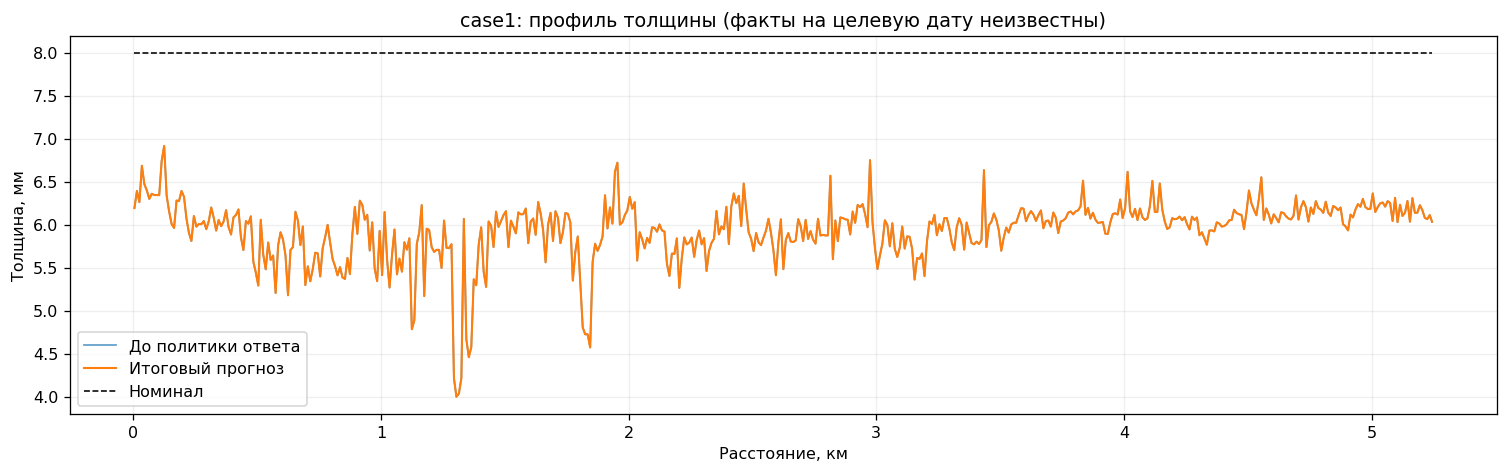

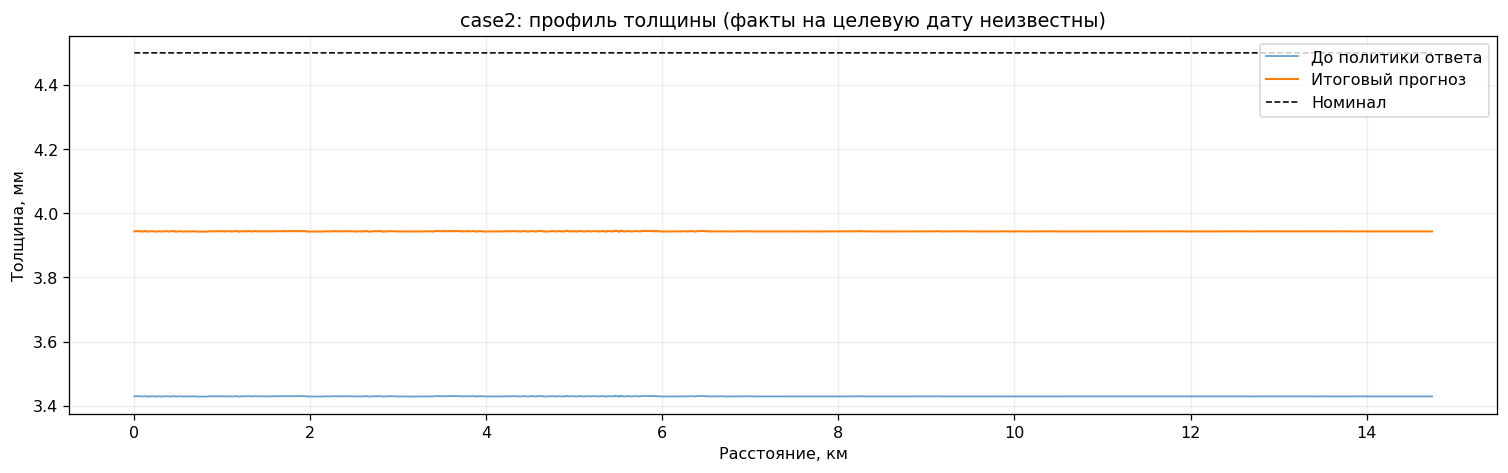

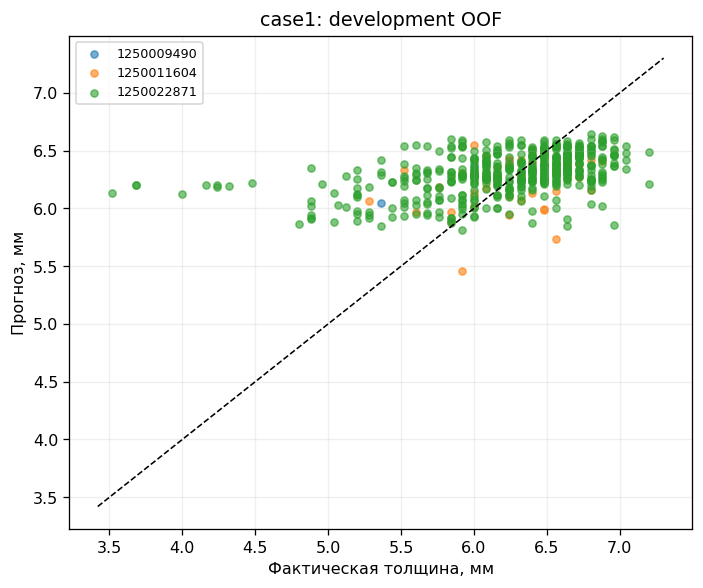

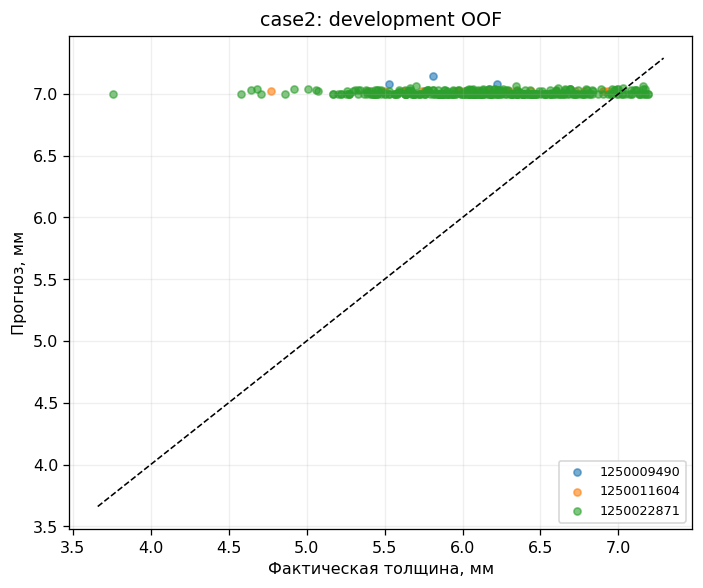

,scope,Thin10_MAE_mm,Thin10_bias_mm,n,MAE_mm,RMSE_mm,Pearson_r,Pearson_r2,R2,Bias_mm,P90_AE_mm
0,all,0.717143,0.717143,53,0.300098,0.395441,0.259791,0.067491,-0.001946,0.051119,0.560839
1,1250009490,0.562033,0.562033,5,0.556679,0.651456,0.431229,0.185958,-2.095601,0.556679,0.916305
2,1250011604,0.572831,0.572831,48,0.273370,0.358406,0.235271,0.055352,-0.038708,-0.001543,0.520881


In [65]:
ADDITIONAL = FINAL_RUN_DIR / "additional"
ADDITIONAL.mkdir(exist_ok=True)
for case_name, part in FINAL_PREDICTION_FRAME.groupby("case", sort=False):
    fig, ax = plt.subplots(figsize=(13, 4), constrained_layout=True)
    ax.plot(part["mid_m"] / 1000, part["prediction_raw_mm"], label="До политики ответа", lw=1.1, alpha=.7)
    ax.plot(part["mid_m"] / 1000, part["thickness_pred"], label="Итоговый прогноз", lw=1.3)
    ax.plot(part["mid_m"] / 1000, part["nominal_mm"], "k--", label="Номинал", lw=1)
    ax.set(title=case_name + ": профиль толщины (факты на целевую дату неизвестны)", xlabel="Расстояние, км", ylabel="Толщина, мм")
    ax.legend()
    ax.grid(alpha=.2)
    fig.savefig(ADDITIONAL / f"thickness_profile_{case_name}.png", dpi=160)
    plt.show()
if not OOF.empty:
    for case_name, part in OOF.loc[OOF["approach"].eq("Selected_model_final")].groupby("case", sort=False):
        fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
        for sid, g in part.groupby("id"):
            ax.scatter(g[TARGET], g["prediction_mm"], label=str(sid), s=20, alpha=.6)
        lo = min(part[TARGET].min(), part["prediction_mm"].min()) - .1
        hi = max(part[TARGET].max(), part["prediction_mm"].max()) + .1
        ax.plot([lo, hi], [lo, hi], "k--", lw=1)
        ax.set(title=case_name + ": development OOF", xlabel="Фактическая толщина, мм", ylabel="Прогноз, мм")
        ax.legend(fontsize=8)
        ax.grid(alpha=.2)
        fig.savefig(ADDITIONAL / f"prediction_vs_fact_{case_name}.png", dpi=160)
        plt.show()

if FINAL_CFG["run_temporal_control"]:
    hist_x = pd.read_parquet(PROCESSED / "features/historical_X.parquet")
    hist_y = pd.read_parquet(PROCESSED / "labels/historical_y.parquet")
    t1 = pd.Timestamp(PREP_CFG["cases"]["case1"]["target_date"])
    held_y = hist_y.loc[hist_y["mode"].eq("between") & hist_y["target_date"].eq(t1)
        & hist_y["id"].ne(PREP_CFG["cases"]["case1"]["id"]) & hist_y["has_label"], JOIN_KEYS + [TARGET]]
    temporal_meta = hist_x.merge(held_y, on=JOIN_KEYS, how="inner", validate="one_to_one").reset_index(drop=True)
    if not temporal_meta.empty:
        if set(temporal_meta["episode_id"]).intersection(set(CASES["case1"]["data"]["episode_id"])):
            raise ValueError("Временной контроль пересекается с обучающими эпизодами")
        control = predict_final_case("case1", temporal_meta)
        temporal_meta["prediction_mm"] = control["thickness_pred"].to_numpy(float)
        save_frame(ADDITIONAL / "temporal_control_case1.parquet", temporal_meta)
        rows = [{"scope": "all", **metrics_mm(temporal_meta[TARGET], temporal_meta["prediction_mm"])}]
        rows += [{"scope": str(sid), **metrics_mm(g[TARGET], g["prediction_mm"])} for sid, g in temporal_meta.groupby("id")]
        save_frame(ADDITIONAL / "temporal_control_case1_metrics.csv", pd.DataFrame(rows))
        display(pd.DataFrame(rows))
    else:
        print("Временные контрольные метки case1 отсутствуют — пропускаем этот контроль.")

### 10% наиболее истончённых сегментов

In [66]:
if FINAL_CFG["make_rankings"]:
    for case_name, part in FINAL_PREDICTION_FRAME.groupby("case", sort=False):
        ranking = part.copy()
        ranking["remaining_fraction"] = ranking["thickness_pred"] / ranking["nominal_mm"]
        ranking["predicted_loss_fraction"] = 1 - ranking["remaining_fraction"]
        ranking = ranking.sort_values(["remaining_fraction", "id", "segment_id"], kind="stable").reset_index(drop=True)
        ranking.insert(0, "priority_rank", np.arange(1, len(ranking) + 1))
        count = int(np.ceil(.10 * len(ranking)))
        ranking["top10_percent"] = ranking["priority_rank"].le(count)
        save_frame(ADDITIONAL / f"ranking_all_{case_name}.csv", ranking)
        save_frame(ADDITIONAL / f"top10_percent_{case_name}.csv", ranking.head(count))
        print(case_name, ":", count, "из", len(ranking), "сегментов")
        display(ranking.head(min(10, count))[["priority_rank", "id", "segment_id", "start_m", "end_m", "thickness_pred", "remaining_fraction"]])

case1 : 53 из 525 сегментов


,priority_rank,id,segment_id,start_m,end_m,thickness_pred,remaining_fraction
0,1,1250022871,130,1300.0,1310.0,3.997573,0.499697
1,2,1250022871,131,1310.0,1320.0,4.033857,0.504232
2,3,1250022871,129,1290.0,1300.0,4.211842,0.526480
3,4,1250022871,132,1320.0,1330.0,4.213656,0.526707
4,5,1250022871,135,1350.0,1360.0,4.457230,0.557154
5,6,1250022871,184,1840.0,1850.0,4.570719,0.571340
6,7,1250022871,136,1360.0,1370.0,4.575531,0.571941
7,8,1250022871,134,1340.0,1350.0,4.667733,0.583467
8,9,1250022871,183,1830.0,1840.0,4.723944,0.590493
9,10,1250022871,182,1820.0,1830.0,4.724130,0.590516


case2 : 148 из 1475 сегментов


,priority_rank,id,segment_id,start_m,end_m,thickness_pred,remaining_fraction
0,1,1250009583,551,5510.0,5520.0,3.942274,0.876061
1,2,1250009583,79,790.0,800.0,3.942736,0.876164
2,3,1250009583,78,780.0,790.0,3.942738,0.876164
3,4,1250009583,80,800.0,810.0,3.942753,0.876167
4,5,1250009583,81,810.0,820.0,3.942754,0.876168
5,6,1250009583,48,480.0,490.0,3.942782,0.876174
6,7,1250009583,118,1180.0,1190.0,3.942785,0.876174
7,8,1250009583,73,730.0,740.0,3.942786,0.876175
8,9,1250009583,536,5360.0,5370.0,3.942808,0.876180
9,10,1250009583,23,230.0,240.0,3.942822,0.876183


### Неопределённость

Диагностические OOF-полосы; покрытие не гарантировано.

In [67]:
if FINAL_CFG["make_diagnostic_intervals"]:
    if OOF.empty:
        print("Нет OOF-остатков: диагностические полосы не рассчитываются.")
    else:
        for case_name, g in OOF.loc[OOF["approach"].eq("Selected_model_final")].groupby("case", sort=False):
            residual_fraction = (g[TARGET].to_numpy(float) - g["prediction_mm"].to_numpy(float)) / g["nominal_mm"].to_numpy(float)
            q10, q90 = np.quantile(residual_fraction, [.10, .90])
            out = FINAL_PREDICTION_FRAME.loc[FINAL_PREDICTION_FRAME["case"].eq(case_name)].copy()
            nominal = out["nominal_mm"].to_numpy(float)
            out["empirical_residual_lower_mm"] = np.clip(out["thickness_pred"] + nominal * q10, 0, nominal)
            out["empirical_residual_upper_mm"] = np.clip(out["thickness_pred"] + nominal * q90, 0, nominal)
            out["interval_kind"] = "development_OOF_empirical_residual_band_not_calibrated"
            save_frame(ADDITIONAL / f"diagnostic_intervals_{case_name}.csv", out)
            save_json(ADDITIONAL / f"diagnostic_intervals_{case_name}.json", {"residual_fraction_q10": q10, "residual_fraction_q90": q90,
                "n_residuals": len(g), "independent_sections": g["id"].nunique(), "coverage_guaranteed": False,
                "note": "Эмпирическая диагностическая полоса, не доказанный 80% интервал"})
else:
    print("Диагностические интервалы отключены: вместо неподтверждённых чисел дано описание выше.")

Диагностические интервалы отключены: вместо неподтверждённых чисел дано описание выше.


### Файлы

`result_case1.csv` и `result_case2.csv` в каталоге запуска.

In [68]:
for row in source_manifest.itertuples(index=False):
    source_path = DATA_DIR / row.filename
    if hashlib.sha256(source_path.read_bytes()).hexdigest() != row.sha256:
        raise RuntimeError("Исходный CSV изменился во время выполнения: " + row.filename)
save_json(RUN_DIR / "inference_audit.json", INFERENCE_AUDIT)
manifest_rows = []
for path in sorted(FINAL_RUN_DIR.rglob("*")):
    if path.is_file() and path.name != "final_manifest.csv":
        manifest_rows.append({"file": path.relative_to(FINAL_RUN_DIR).as_posix(), "bytes": path.stat().st_size,
                              "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
pd.DataFrame(manifest_rows).to_csv(FINAL_RUN_DIR / "final_manifest.csv", index=False, encoding="utf-8-sig")
print("Case 1:", FINAL_RUN_DIR / "result_case1.csv")
print("Case 2:", FINAL_RUN_DIR / "result_case2.csv")
print("Модели:", RUN_DIR / "models")
print("Дополнительные материалы:", ADDITIONAL)
print("Seed:", SEED, "; записей в манифесте:", len(manifest_rows))

Case 1: C:\Users\msi_katana\Desktop\ML\nedra-digital\final_runs\final_20261115_213822_756881\result_case1.csv
Case 2: C:\Users\msi_katana\Desktop\ML\nedra-digital\final_runs\final_20261115_213822_756881\result_case2.csv
Модели: C:\Users\msi_katana\Desktop\ML\nedra-digital\final_runs\final_20261115_213822_756881\training\models
Дополнительные материалы: C:\Users\msi_katana\Desktop\ML\nedra-digital\final_runs\final_20261115_213822_756881\additional
Seed: 42 ; записей в манифесте: 123
